# 07 Statistical Modelling 2: Residual Gradient Boosted Tree
This notebook fits a residual Gradient Boosted Tree (GBT) model for FHVHV average wait time. The model first removes a 2025 historical zone-hour wait-time baseline, then predicts the residual (remaining log-scale deviation) using spatial, temporal, disruption, weather, and historical demand features.

- We aim for the GBT model to improve predictive performance over the weighted linear regression model built in `06_statistical_modelling_1.ipynb`.
- We predict the residual deviation from historical zone-hour `avg_wait_time_fhvhv`, then convert predictions back to wait time in seconds.
- Predictors include:
    - categorical: `PULocationID`, `borough`, `month_num`, `hour_of_week`
    - numeric: `n_stations`, `weather_severity`, `has_alert`, `n_alerts`, `disruption_severity`, borough-alert interactions, borough-severity interactions, 2025 historical wait-time baseline, 2025 historical FHVHV demand baseline, and 2025 historical subway ridership baseline
- Same-hour `n_trips_fhvhv`, `ridership`, `log_fhvhv_demand`, and `log_ridership` are excluded from the final predictors to avoid using information that would not be known at prediction time.
- We use Jan-Dec 2025 as training data and Jan-May 2026 as the temporal test set.
- We evaluate overall performance, alert-row performance, high-severity performance, borough-level errors, and candidate dispatch-priority zone-hours.

In [1]:
# Restart spark if required
try:
    spark.stop()
except NameError:
    pass
except Exception:
    pass

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder.appName("MAST30034 Project 1")
    .config("spark.sql.repl.eagerEval.enabled", True)
    .config("spark.sql.parquet.cacheMetadata", "true")
    .config("spark.sql.session.timeZone", "America/New_York")
    .config("spark.driver.memory", "8g")
    .config("spark.executor.memory", "8g")
    .config("spark.driver.maxResultSize", "2g")
    .getOrCreate()
)

spark.conf.set("spark.sql.shuffle.partitions", "64")
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.sparkContext.setLogLevel("ERROR")


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/08/31 13:37:27 WARN Utils: Your hostname, Hannahs-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 172.30.204.34 instead (on interface en0)
26/08/31 13:37:27 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/08/31 13:37:28 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Setup and Configuration

Load PySpark, modelling tools, and plotting libraries. The Spark session uses New York time because all TLC/MTA timestamps describe New York operations.


In [2]:
from pyspark.sql import functions as F

from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

from pyspark.storagelevel import StorageLevel


# Specify borough palette for visualisation consistency
borough_palette = {
    "Bronx": "#1f77b4",
    "Brooklyn": "#ff7f0e",
    "Manhattan": "#2ca02c",
    "Queens": "#d62728",
    "Staten Island": "#9467bd",
}

# Input directories from `03_feature_engineering.ipynb`
features_dir = "../data/features"

# Output directories for `05_exploratory_analysis.ipynb`
analysis_dir = "../data/analysis"


In [3]:
# load feature table
sdf_tlc_hourly = spark.read.parquet(f"{analysis_dir}/tlc_zone_hourly_temporal")
sdf_tlc_hourly.show(5)


+-------------------+------------+------------+---------------+-------------+----------------+-------------------+---------+----------------+----------+---------+--------+-------------------+----+----------------+-------------------+-----------+-----------+----------------------------+------------+
|               hour|PULocationID|n_trips_taxi|gross_fare_taxi|n_trips_fhvhv|gross_fare_fhvhv|avg_wait_time_fhvhv|  borough|       taxi_zone|n_stations|ridership|n_alerts|disruption_severity|coco|weather_severity|              month|hour_of_day|day_of_week|avg_wait_time_fhvhv_no_alert|hour_of_week|
+-------------------+------------+------------+---------------+-------------+----------------+-------------------+---------+----------------+----------+---------+--------+-------------------+----+----------------+-------------------+-----------+-----------+----------------------------+------------+
|2026-03-26 17:00:00|          94|           0|           0.00|           81|         1873.83|      

## Preparing inputs for `pyspark.ml` Gradient Boost Tree Modelling

The response is `avg_wait_time_fhvhv`. We model `log1p(avg_wait_time_fhvhv)` because wait times are positive and right-skewed. `log1p` is almost identical to `log` at normal wait-time values, but it is robust if a zero appears.

The model does not use same-hour 2026 FHVHV trips or same-hour 2026 subway ridership as predictors, because those values would not be known at prediction time. Instead, it uses historical 2025 zone-hour baselines for normal wait time, normal FHVHV demand, and normal subway ridership. These historical baselines are available before predicting 2026 and therefore do not leak test-period outcomes into the model.

Historical baselines are built from 2025 training data only. For each pickup zone and hour-of-week, we calculate typical log wait time, log FHVHV demand, and log subway ridership, then join these values back to the full modelling table. If an exact zone-hour baseline is missing (rare but possible), the code falls back to the zone-level 2025 average and then the global 2025 average, preventing sparse zone-hours from being dropped.

In [4]:
def add_borough_disruption_interactions(df):
    """
    Add alert and severity interaction columns using Manhattan as reference borough.
    """
    return (
        df
        .withColumn("alert_bronx", F.when(F.col("borough") == "Bronx", F.col("has_alert")).otherwise(0))
        .withColumn("alert_brooklyn", F.when(F.col("borough") == "Brooklyn", F.col("has_alert")).otherwise(0))
        .withColumn("alert_queens", F.when(F.col("borough") == "Queens", F.col("has_alert")).otherwise(0))
        .withColumn("severity_bronx", F.when(F.col("borough") == "Bronx", F.col("disruption_severity")).otherwise(0))
        .withColumn("severity_brooklyn", F.when(F.col("borough") == "Brooklyn", F.col("disruption_severity")).otherwise(0))
        .withColumn("severity_queens", F.when(F.col("borough") == "Queens", F.col("disruption_severity")).otherwise(0))
    )


# Keep only rows where the response variable is available
base_seed_df = (
    sdf_tlc_hourly
    .filter(F.col("avg_wait_time_fhvhv").isNotNull())
    # create temporal identifiers, alert indicators, and log-scale modelling fields
    .withColumn("year", F.year("hour"))
    .withColumn("month_num", F.date_format("hour", "MM"))
    .withColumn("hour_of_week", F.format_string("%03d", F.col("hour_of_week").cast("int")))
    .withColumn("PULocationID", F.format_string("%03d", F.col("PULocationID").cast("int")))
    .withColumn("has_alert", (F.col("n_alerts") > 0).cast("int"))
    # logged same-hour columns are retained for diagnostics and 2025 baseline building only, NOT used as predictors in the final model
    .withColumn("log_ridership", F.log1p("ridership"))
    .withColumn("log_fhvhv_demand", F.log1p("n_trips_fhvhv"))
    .withColumn("label_log_wait", F.log1p("avg_wait_time_fhvhv"))
)

# Build historical baselines from 2025 training data only.
train_seed_df = base_seed_df.filter(F.col("year") == 2025) # 2025 only!
zone_hour_baseline = (
    train_seed_df
    .groupBy("PULocationID", "hour_of_week")
    .agg(
        F.avg("label_log_wait").alias("hist_zone_hour_log_wait"),
        F.avg("log_fhvhv_demand").alias("hist_zone_hour_log_fhvhv_demand"),
        F.avg("log_ridership").alias("hist_zone_hour_log_ridership"),
        F.count("*").alias("hist_zone_hour_n_train")
    )
)

zone_baseline = (
    train_seed_df
    .groupBy("PULocationID")
    .agg(
        F.avg("label_log_wait").alias("hist_zone_log_wait"),
        F.avg("log_fhvhv_demand").alias("hist_zone_log_fhvhv_demand"),
        F.avg("log_ridership").alias("hist_zone_log_ridership")
    )
)

global_baseline = train_seed_df.agg(
    F.avg("label_log_wait").alias("global_log_wait"),
    F.avg("log_fhvhv_demand").alias("global_log_fhvhv_demand"),
    F.avg("log_ridership").alias("global_log_ridership")
).first()

# Join historical baselines back to all rows. 
# If a zone-hour baseline is unavailable, fall back to the zone average, then the global 2025 average
base_df = (
    base_seed_df
    .join(zone_hour_baseline, on=["PULocationID", "hour_of_week"], how="left")
    .join(zone_baseline, on="PULocationID", how="left")
    .withColumn(
        "hist_log_wait_baseline",
        F.coalesce(
            "hist_zone_hour_log_wait",
            "hist_zone_log_wait",
            F.lit(float(global_baseline["global_log_wait"]))
        )
    )
    .withColumn(
        "hist_log_fhvhv_demand_baseline",
        F.coalesce(
            "hist_zone_hour_log_fhvhv_demand",
            "hist_zone_log_fhvhv_demand",
            F.lit(float(global_baseline["global_log_fhvhv_demand"]))
        )
    )
    .withColumn(
        "hist_log_ridership_baseline",
        F.coalesce(
            "hist_zone_hour_log_ridership",
            "hist_zone_log_ridership",
            F.lit(float(global_baseline["global_log_ridership"]))
        )
    )
    .withColumn("hist_zone_hour_n_train", F.coalesce("hist_zone_hour_n_train", F.lit(0)))
    .drop(
        "hist_zone_hour_log_wait", "hist_zone_log_wait",
        "hist_zone_hour_log_fhvhv_demand", "hist_zone_log_fhvhv_demand",
        "hist_zone_hour_log_ridership", "hist_zone_log_ridership"
    )
)

base_df = add_borough_disruption_interactions(base_df)
base_df.select(
    "hour", "PULocationID", "taxi_zone", "borough", "avg_wait_time_fhvhv",
    "hist_log_wait_baseline", "hist_log_fhvhv_demand_baseline", "hist_log_ridership_baseline",
    "has_alert", "n_alerts", "disruption_severity"
).show(5, truncate=False)


+-------------------+------------+------------------------+---------+-------------------+----------------------+------------------------------+---------------------------+---------+--------+-------------------+
|hour               |PULocationID|taxi_zone               |borough  |avg_wait_time_fhvhv|hist_log_wait_baseline|hist_log_fhvhv_demand_baseline|hist_log_ridership_baseline|has_alert|n_alerts|disruption_severity|
+-------------------+------------+------------------------+---------+-------------------+----------------------+------------------------------+---------------------------+---------+--------+-------------------+
|2025-01-01 00:00:00|017         |Bedford                 |Brooklyn |412.05             |5.413025442468333     |4.875674629113832             |4.753668554013671          |0        |0       |0                  |
|2025-09-14 15:00:00|068         |East Chelsea            |Manhattan|302.83             |5.475118934800741     |5.777241563762464             |7.88585838322

In [5]:
# Split train and test
train_base = base_df.filter(F.col("year") == 2025).withColumn("split", F.lit("2025 train"))
test_base = base_df.filter(F.col("year") == 2026).withColumn("split", F.lit("2026 test"))

n_alert_train = train_base.filter(F.col("has_alert") == 1).count()
n_no_alert_train = train_base.filter(F.col("has_alert") == 0).count()
alert_weight = n_no_alert_train / n_alert_train

# Weigh alert rows since they are rare 
train_base = train_base.withColumn(
    "sample_weight",
    F.when(F.col("has_alert") == 1, F.lit(alert_weight)).otherwise(F.lit(1.0))
)
test_base = test_base.withColumn("sample_weight", F.lit(1.0))

print(f"Training rows:          {train_base.count():,}")
print(f"Test rows:              {test_base.count():,}")
print(f"Alert training rows:    {n_alert_train:,}")
print(f"No-alert training rows: {n_no_alert_train:,}")
print(f"Alert row weight:       {alert_weight:.2f}")


Training rows:          1,328,023
Test rows:              549,397
Alert training rows:    34,076
No-alert training rows: 1,293,947
Alert row weight:       37.97


## Evaluation and Plotting Helpers

The metric tables below are calculated on **individual zone-hour rows**. For example, the 2026 test MAE/RMSE/R^2 rows evaluate every zone-hour prediction separately, not an average hour-of-week curve.

The plots usually aggregate predictions after the model has already predicted each zone-hour row. Those plots are therefore diagnostic visual summaries, not the data used to calculate the reported metrics.

In [6]:
def evaluate_slice(pred_df, name, prediction_col="pred_wait_seconds"):
    """
    Evaluate log-scale and seconds-scale prediction performance metrics for given data slice (train / test / subsets)
    """
    n_rows = pred_df.count()
    if n_rows == 0:
        return {"slice": name, "n_rows": 0, "rmse_log": np.nan, "mae_log": np.nan, "r2_log": np.nan, "rmse_seconds": np.nan, "mae_seconds": np.nan, "r2_seconds": np.nan}
    return {
        "slice": name,
        "n_rows": n_rows,
        "rmse_log": RegressionEvaluator(labelCol="label_log_wait", predictionCol="pred_log_wait", metricName="rmse").evaluate(pred_df),
        "mae_log": RegressionEvaluator(labelCol="label_log_wait", predictionCol="pred_log_wait", metricName="mae").evaluate(pred_df),
        "r2_log": RegressionEvaluator(labelCol="label_log_wait", predictionCol="pred_log_wait", metricName="r2").evaluate(pred_df),
        "rmse_seconds": RegressionEvaluator(labelCol="avg_wait_time_fhvhv", predictionCol=prediction_col, metricName="rmse").evaluate(pred_df),
        "mae_seconds": RegressionEvaluator(labelCol="avg_wait_time_fhvhv", predictionCol=prediction_col, metricName="mae").evaluate(pred_df),
        "r2_seconds": RegressionEvaluator(labelCol="avg_wait_time_fhvhv", predictionCol=prediction_col, metricName="r2").evaluate(pred_df),
    }

In [7]:
def plot_hour_of_week_actual_vs_pred(pred_df, title, prediction_col="pred_wait_seconds"):
    """
    Plot borough-faceted actual vs predicted mean wait time by hour-of-week.
    Predictions are averaged after scoring for diagnostic summary plot.
    """
    # Average predictions and labels only for visual readability
    plot_pd = (
        pred_df
        .groupBy("borough", "hour_of_week")
        .agg(
            F.avg("avg_wait_time_fhvhv").alias("actual_wait_seconds"),
            F.avg(prediction_col).alias("pred_wait_seconds"),
            F.count("*").alias("n_rows")
        )
        .toPandas()
    )

    plot_pd["hour_of_week_int"] = plot_pd["hour_of_week"].astype(int)

    # Convert wide dataframe to long (by giving actual and pred rows per borough-how-rows)
    plot_long = plot_pd.melt(
        id_vars=["borough", "hour_of_week_int", "n_rows"],
        value_vars=["actual_wait_seconds", "pred_wait_seconds"],
        var_name="series",
        value_name="wait_seconds"
    )
    plot_long["series"] = plot_long["series"].map({
        "actual_wait_seconds": "Actual wait time",
        "pred_wait_seconds": "Predicted wait time",
    })

    # Specify borough order for consistency 
    borough_order = ["Manhattan", "Bronx", "Brooklyn", "Queens"]
    fig, axes = plt.subplots(2, 2, figsize=(14, 7), dpi=160, sharex=True, sharey=True)
    axes = axes.flatten()

    for ax, borough in zip(axes, borough_order):
        borough_pd = plot_long[plot_long["borough"] == borough]
        sns.lineplot(
            data=borough_pd,
            x="hour_of_week_int",
            y="wait_seconds",
            hue="series",
            style="series",
            dashes={"Actual wait time": "", "Predicted wait time": (4, 2)},
            palette={"Actual wait time": "#1f77b4", "Predicted wait time": "#ff7f0e"},
            linewidth=1.5,
            ax=ax,
        )
        ax.set_title(borough)
        ax.set_xlabel("Hour of week")
        ax.set_ylabel("Mean wait time (seconds)")
        ax.set_xticks([0, 24, 48, 72, 96, 120, 144, 168])
        ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun", "Mon"])
        ax.grid(axis="both", alpha=0.2)

        # day boundary markers make the weekly cycle easier to read
        for x in [24, 48, 72, 96, 120, 144]:
            ax.axvline(x, color="0.85", linewidth=0.8)
        if ax.get_legend() is not None:
            ax.get_legend().remove()

    handles, labels = axes[0].get_legend_handles_labels()
    fig.suptitle(title, fontsize=13, y=1.02)
    fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.99))
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


## Fit and Evaluate Residual Gradient Boost Tree Model 

This is a residual gradient-boosted tree model. The model first removes the usual historical zone-hour pattern, then learns the remaining deviation.

For row $i$, let $W_i$ be the observed FHVHV average wait time in seconds and let $B_i$ be the 2025 historical baseline log wait for the same pickup-zone and hour-of-week pattern. The training target is:

$$
y_i^{resid} = \log(1 + W_i) - B_i
$$

The GBT predicts this residual:

$$
\widehat{y}_i^{resid} = f(X_i)
$$

Then the predicted log wait is reconstructed as:

$$
\widehat{\log(1 + W_i)} = B_i + \widehat{y}_i^{resid}
$$

Because predictions are made on the log scale, directly applying $\exp(\widehat{\log(1+W_i)}) - 1$ can underestimate mean wait time on the original seconds scale. The notebook therefore estimates a **smearing factor** from the 2025 training residuals only and applies it when converting predictions back to seconds. This avoids using 2026 test outcomes while partially correcting log-to-seconds retransformation bias.

To keep the test setup realistic, the final feature set excludes same-hour `n_trips_fhvhv`, same-hour `ridership`, `log_fhvhv_demand`, and `log_ridership`. The model only uses zone, borough, calendar/time features, station/weather/alert attributes, and historical 2025 baselines. If weather is not assumed to be forecastable at prediction time, set `USE_FORECASTABLE_WEATHER = False`.

In [8]:
# Set to TRUE if we want to allow using weather at prediction time as a predictor 
# Set to FALSE to exclude weather predictor completely 
USE_FORECASTABLE_WEATHER = True

# Categorical predictors for index and one-hot-encoding 
categorical_cols = ["PULocationID", "borough", "month_num", "hour_of_week"]

# Prediction-time-plausible numeric inputs. Historical baselines are built from 2025 only
numeric_cols = [
    "n_stations",
    "has_alert", "n_alerts", "disruption_severity",
    "alert_bronx", "alert_brooklyn", "alert_queens",
    "severity_bronx", "severity_brooklyn", "severity_queens",
    "hist_log_wait_baseline", "hist_log_fhvhv_demand_baseline", "hist_log_ridership_baseline", "hist_zone_hour_n_train",
]

if USE_FORECASTABLE_WEATHER:
    numeric_cols.insert(1, "weather_severity")

# For predictions, exclude predictors which can't be known at prediction time for model practicality
excluded_same_hour_predictors = ["n_trips_fhvhv", "ridership", "log_fhvhv_demand", "log_ridership"]
print("Excluded same-hour predictors to avoid operational leakage:", excluded_same_hour_predictors)
print("Using weather as predictor:", USE_FORECASTABLE_WEATHER)

# Index and one-hot-encode categorical columns
indexers = [StringIndexer(inputCol=col, outputCol=f"{col}_idx", handleInvalid="keep") for col in categorical_cols]
encoders = [OneHotEncoder(inputCol=f"{col}_idx", outputCol=f"{col}_oh", dropLast=True) for col in categorical_cols]


Excluded same-hour predictors to avoid operational leakage: ['n_trips_fhvhv', 'ridership', 'log_fhvhv_demand', 'log_ridership']
Using weather as predictor: True


In [9]:
# Train GBT on deviations from the historical zone-hour wait baseline
residual_train_base = train_base.withColumn(
    "label_log_wait_residual",
    F.col("label_log_wait") - F.col("hist_log_wait_baseline")
)

residual_test_base = test_base.withColumn(
    "label_log_wait_residual",
    F.col("label_log_wait") - F.col("hist_log_wait_baseline")
)

# Baseline is removed from label, so don't use as a predictor for the residual model
numeric_cols_residual = [
    col for col in numeric_cols
    if col not in ["hist_log_wait_baseline"]
]

# Combine numeric predictors and one-hot encoded categorical predictors
assembler_residual = VectorAssembler(
    inputCols=numeric_cols_residual + [f"{col}_oh" for col in categorical_cols],
    outputCol="features"
)

# Fit a weighted GBT to learn nonlinear residual patterns
gbt_residual = GBTRegressor(
    featuresCol="features",
    labelCol="label_log_wait_residual",
    predictionCol="pred_log_wait_residual",
    weightCol="sample_weight",
    maxIter=45,
    maxDepth=5,
    minInstancesPerNode=25,
    stepSize=0.06,
    subsamplingRate=0.8,
    seed=47,
)

pipeline_gbt_residual = Pipeline(stages=indexers + encoders + [assembler_residual, gbt_residual])
model_gbt_residual = pipeline_gbt_residual.fit(residual_train_base)

## Evaluating model fits and errors
Use metrics, plots, and summary tables to evaluate model fits and errors

In [10]:
def add_residual_prediction_columns(pred_df, smearing_factor=1.0):
    """
    Convert residual GBT predictions into final wait-time predictions.
    Adds log-scale predictions and seconds-scale predictions with smearing correction.
    """
    return (
        pred_df
        .withColumn("pred_log_wait", F.col("hist_log_wait_baseline") + F.col("pred_log_wait_residual"))
        .withColumn("pred_wait_seconds_raw", F.expm1("pred_log_wait"))
        .withColumn(
            "pred_wait_seconds_resid",
            F.greatest(F.exp("pred_log_wait") * F.lit(float(smearing_factor)) - F.lit(1.0), F.lit(0.0)) # smearing factor
        )
        .withColumn("pred_wait_seconds", F.col("pred_wait_seconds_resid"))
    )


# Keep only columns for evaluation and reporting 
prediction_keep_cols = [
    "hour", "PULocationID", "taxi_zone", "borough", "month_num", "hour_of_day", "day_of_week", "hour_of_week",
    "avg_wait_time_fhvhv", "label_log_wait", "hist_log_wait_baseline",
    "hist_log_fhvhv_demand_baseline", "hist_log_ridership_baseline", "hist_zone_hour_n_train",
    "has_alert", "n_alerts", "disruption_severity", "n_trips_fhvhv", "ridership",
]

def slim_model_predictions(pred_df):
    """
    Keep only evaluation/reporting columns; dropping features prevents large cached vectors from exhausting memory
    """
    return pred_df.select(*prediction_keep_cols, "pred_log_wait_residual")

pred_train_residual_raw = slim_model_predictions(model_gbt_residual.transform(residual_train_base))

# Smearing factor for converting log-scale predictions back to seconds.
# It is estimated from 2025 training residuals only: mean(exp(observed_log_wait - predicted_log_wait))
# Applying this factor reduces retransformation bias without using 2026 outcomes.
smearing_factor_residual = (
    pred_train_residual_raw
    .withColumn("pred_log_wait", F.col("hist_log_wait_baseline") + F.col("pred_log_wait_residual"))
    .withColumn("exp_resid", F.exp(F.col("label_log_wait") - F.col("pred_log_wait")))
    .agg(F.avg("exp_resid").alias("smearing_factor"))
    .first()["smearing_factor"]
)

# Convert fitted residual predictions back to final wait-time predictions.
pred_train_residual = add_residual_prediction_columns(
    pred_train_residual_raw, smearing_factor_residual
).persist(StorageLevel.MEMORY_AND_DISK)

# Score the 2026 test set, keep only needed columns, then cache for evaluation plots.
pred_test_residual = add_residual_prediction_columns(
    slim_model_predictions(model_gbt_residual.transform(residual_test_base)),
    smearing_factor_residual
).persist(StorageLevel.MEMORY_AND_DISK)

# Materialise predictions once so later plots/metrics do not repeatedly retrace the full Spark lineage.
print(f"Cached train predictions: {pred_train_residual.count():,}")
print(f"Cached test predictions:  {pred_test_residual.count():,}")
print(f"Residual GBT smearing factor, trained on 2025 only: {smearing_factor_residual:.4f}")

metrics_residual_pd = pd.DataFrame([
    evaluate_slice(pred_train_residual, "2025 train residual GBT"),
    evaluate_slice(pred_train_residual.filter(F.col("has_alert") == 1), "2025 alert residual GBT"),
    evaluate_slice(pred_train_residual.filter(F.col("disruption_severity") >= 3), "2025 high severity residual GBT"),
    evaluate_slice(pred_test_residual, "2026 test residual GBT"),
    evaluate_slice(pred_test_residual.filter(F.col("has_alert") == 1), "2026 alert residual GBT"),
    evaluate_slice(pred_test_residual.filter(F.col("disruption_severity") >= 3), "2026 high severity residual GBT"),
])

metrics_residual_pd

Cached train predictions: 1,328,023


Cached test predictions:  549,397
Residual GBT smearing factor, trained on 2025 only: 1.0112


,slice,n_rows,rmse_log,mae_log,r2_log,rmse_seconds,mae_seconds,r2_seconds
0,2025 train residual GBT,1328023,0.150103,0.108712,0.626107,51.691289,33.147730,0.588151
1,2025 alert residual GBT,34076,0.136702,0.101274,0.633608,44.832454,29.668095,0.589917
2,2025 high severity residual GBT,2730,0.135917,0.100152,0.648775,43.307171,29.795469,0.626484
3,2026 test residual GBT,549397,0.229600,0.168614,0.304792,89.046081,54.531309,0.274261
4,2026 alert residual GBT,16063,0.234390,0.169349,0.271150,92.648587,54.222086,0.219109
5,2026 high severity residual GBT,1575,0.294240,0.200072,0.243160,136.969940,72.861313,0.172363


### Error by borough, visualised
These plots compare actual and predicted mean wait time by hour-of-week. The first plot uses all 2026 rows; the second focuses on alert rows only. The alert-row plot is more directly aligned with the research question, but it is also noisier because the alert dataset is much smaller.

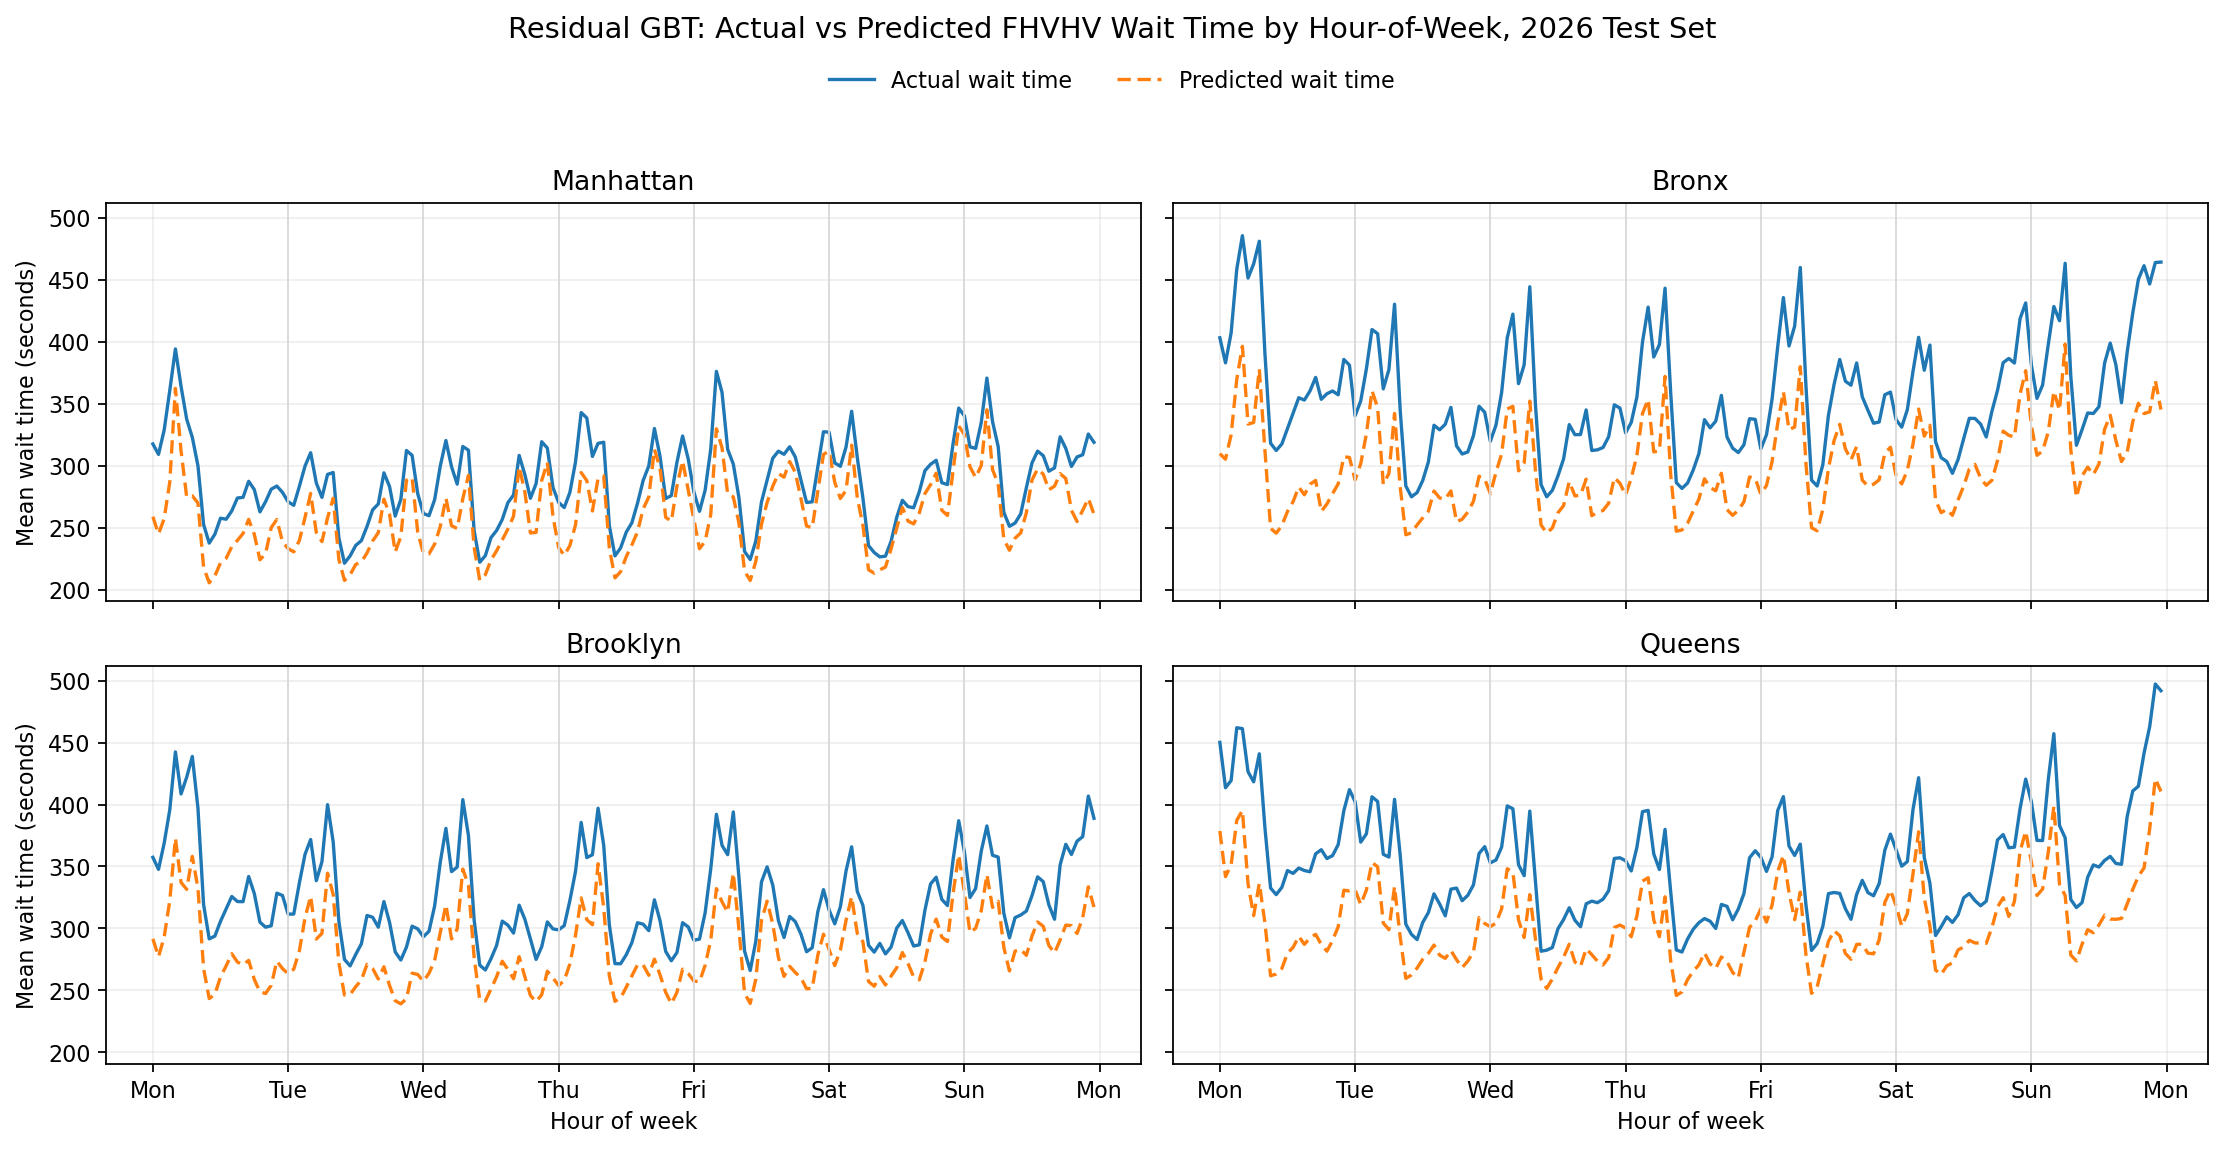

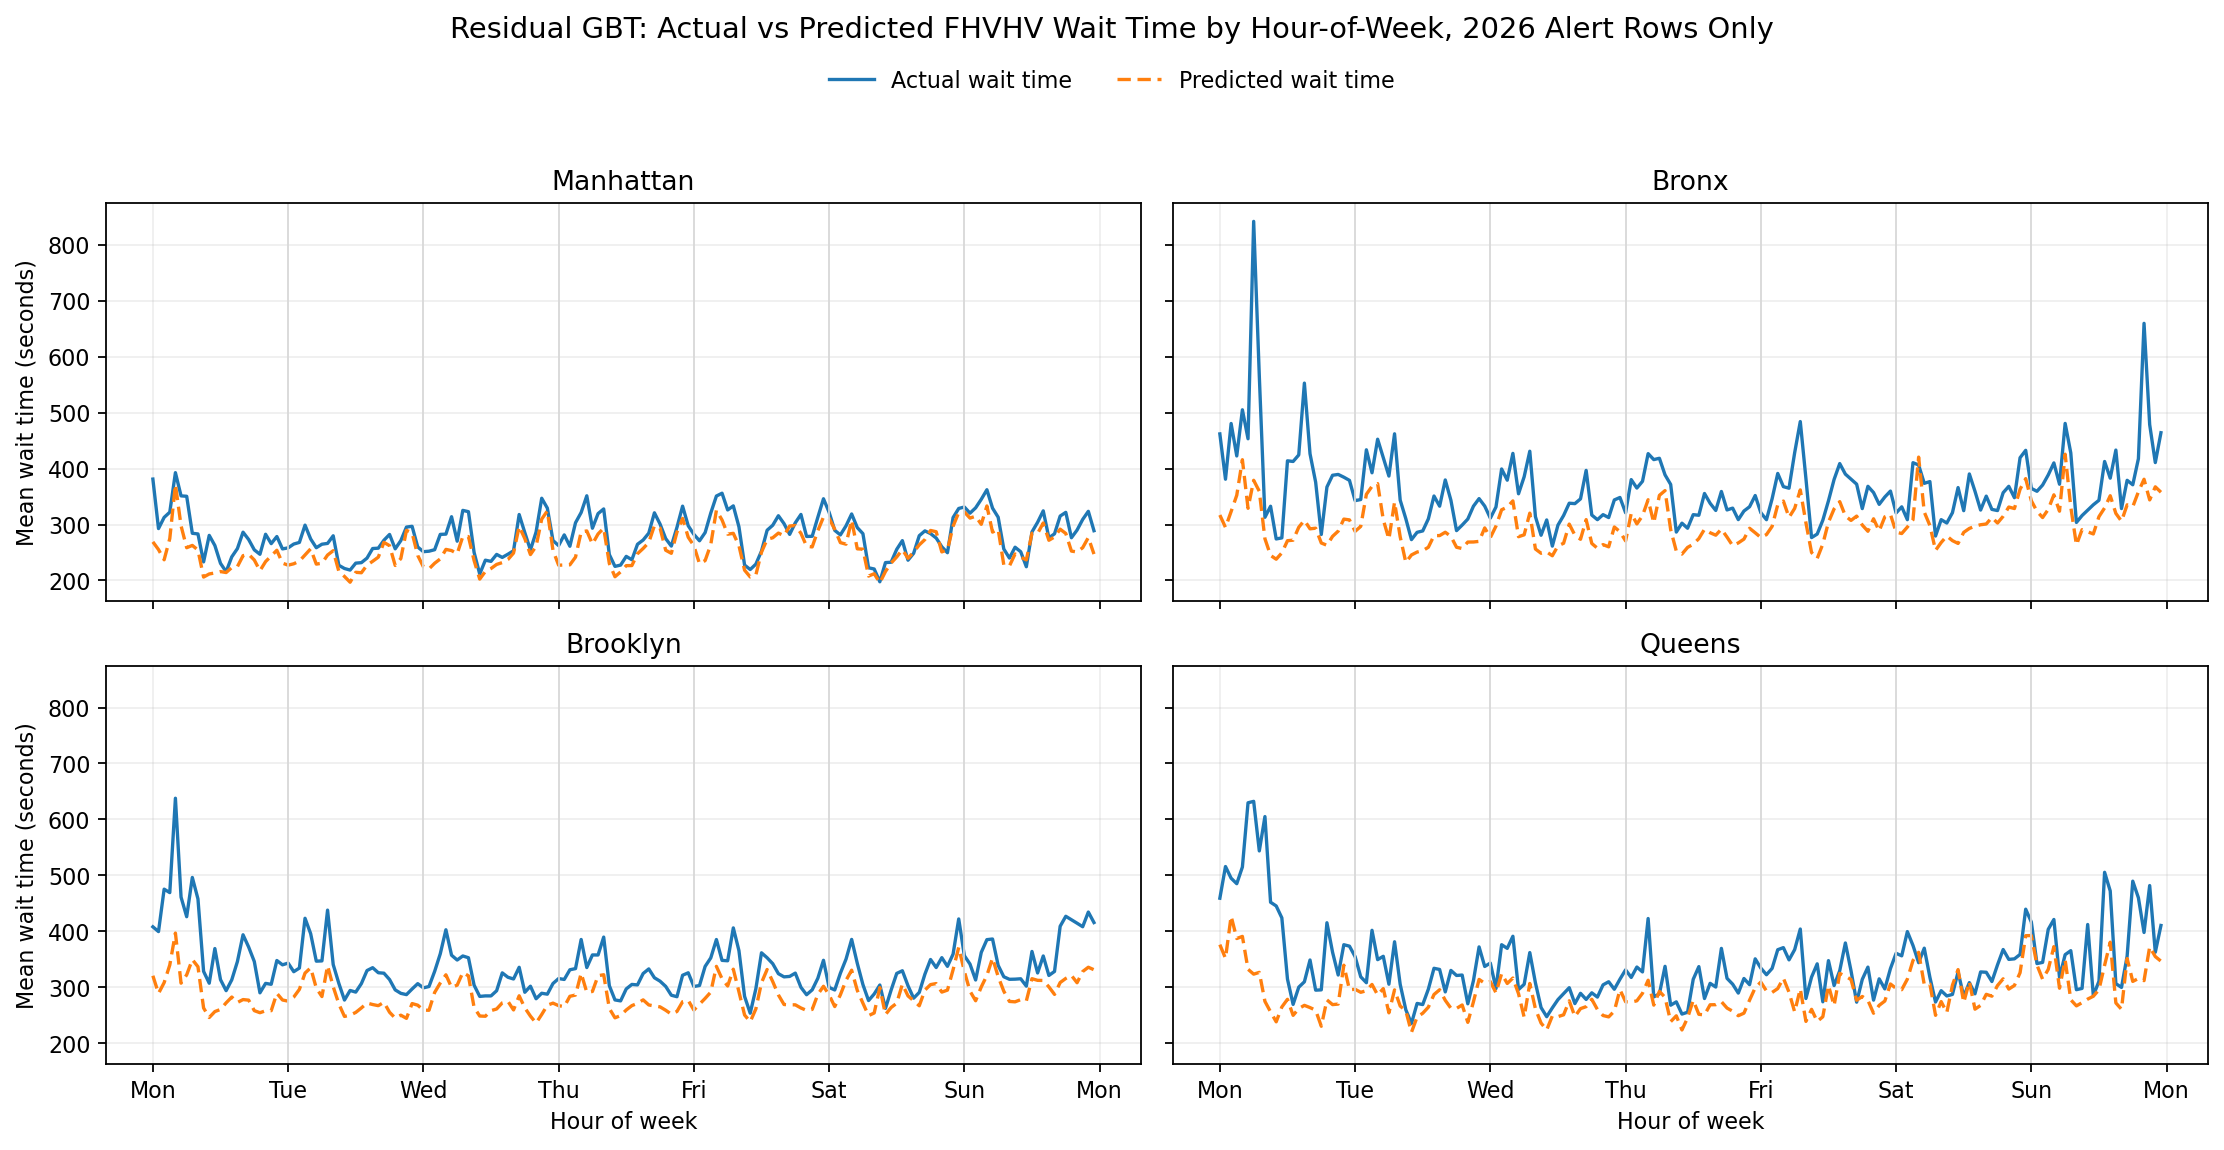

In [11]:
# Compare actual and predictions for full 2026 Test Set
plot_hour_of_week_actual_vs_pred(
    pred_test_residual,
    "Residual GBT: Actual vs Predicted FHVHV Wait Time by Hour-of-Week, 2026 Test Set",
    prediction_col="pred_wait_seconds_resid"
)

# Compare actual and predictions for 2026 Test Set Alert rows only
plot_hour_of_week_actual_vs_pred(
    pred_test_residual.filter(F.col("has_alert") == 1),
    "Residual GBT: Actual vs Predicted FHVHV Wait Time by Hour-of-Week, 2026 Alert Rows Only",
    prediction_col="pred_wait_seconds_resid"
)

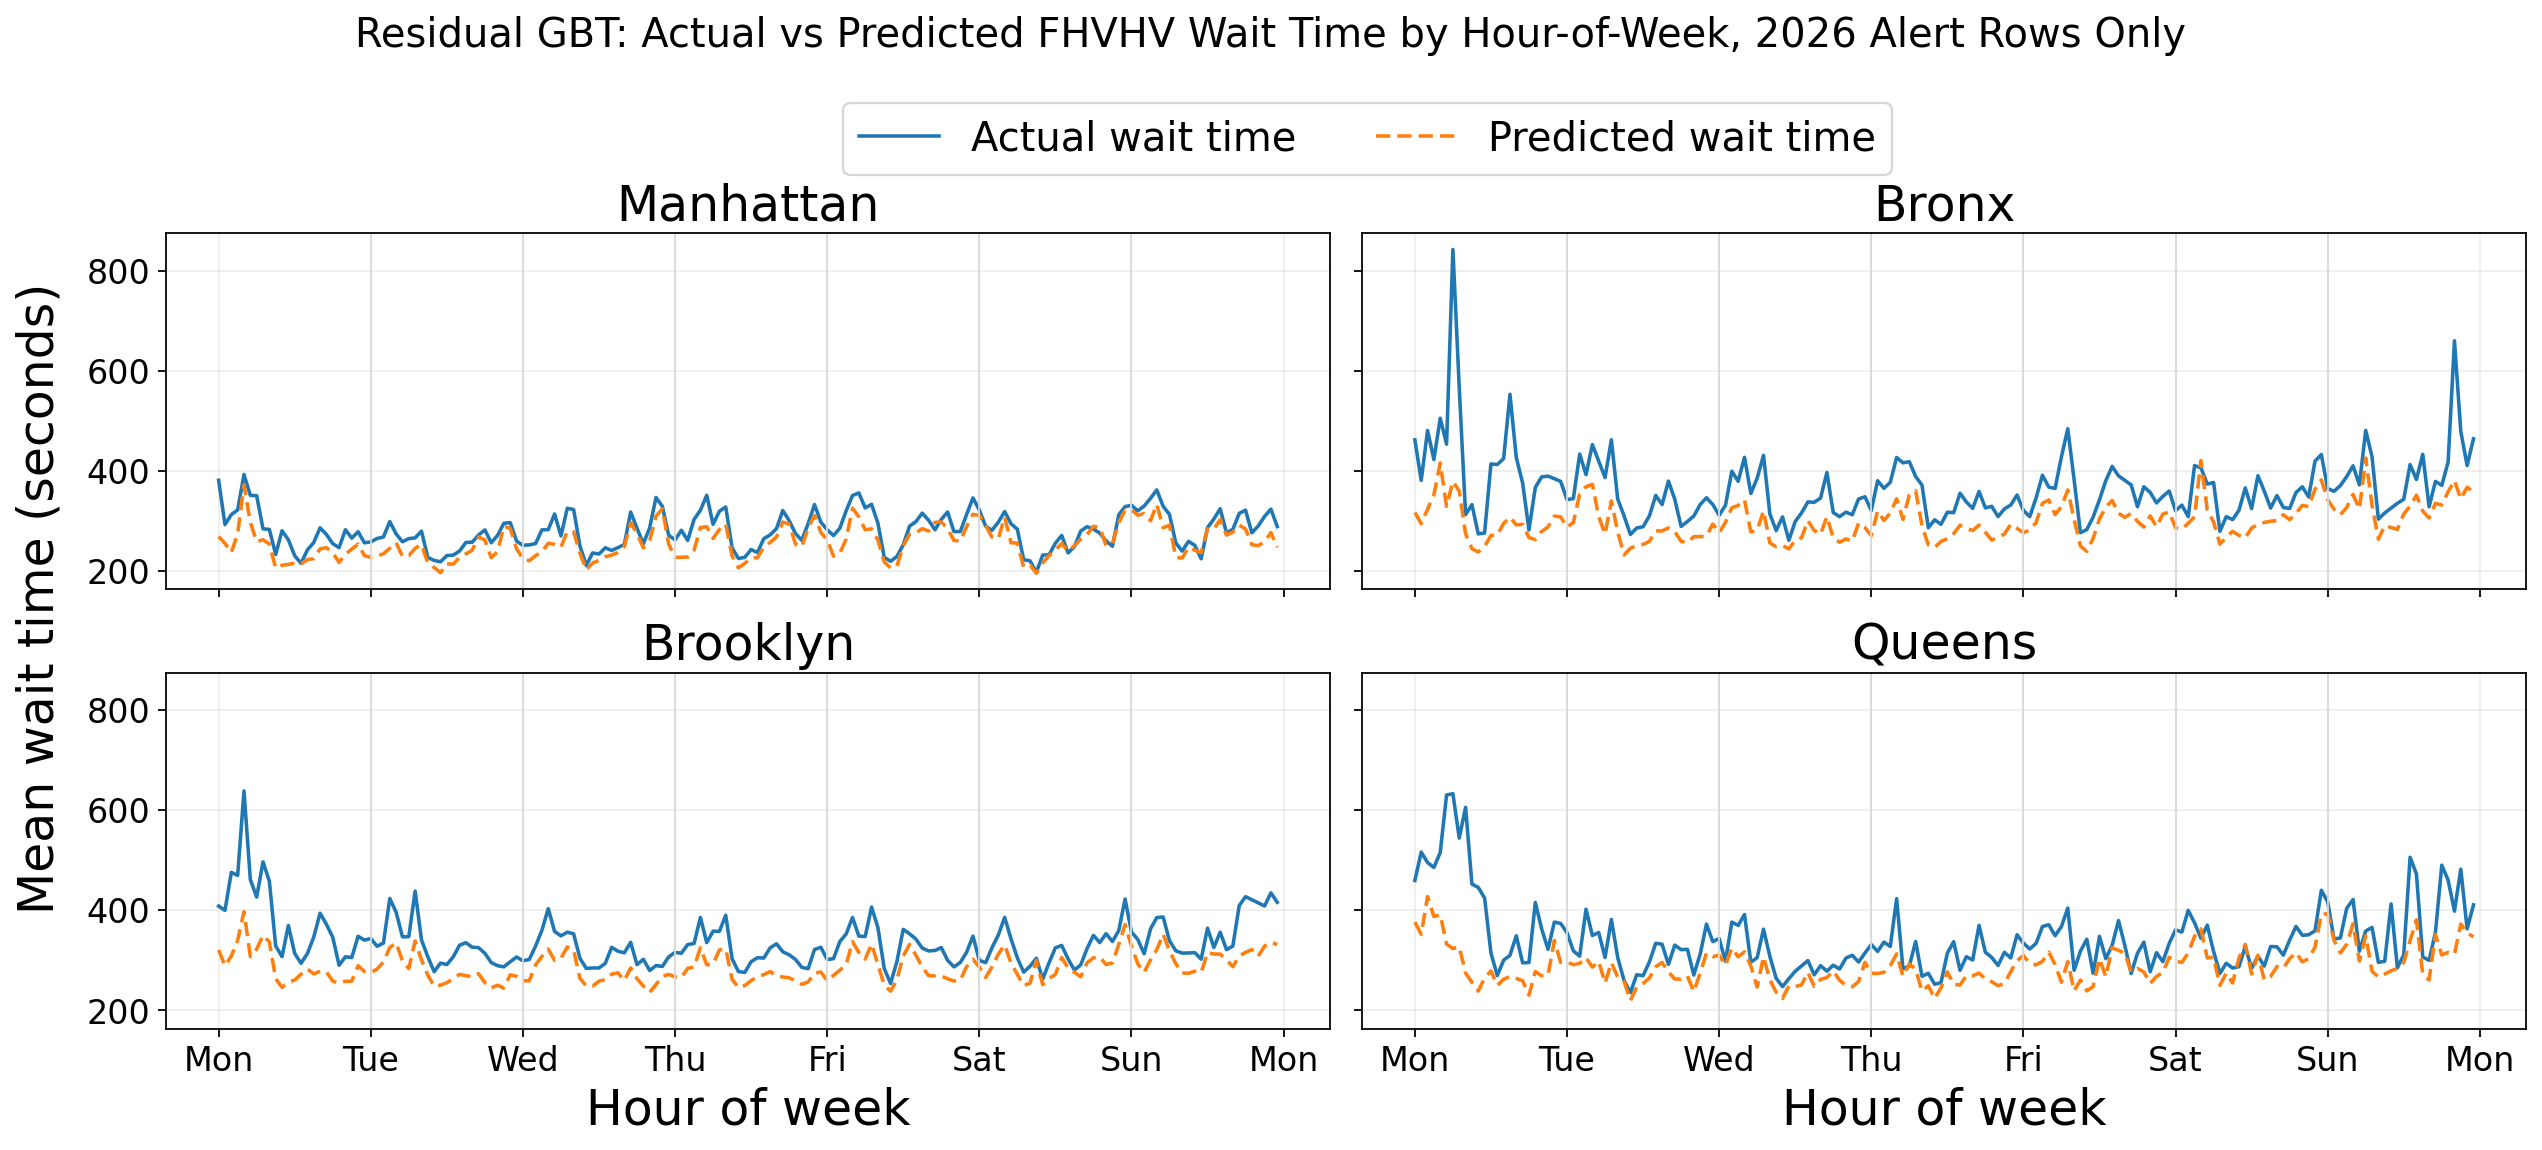

In [12]:
# More compact and readable plot for report!
def plot_hour_of_week_actual_vs_pred_compact(pred_df, title, prediction_col="pred_wait_seconds"):
    # Enlarge font sizes for readability 
    title_size = 18
    facet_title_size = 22
    label_size = 22
    tick_size = 15
    legend_size = 18

    # Average predictions and labels only for visual readability
    plot_pd = (
        pred_df
        .groupBy("borough", "hour_of_week")
        .agg(
            F.avg("avg_wait_time_fhvhv").alias("actual_wait_seconds"),
            F.avg(prediction_col).alias("pred_wait_seconds"),
            F.count("*").alias("n_rows")
        )
        .toPandas()
    )

    plot_pd["hour_of_week_int"] = plot_pd["hour_of_week"].astype(int)

    # Convert wide dataframe to long (by giving actual and pred rows per borough-how-rows)
    plot_long = plot_pd.melt(
        id_vars=["borough", "hour_of_week_int", "n_rows"],
        value_vars=["actual_wait_seconds", "pred_wait_seconds"],
        var_name="series",
        value_name="wait_seconds"
    )
    plot_long["series"] = plot_long["series"].map({
        "actual_wait_seconds": "Actual wait time",
        "pred_wait_seconds": "Predicted wait time",
    })

    # Specify borough order for consistency 
    borough_order = ["Manhattan", "Bronx", "Brooklyn", "Queens"]
    fig, axes = plt.subplots(2, 2, figsize=(16, 7), dpi=160, sharex=True, sharey=True)
    axes = axes.flatten()

    for ax, borough in zip(axes, borough_order):
        borough_pd = plot_long[plot_long["borough"] == borough]
        sns.lineplot(
            data=borough_pd,
            x="hour_of_week_int",
            y="wait_seconds",
            hue="series",
            style="series",
            dashes={"Actual wait time": "", "Predicted wait time": (4, 2)},
            palette={"Actual wait time": "#1f77b4", "Predicted wait time": "#ff7f0e"},
            linewidth=1.6,
            ax=ax,
        )

        ax.set_title(borough, fontsize=facet_title_size)
        ax.set_xlabel("Hour of week", fontsize=label_size)
        ax.set_ylabel("")
        ax.tick_params(axis="both", labelsize=tick_size)

        # day boundary markers make the weekly cycle easier to read
        ax.set_xticks([0, 24, 48, 72, 96, 120, 144, 168])
        ax.set_xticklabels(
            ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun", "Mon"],
            fontsize=tick_size
        )

        ax.grid(axis="both", alpha=0.2)
        for x in [24, 48, 72, 96, 120, 144]:
            ax.axvline(x, color="0.85", linewidth=0.8)

        if ax.get_legend() is not None:
            ax.get_legend().remove()

    handles, labels = axes[0].get_legend_handles_labels()

    fig.supylabel("Mean wait time (seconds)", fontsize=label_size, x=0.01)
    fig.suptitle(title, fontsize=title_size, y=1.02)
    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=2,
        frameon=True,
        bbox_to_anchor=(0.538, 0.96),
        fontsize=legend_size,
    )

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

plot_hour_of_week_actual_vs_pred_compact(
    pred_test_residual.filter(F.col("has_alert") == 1),
    "Residual GBT: Actual vs Predicted FHVHV Wait Time by Hour-of-Week, 2026 Alert Rows Only",
    prediction_col="pred_wait_seconds_resid"
)

### Error by Borough and Alert Status

These tables and plots show where the model is most and least reliable. A practical dispatch recommendation should be more cautious in boroughs where alert-period error is high or systematically biased.


In [13]:
def evaluate_by_group(pred_df, group_cols, label, prediction_col="pred_wait_seconds_resid"):
    """ 
    Return grouped diagnostics for actual wait, predicted wait, bias, MAE, and RMSE.
    """
    grouped = (
        pred_df
        .withColumn("error_seconds", F.col(prediction_col) - F.col("avg_wait_time_fhvhv"))
        .withColumn("abs_error_seconds", F.abs(F.col("error_seconds")))
        .withColumn("sq_error_seconds", F.pow(F.col("error_seconds"), 2))
        .groupBy(*group_cols)
        .agg(
            F.count("*").alias("n_rows"),
            F.round(F.avg("avg_wait_time_fhvhv"), 2).alias("actual_mean_wait"),
            F.round(F.avg(prediction_col), 2).alias("pred_mean_wait"),
            F.round(F.avg("error_seconds"), 2).alias("bias_pred_minus_actual"),
            F.round(F.avg("abs_error_seconds"), 2).alias("mae_seconds"),
            F.round(F.sqrt(F.avg("sq_error_seconds")), 2).alias("rmse_seconds"),
            F.round(F.avg("has_alert"), 3).alias("alert_share"),
            F.round(F.avg("disruption_severity"), 2).alias("mean_disruption_severity"),
        )
        .withColumn("diagnostic", F.lit(label))
        .orderBy(*group_cols)
    )
    return grouped.toPandas()

borough_alert_perf_pd = evaluate_by_group(
    pred_test_residual,
    ["borough", "has_alert"],
    "2026 test by borough and alert status"
)
borough_alert_perf_pd


,borough,has_alert,n_rows,actual_mean_wait,pred_mean_wait,bias_pred_minus_actual,mae_seconds,rmse_seconds,alert_share,mean_disruption_severity,diagnostic
0,Bronx,0,99366,358.19,299.40,-58.79,64.41,99.91,0.0,0.00,2026 test by borough and alert status
1,Bronx,1,2073,359.07,294.16,-64.91,69.40,117.12,1.0,1.48,2026 test by borough and alert status
2,Brooklyn,0,168069,323.60,281.89,-41.71,52.70,84.56,0.0,0.00,2026 test by borough and alert status
3,Brooklyn,1,5704,331.51,281.43,-50.08,58.20,96.76,1.0,1.52,2026 test by borough and alert status
4,Manhattan,0,171361,288.39,261.12,-27.27,44.84,70.69,0.0,0.00,2026 test by borough and alert status
5,Manhattan,1,6084,279.94,256.42,-23.52,41.89,64.57,1.0,1.57,2026 test by borough and alert status
6,Queens,0,94538,353.03,303.56,-49.47,65.02,111.16,0.0,0.00,2026 test by borough and alert status
7,Queens,1,2202,335.19,282.97,-52.22,63.71,118.02,1.0,1.49,2026 test by borough and alert status


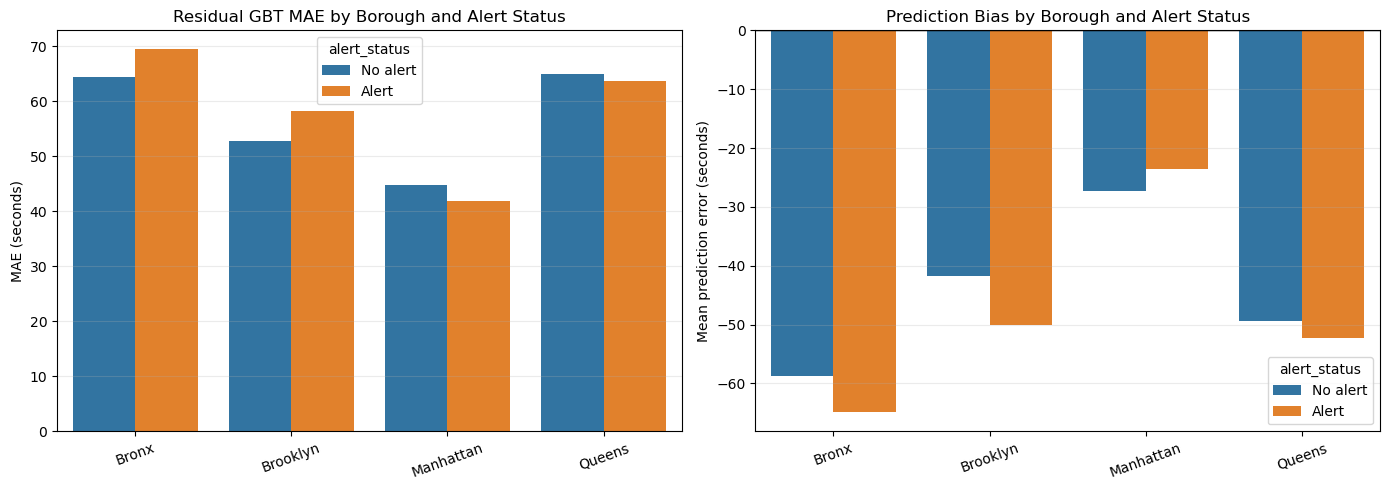

In [14]:
plot_df = borough_alert_perf_pd.copy()
plot_df["alert_status"] = plot_df["has_alert"].map({0: "No alert", 1: "Alert"})

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

# Compare model error between normal and alert-period rows in each borough
sns.barplot(data=plot_df, x="borough", y="mae_seconds", hue="alert_status", ax=axes[0])
axes[0].set_title("Residual GBT MAE by Borough and Alert Status")
axes[0].set_xlabel("")
axes[0].set_ylabel("MAE (seconds)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.25)

# Negative bias means the model is under-predicting wait time on average
sns.barplot(data=plot_df, x="borough", y="bias_pred_minus_actual", hue="alert_status", ax=axes[1])
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Prediction Bias by Borough and Alert Status")
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean prediction error (seconds)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()


### Error by Disruption Severity

This checks whether the model becomes less reliable as disruption severity rises. That is crucial because the high-severity rows are the rows most relevant to dispatch planning.
Also, it checks the historic data for fhvhv wait time and disruption severity over time for the study time frame as a sanity check. 


In [15]:
# Check whether errors increase for high disruption severity
severity_perf_pd = evaluate_by_group(
    pred_test_residual,
    ["disruption_severity"],
    "2026 test by disruption severity"
)
severity_perf_pd

,disruption_severity,n_rows,actual_mean_wait,pred_mean_wait,bias_pred_minus_actual,mae_seconds,rmse_seconds,alert_share,mean_disruption_severity,diagnostic
0,0,533345,323.95,282.32,-41.63,54.54,88.94,0.0,0.0,2026 test by disruption severity
1,1,9471,315.70,276.06,-39.64,51.79,85.06,1.0,1.0,2026 test by disruption severity
2,2,5006,308.78,268.04,-40.74,52.88,89.01,1.0,2.0,2026 test by disruption severity
3,3,1332,338.49,278.13,-60.37,69.88,130.24,1.0,3.0,2026 test by disruption severity
4,4,196,359.05,284.43,-74.61,89.34,165.78,1.0,4.0,2026 test by disruption severity
5,5,30,326.76,272.02,-54.74,66.12,139.17,1.0,5.0,2026 test by disruption severity
6,6,10,404.16,256.20,-147.96,162.84,296.36,1.0,6.0,2026 test by disruption severity
7,7,4,364.99,251.82,-113.17,118.13,161.75,1.0,7.0,2026 test by disruption severity
8,8,2,274.14,292.66,18.52,18.52,19.28,1.0,8.0,2026 test by disruption severity
9,9,1,245.63,286.24,40.61,40.61,40.61,1.0,9.0,2026 test by disruption severity


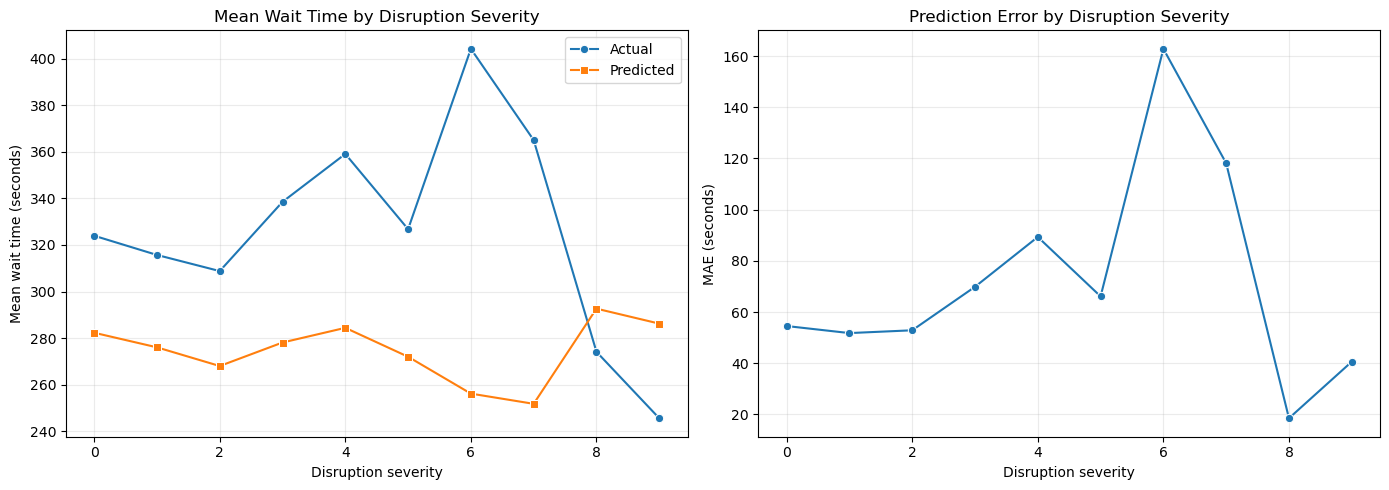

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

# Plot change in actual and predcited mean wait time across disruption severity
sns.lineplot(data=severity_perf_pd, x="disruption_severity", y="actual_mean_wait", marker="o", label="Actual", ax=axes[0])
sns.lineplot(data=severity_perf_pd, x="disruption_severity", y="pred_mean_wait", marker="s", label="Predicted", ax=axes[0])
axes[0].set_title("Mean Wait Time by Disruption Severity")
axes[0].set_xlabel("Disruption severity")
axes[0].set_ylabel("Mean wait time (seconds)")
axes[0].grid(True, alpha=0.25)

# Plot change in prediction error across disruption severity
sns.lineplot(data=severity_perf_pd, x="disruption_severity", y="mae_seconds", marker="o", ax=axes[1])
axes[1].set_title("Prediction Error by Disruption Severity")
axes[1].set_xlabel("Disruption severity")
axes[1].set_ylabel("MAE (seconds)")
axes[1].grid(True, alpha=0.25)

fig.tight_layout()
plt.show()


The mean wait time appears to be particularly high when disruption severity is around 6-7. It is possible that the high prediction error for those disruption severity scores is due to a small number of severity = 6 or 7 rows, so the relationship is noisy and not repeated consistently across zones/hours. The model’s loss function is dominated by the many normal and low-severity rows, as such, the error probably spikes where there are lesser rows assigned. 

In [17]:
# Severity timing sanity checks
# This checks whether high-severity alerts occur at unusual times, and whether
# the model is predicting below baseline during those high-severity windows.

def severity_group_expr():
    """ 
    Return a Spark expression that buckets disruption severity for diagnostics.
    """
    return (
        F.when(F.col("disruption_severity") >= 3, F.lit("3_high"))
        .when(F.col("disruption_severity") >= 2, F.lit("2_medium"))
        .when(F.col("disruption_severity") >= 1, F.lit("1_low"))
        .otherwise(F.lit("0_no_alert"))
    )

# Build excess-wait columns relative to the historical zone-hour baseline
severity_timing_sdf = (
    pred_test_residual
    .withColumn("severity_group", severity_group_expr())
    .withColumn("hour_of_week_int", F.col("hour_of_week").cast("int"))
    .withColumn("hist_wait_baseline_seconds", F.expm1("hist_log_wait_baseline"))
    .withColumn(
        "pred_excess_wait_seconds",
        F.col("pred_wait_seconds_resid") - F.col("hist_wait_baseline_seconds")
    )
    .withColumn(
        "actual_excess_wait_seconds",
        F.col("avg_wait_time_fhvhv") - F.col("hist_wait_baseline_seconds")
    )
)

# Summarise how well the model predicts high-severity rows in each borough
high_severity_summary_pd = (
    severity_timing_sdf
    .filter(F.col("severity_group") == "3_high")
    .groupBy("borough")
    .agg(
        F.count("*").alias("n_high_severity_zone_hours"),
        F.countDistinct("PULocationID").alias("n_zones"),
        F.round(F.avg("avg_wait_time_fhvhv"), 2).alias("actual_mean_wait"),
        F.round(F.avg("pred_wait_seconds_resid"), 2).alias("pred_mean_wait"),
        F.round(F.avg("hist_wait_baseline_seconds"), 2).alias("hist_baseline_wait"),
        F.round(F.avg("actual_excess_wait_seconds"), 2).alias("actual_excess_wait"),
        F.round(F.avg("pred_excess_wait_seconds"), 2).alias("pred_excess_wait"),
        F.round(F.avg((F.col("pred_excess_wait_seconds") < 0).cast("double")), 3)
            .alias("share_pred_below_baseline"),
        F.round(F.avg("disruption_severity"), 2).alias("mean_disruption_severity"),
    )
    .orderBy("borough")
    .toPandas()
)

high_severity_summary_pd

,borough,n_high_severity_zone_hours,n_zones,actual_mean_wait,pred_mean_wait,hist_baseline_wait,actual_excess_wait,pred_excess_wait,share_pred_below_baseline,mean_disruption_severity
0,Bronx,167,20,382.80,296.80,292.85,89.95,3.95,0.503,3.16
1,Brooklyn,581,40,360.66,285.15,282.95,77.71,2.20,0.644,3.20
2,Manhattan,547,35,285.98,253.93,252.22,33.77,1.71,0.625,3.22
3,Queens,280,23,383.72,302.44,299.39,84.33,3.05,0.625,3.20


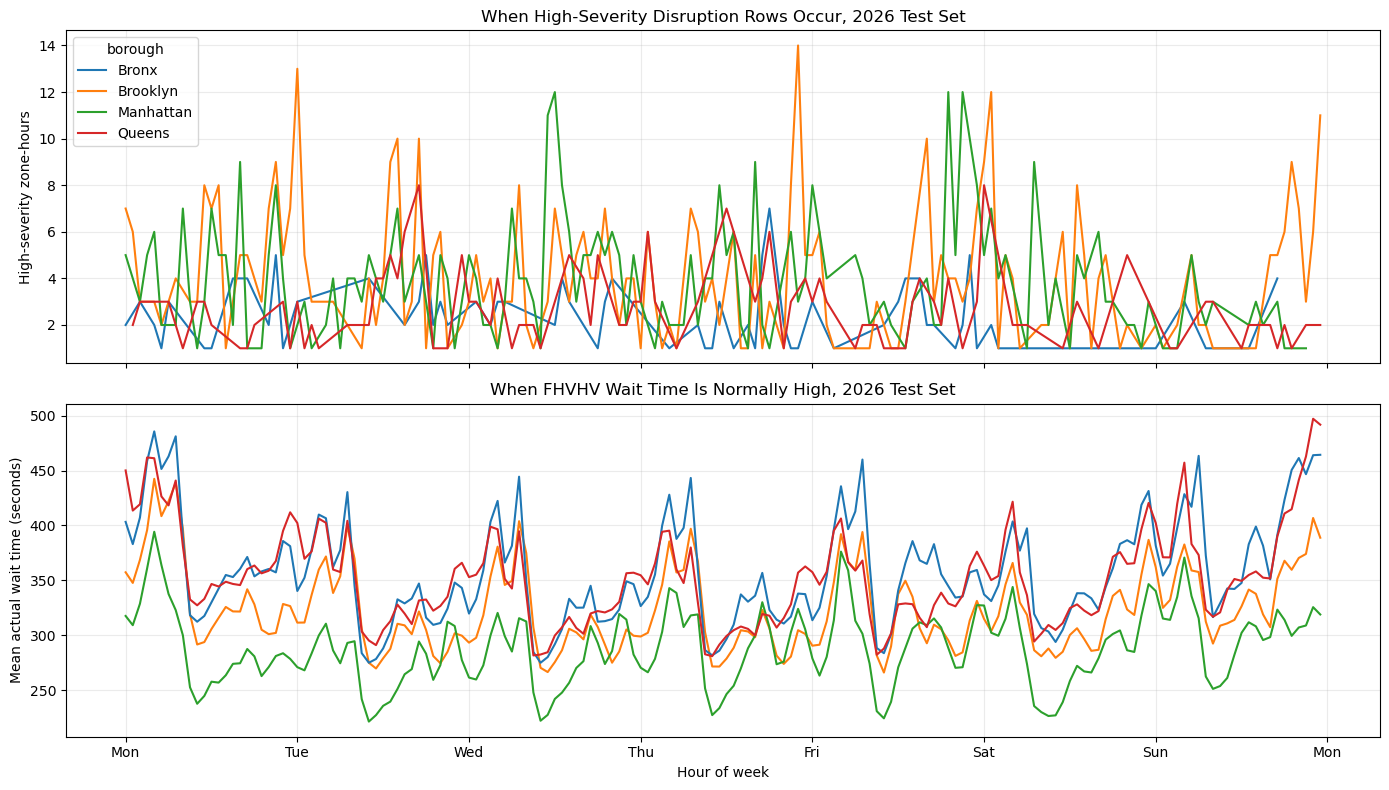

In [18]:
# Compare when high-severity disruption occurs against when wait time is high.
high_severity_how_pd = (
    severity_timing_sdf
    .filter(F.col("severity_group") == "3_high")
    .groupBy("borough", "hour_of_week_int")
    .agg(
        F.count("*").alias("n_high_severity_zone_hours"),
        F.countDistinct("PULocationID").alias("n_high_severity_zones"),
        F.round(F.avg("disruption_severity"), 2).alias("mean_disruption_severity"),
    )
    .toPandas()
)


# Summarise the usual wait-time pattern by borough and hour-of-week
wait_how_pd = (
    severity_timing_sdf
    .groupBy("borough", "hour_of_week_int")
    .agg(
        F.round(F.avg("avg_wait_time_fhvhv"), 2).alias("actual_mean_wait"),
        F.round(F.avg("pred_wait_seconds_resid"), 2).alias("pred_mean_wait"),
        F.round(F.avg("hist_wait_baseline_seconds"), 2).alias("hist_baseline_wait"),
    )
    .toPandas()
)

day_ticks = list(range(0, 169, 24))
day_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun", "Mon"]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Show when high-severity disruption observations appear in the test period
sns.lineplot(
    data=high_severity_how_pd,
    x="hour_of_week_int",
    y="n_high_severity_zone_hours",
    hue="borough",
    palette=borough_palette,
    ax=axes[0],
)
axes[0].set_title("When High-Severity Disruption Rows Occur, 2026 Test Set")
axes[0].set_ylabel("High-severity zone-hours")
axes[0].grid(alpha=0.25)

# Compare that timing with the normal weekly wait-time pattern
sns.lineplot(
    data=wait_how_pd,
    x="hour_of_week_int",
    y="actual_mean_wait",
    hue="borough",
    palette=borough_palette,
    ax=axes[1],
    legend=False,
)
axes[1].set_title("When FHVHV Wait Time Is Normally High, 2026 Test Set")
axes[1].set_xlabel("Hour of week")
axes[1].set_ylabel("Mean actual wait time (seconds)")
axes[1].set_xticks(day_ticks)
axes[1].set_xticklabels(day_labels)
axes[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()

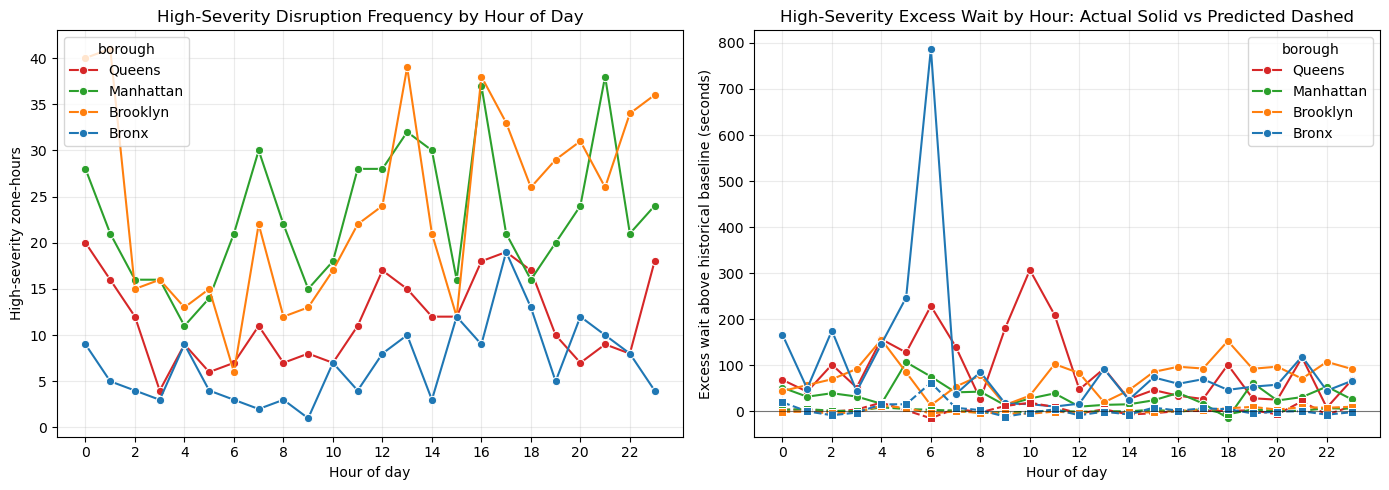

,borough,hour_of_day,n_high_severity_zone_hours,actual_mean_wait,pred_mean_wait,hist_baseline_wait,actual_excess_wait,pred_excess_wait
94,Bronx,6,3,1123.97,399.03,336.75,787.22,62.28
80,Queens,10,7,527.56,239.28,220.51,307.05,18.77
88,Bronx,5,4,535.01,303.32,287.82,247.19,15.51
47,Queens,6,7,630.76,387.07,401.94,228.82,-14.88
65,Queens,11,11,447.30,247.53,237.85,209.44,9.67
67,Queens,9,8,395.72,227.08,215.37,180.35,11.70
90,Bronx,2,4,502.68,318.93,327.28,175.40,-8.35
38,Bronx,0,9,445.02,298.01,278.24,166.77,19.77
23,Queens,4,9,520.57,382.89,363.76,156.81,19.13
21,Brooklyn,4,13,490.05,346.60,334.19,155.86,12.41


In [19]:
# For high-severity rows only, compare actual vs predicted excess wait by hour of day
high_severity_hour_pd = (
    severity_timing_sdf
    .filter(F.col("severity_group") == "3_high")
    .groupBy("borough", "hour_of_day")
    .agg(
        F.count("*").alias("n_high_severity_zone_hours"),
        F.round(F.avg("avg_wait_time_fhvhv"), 2).alias("actual_mean_wait"),
        F.round(F.avg("pred_wait_seconds_resid"), 2).alias("pred_mean_wait"),
        F.round(F.avg("hist_wait_baseline_seconds"), 2).alias("hist_baseline_wait"),
        F.round(F.avg("actual_excess_wait_seconds"), 2).alias("actual_excess_wait"),
        F.round(F.avg("pred_excess_wait_seconds"), 2).alias("pred_excess_wait"),
    )
    .toPandas()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

# Count when high-severity disruption rows occur most often
sns.lineplot(
    data=high_severity_hour_pd,
    x="hour_of_day",
    y="n_high_severity_zone_hours",
    hue="borough",
    palette=borough_palette,
    marker="o",
    ax=axes[0],
)
axes[0].set_title("High-Severity Disruption Frequency by Hour of Day")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("High-severity zone-hours")
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(alpha=0.25)

# Compare observed excess wait with the model's predicted excess wait
sns.lineplot(
    data=high_severity_hour_pd,
    x="hour_of_day",
    y="actual_excess_wait",
    hue="borough",
    palette=borough_palette,
    marker="o",
    ax=axes[1],
)
sns.lineplot(
    data=high_severity_hour_pd,
    x="hour_of_day",
    y="pred_excess_wait",
    hue="borough",
    palette=borough_palette,
    linestyle="--",
    marker="s",
    legend=False,
    ax=axes[1],
)
axes[1].axhline(0, color="black", linewidth=0.8, alpha=0.5)
axes[1].set_title("High-Severity Excess Wait by Hour: Actual Solid vs Predicted Dashed")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Excess wait above historical baseline (seconds)")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()

# Inspect the hours and boroughs with the largest observed excess wait
high_severity_hour_pd.sort_values("actual_excess_wait", ascending=False).head(20)

The diagnostics show that high-severity disruption rows are not evenly distributed across the day. Also, they occur more often in Manhattan and Brooklyn, especially around afternoon and evening hours, while the Bronx has fewer high-severity observations overall.

The right plot shows the main limitation of the residual GBT: it predicts only small excess wait above the historical baseline, while actual excess wait can spike sharply, especially in the Bronx and Queens. This suggests that the model captures normal temporal patterns better than rare severe-disruption shocks. Also, the large spike may be due to an almost-outlier entry in Bronx? Therefore, the GBT should be interpreted as a conservative screening model for identifying risky zone-hours, rather than a precise model for estimating the full magnitude of extreme wait-time increases.

In [20]:
# Check Bronx 6am records to investigate the huge spike
high_severity_hour_pd.query("borough == 'Bronx' and hour_of_day == 6")
(
    severity_timing_sdf
    .filter(
        (F.col("severity_group") == "3_high") &
        (F.col("borough") == "Bronx") &
        (F.col("hour_of_day") == 6)
    )
    .select(
        "hour", "PULocationID", "taxi_zone",
        "avg_wait_time_fhvhv",
        "hist_wait_baseline_seconds",
        "actual_excess_wait_seconds",
        "pred_excess_wait_seconds",
        "n_alerts",
        "disruption_severity"
    )
    .orderBy(F.desc("actual_excess_wait_seconds"))
    .show(30, truncate=False)
)

+-------------------+------------+------------+-------------------+--------------------------+--------------------------+------------------------+--------+-------------------+
|hour               |PULocationID|taxi_zone   |avg_wait_time_fhvhv|hist_wait_baseline_seconds|actual_excess_wait_seconds|pred_excess_wait_seconds|n_alerts|disruption_severity|
+-------------------+------------+------------+-------------------+--------------------------+--------------------------+------------------------+--------+-------------------+
|2026-02-23 06:00:00|174         |Norwood     |1130.59            |261.71494625316194        |868.8750537468379         |49.232842024748265      |1       |3                  |
|2026-02-23 06:00:00|081         |Eastchester |1214.0             |416.5800030993595         |797.4199969006405         |77.96334615100523       |1       |4                  |
|2026-02-23 06:00:00|078         |East Tremont|1027.33            |331.96272683675556        |695.3672731632444         

The huge spike for Bronx at 6am is driven by just 3 records, all from the same day (23rd Feb 2026), which were all extremely high. It is possible that there were actually some disruption events with extreme impacts that brought the historic baseline waitt ime of ~6 minutes to 15+ minutes, which is still within reasonable time and doesn't really justify removing it. This means the modelling that follows could be strongly influenced by a small number of rows such as Bronx 6am.

### Error by Taxi Zones (and spatial distribution) 

In [21]:
# Spatial evaluation: average excess-wait prediction error by TLC zone and disruption severity.
#
# Error definition:
#   predicted excess wait = predicted wait - historical baseline wait
#   actual excess wait    = actual wait - historical baseline wait
#   error                 = predicted excess wait - actual excess wait
#
# Since the same baseline is subtracted from both predicted and actual wait,
# this is equivalent to:
#   error = predicted wait - actual wait
#
# Negative error means the model under-predicts wait time.

import geopandas as gpd
from matplotlib.colors import TwoSlopeNorm

# Palette and order for plotting consistency 
borough_palette = {
    "Bronx": "#1f77b4",
    "Brooklyn": "#ff7f0e",
    "Manhattan": "#2ca02c",
    "Queens": "#d62728",
    "Staten Island": "#9467bd",
}

severity_order = ["1_low", "2_medium", "3_high"]
severity_titles = {
    "1_low": "Low Severity",
    "2_medium": "Medium Severity",
    "3_high": "High Severity",
}

# Build this only if the earlier sanity-check dataframe is not already available.
try:
    severity_timing_sdf
except NameError:
    severity_timing_sdf = (
        pred_test_residual
        .withColumn(
            "severity_group",
            F.when(F.col("disruption_severity") >= 3, F.lit("3_high"))
             .when(F.col("disruption_severity") >= 2, F.lit("2_medium"))
             .when(F.col("disruption_severity") >= 1, F.lit("1_low"))
             .otherwise(F.lit("0_no_alert"))
        )
        .withColumn(
            "hist_wait_baseline_seconds",
            F.expm1(F.col("hist_log_wait_baseline"))
        )
        .withColumn(
            "pred_excess_wait_seconds",
            F.col("pred_wait_seconds_resid") - F.col("hist_wait_baseline_seconds")
        )
        .withColumn(
            "actual_excess_wait_seconds",
            F.col("avg_wait_time_fhvhv") - F.col("hist_wait_baseline_seconds")
        )
    )

# Summarise model prediction errors for each borough 
zone_severity_error_pd = (
    severity_timing_sdf
    .filter(F.col("severity_group").isin(severity_order))
    .withColumn(
        "excess_wait_error",
        F.col("pred_excess_wait_seconds") - F.col("actual_excess_wait_seconds")
    )
    .withColumn(
        "abs_excess_wait_error",
        F.abs(F.col("excess_wait_error"))
    )
    .groupBy("PULocationID", "taxi_zone", "borough", "severity_group")
    .agg(
        F.count("*").alias("n_zone_hours"),
        F.round(F.avg("actual_excess_wait_seconds"), 2).alias("mean_actual_excess_wait"),
        F.round(F.avg("pred_excess_wait_seconds"), 2).alias("mean_pred_excess_wait"),
        F.round(F.avg("excess_wait_error"), 2).alias("mean_signed_error"),
        F.round(F.avg("abs_excess_wait_error"), 2).alias("mae_excess_wait"),
        F.round(F.avg("disruption_severity"), 2).alias("mean_disruption_severity"),
    )
    .toPandas()
)

display(
    zone_severity_error_pd
    .sort_values(["severity_group", "mean_signed_error"])
    .head(20)
)

display(
    zone_severity_error_pd
    .sort_values(["severity_group", "mae_excess_wait"], ascending=[True, False])
    .head(20)
)

,PULocationID,taxi_zone,borough,severity_group,n_zone_hours,mean_actual_excess_wait,mean_pred_excess_wait,mean_signed_error,mae_excess_wait,mean_disruption_severity
91,030,Broad Channel,Queens,1_low,24,145.72,-16.66,-162.39,235.04,1.0
69,216,South Ozone Park,Queens,1_low,24,144.33,1.87,-142.46,143.63,1.0
272,235,University Heights/Morris Heights,Bronx,1_low,15,120.87,-0.71,-121.58,128.70,1.0
195,106,Gowanus,Brooklyn,1_low,23,122.03,2.68,-119.35,125.57,1.0
59,022,Bensonhurst West,Brooklyn,1_low,48,85.88,-0.76,-86.64,91.40,1.0
306,201,Rockaway Park,Queens,1_low,15,79.98,-3.88,-83.86,104.93,1.0
370,153,Marble Hill,Manhattan,1_low,2,67.60,-15.13,-82.73,82.73,1.0
268,193,Queensbridge/Ravenswood,Queens,1_low,17,81.22,-1.26,-82.48,99.16,1.0
263,077,East New York/Pennsylvania Avenue,Brooklyn,1_low,47,76.89,-2.10,-78.98,80.56,1.0
285,248,West Farms/Bronx River,Bronx,1_low,7,71.89,-3.84,-75.72,77.44,1.0


,PULocationID,taxi_zone,borough,severity_group,n_zone_hours,mean_actual_excess_wait,mean_pred_excess_wait,mean_signed_error,mae_excess_wait,mean_disruption_severity
91,030,Broad Channel,Queens,1_low,24,145.72,-16.66,-162.39,235.04,1.0
69,216,South Ozone Park,Queens,1_low,24,144.33,1.87,-142.46,143.63,1.0
272,235,University Heights/Morris Heights,Bronx,1_low,15,120.87,-0.71,-121.58,128.70,1.0
195,106,Gowanus,Brooklyn,1_low,23,122.03,2.68,-119.35,125.57,1.0
306,201,Rockaway Park,Queens,1_low,15,79.98,-3.88,-83.86,104.93,1.0
268,193,Queensbridge/Ravenswood,Queens,1_low,17,81.22,-1.26,-82.48,99.16,1.0
9,086,Far Rockaway,Queens,1_low,41,35.54,-1.96,-37.50,91.69,1.0
59,022,Bensonhurst West,Brooklyn,1_low,48,85.88,-0.76,-86.64,91.40,1.0
370,153,Marble Hill,Manhattan,1_low,2,67.60,-15.13,-82.73,82.73,1.0
308,152,Manhattanville,Manhattan,1_low,28,63.46,-1.28,-64.74,81.23,1.0


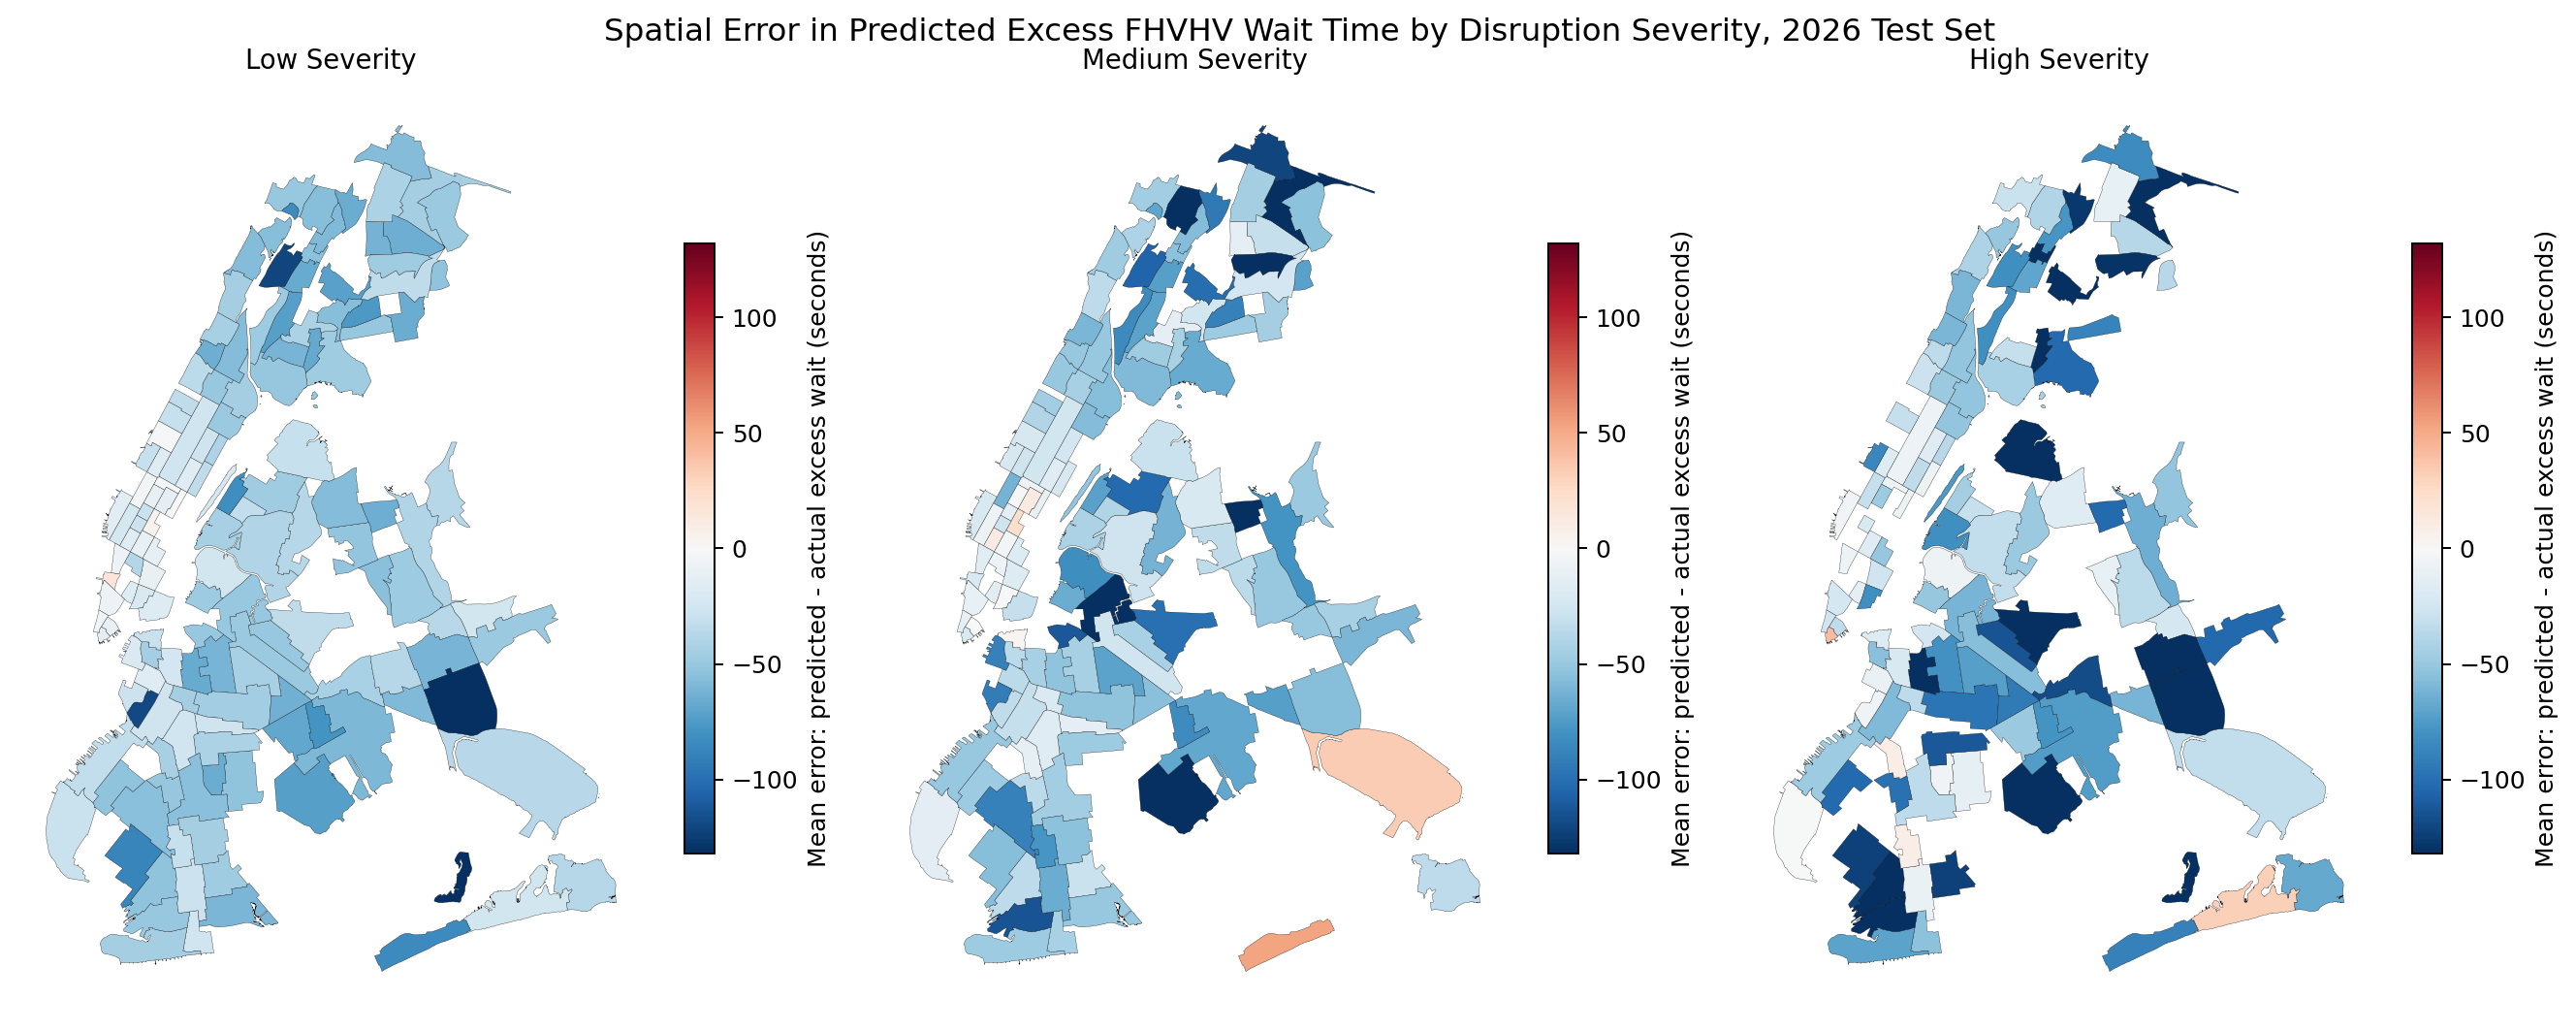

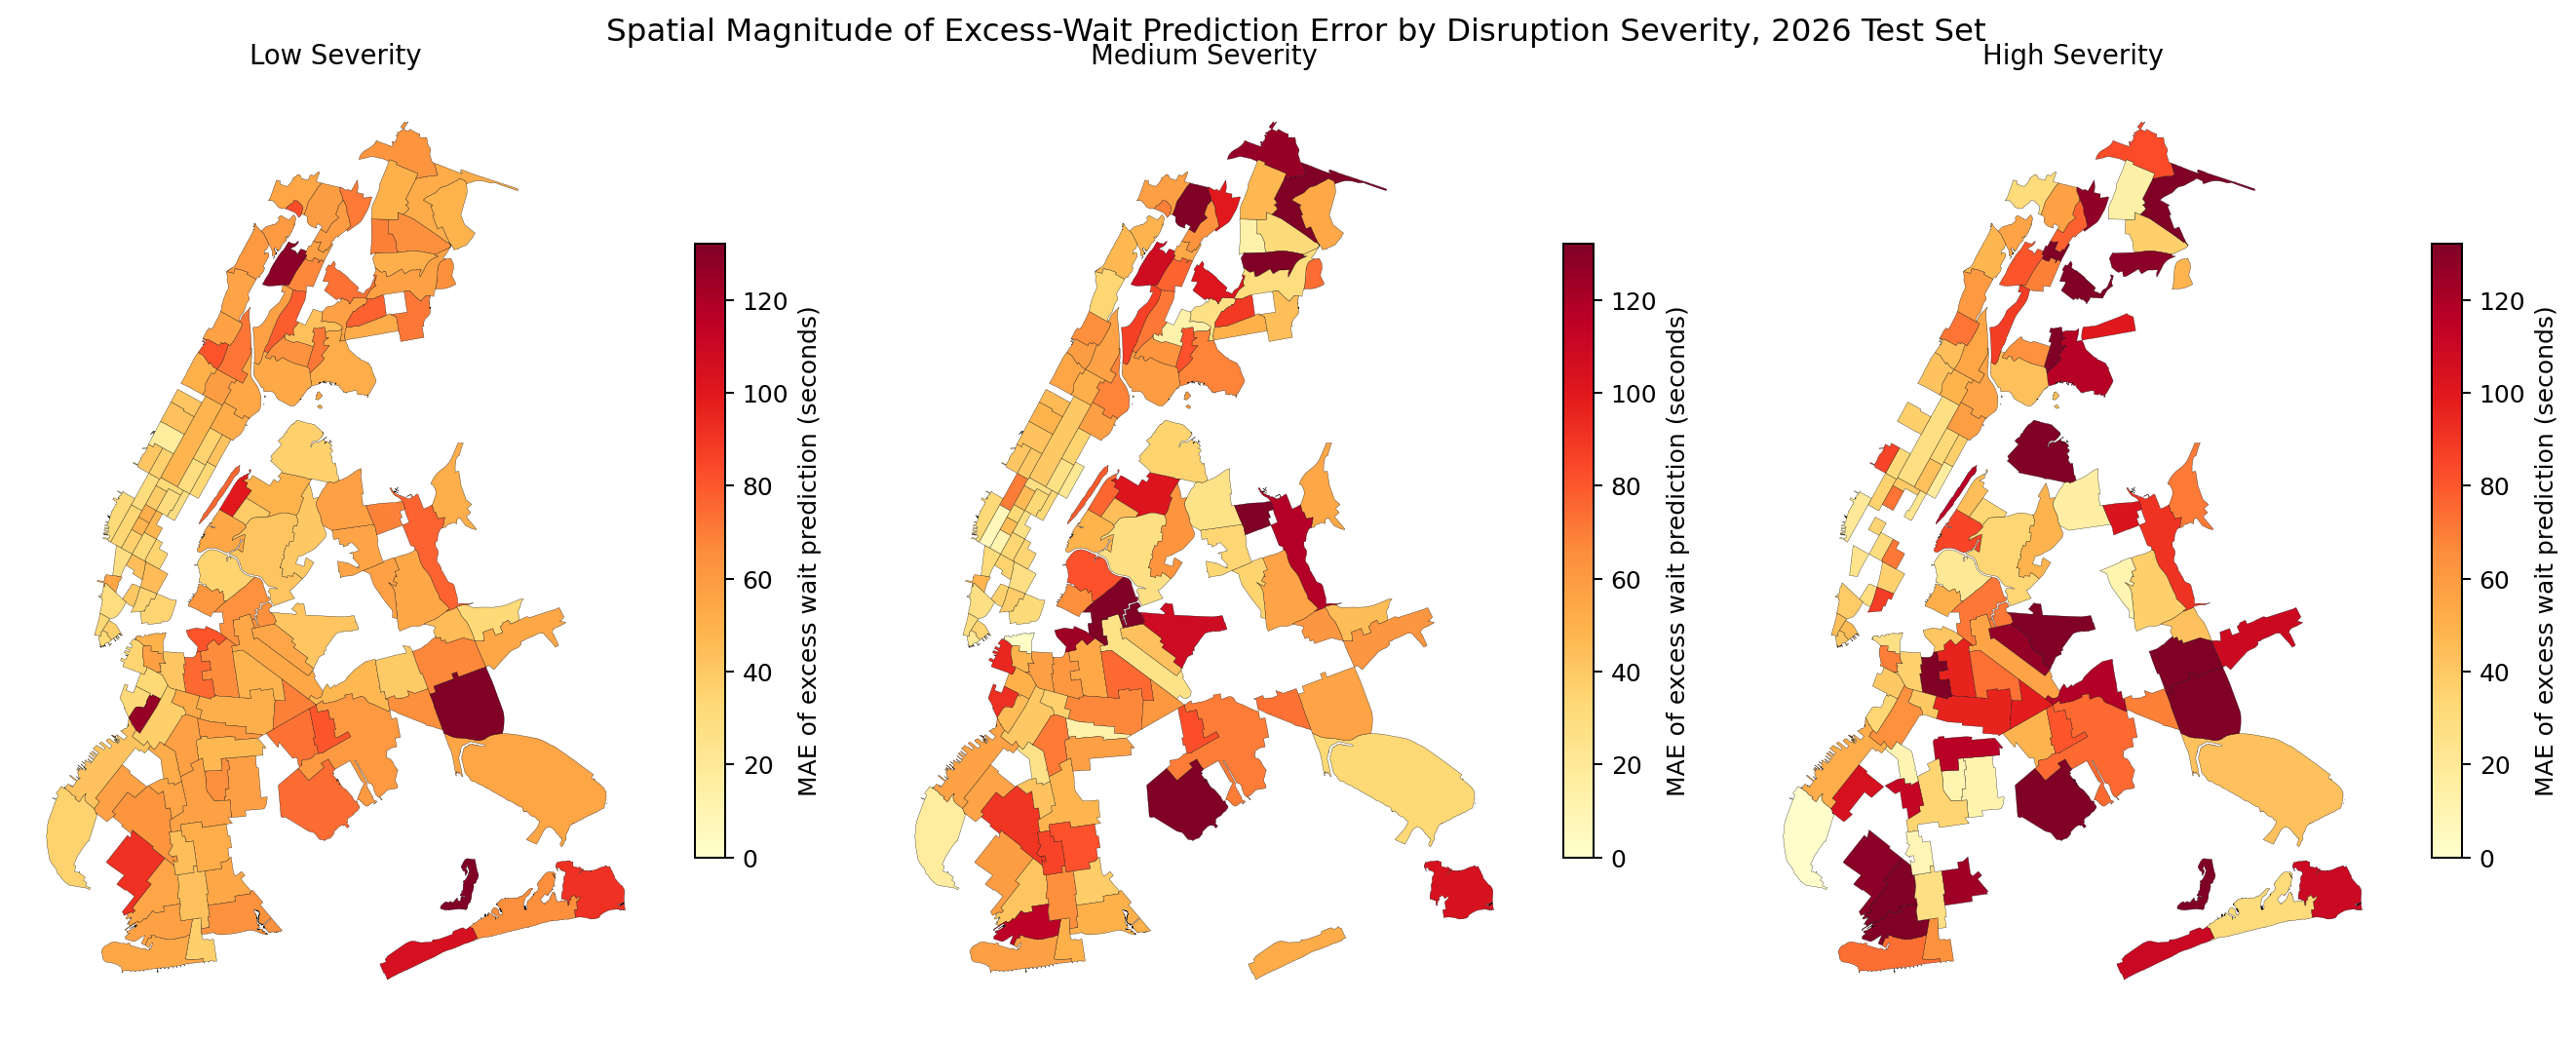

In [22]:
# Load TLC zone geometries and merge zone-level evaluation metrics.

# Reuse existing zone geometry if already loaded; otherwise read it once.
try:
    taxi_zones_geo
except NameError:
    taxi_zones_geo = gpd.read_file("../data/raw/taxi_zones/taxi_zones.shp")

# Make merge keys the same dtype.
taxi_zones_geo = taxi_zones_geo.copy()
zone_severity_error_pd = zone_severity_error_pd.copy()

taxi_zones_geo["LocationID"] = taxi_zones_geo["LocationID"].astype(int)
zone_severity_error_pd["PULocationID"] = zone_severity_error_pd["PULocationID"].astype(int)

zone_error_geo = taxi_zones_geo.merge(
    zone_severity_error_pd,
    left_on="LocationID",
    right_on="PULocationID",
    how="left",
)

zone_error_geo = zone_error_geo[
    zone_error_geo["borough_x"].isin(["Bronx", "Brooklyn", "Manhattan", "Queens"])
].copy()

missing_kwds = {
    "color": "lightgrey",
    "edgecolor": "white",
    "hatch": "///",
    "label": "No rows",
}

# Use a robust shared scale so one extreme zone does not flatten every other zone.
signed_abs_limit = np.nanpercentile(
    np.abs(zone_error_geo["mean_signed_error"]),
    95
)

signed_abs_limit = max(signed_abs_limit, 1)

mae_vmax = np.nanpercentile(zone_error_geo["mae_excess_wait"], 95)
mae_vmax = max(mae_vmax, 1)

# Signed error maps: negative = under-prediction, positive = over-prediction.
fig, axes = plt.subplots(1, 3, figsize=(15, 6), dpi=180)

for ax, severity_group in zip(axes, severity_order):
    plot_geo = zone_error_geo[
        zone_error_geo["severity_group"] == severity_group
    ].copy()

    plot_geo.plot(
        ax=ax,
        column="mean_signed_error",
        cmap="RdBu_r",
        norm=TwoSlopeNorm(vmin=-signed_abs_limit, vcenter=0, vmax=signed_abs_limit),
        edgecolor="black",
        linewidth=0.12,
        legend=True,
        missing_kwds=missing_kwds,
        legend_kwds={
            "shrink": 0.65,
            "label": "Mean error: predicted - actual excess wait (seconds)",
        },
    )

    ax.set_title(severity_titles[severity_group], fontsize=11)
    ax.axis("off")

fig.suptitle(
    "Spatial Error in Predicted Excess FHVHV Wait Time by Disruption Severity, 2026 Test Set",
    fontsize=13,
    y=0.98,
)
plt.tight_layout()
plt.show()


# Absolute error maps: where the model is least accurate regardless of direction.
fig, axes = plt.subplots(1, 3, figsize=(15, 6), dpi=180)

for ax, severity_group in zip(axes, severity_order):
    plot_geo = zone_error_geo[
        zone_error_geo["severity_group"] == severity_group
    ].copy()

    plot_geo.plot(
        ax=ax,
        column="mae_excess_wait",
        cmap="YlOrRd",
        vmin=0,
        vmax=mae_vmax,
        edgecolor="black",
        linewidth=0.12,
        legend=True,
        missing_kwds=missing_kwds,
        legend_kwds={
            "shrink": 0.65,
            "label": "MAE of excess wait prediction (seconds)",
        },
    )

    ax.set_title(severity_titles[severity_group], fontsize=11)
    ax.axis("off")

fig.suptitle(
    "Spatial Magnitude of Excess-Wait Prediction Error by Disruption Severity, 2026 Test Set",
    fontsize=13,
    y=0.98,
)   
plt.tight_layout()
plt.show()

In [23]:
# Where does the model most severely under-predict excess wait?

worst_underprediction_cols = [
    "PULocationID",
    "taxi_zone",
    "borough",
    "severity_group",
    "n_zone_hours",
    "mean_actual_excess_wait",
    "mean_pred_excess_wait",
    "mean_signed_error",
    "mae_excess_wait",
    "mean_disruption_severity",
]

print("Largest under-prediction by zone and severity group:")
display(
    zone_severity_error_pd
    .sort_values("mean_signed_error")
    [worst_underprediction_cols]
    .head(30)
)

print("Largest high-severity under-prediction:")
display(
    zone_severity_error_pd[
        zone_severity_error_pd["severity_group"] == "3_high"
    ]
    .sort_values("mean_signed_error")
    [worst_underprediction_cols]
    .head(30)
)

Largest under-prediction by zone and severity group:


,PULocationID,taxi_zone,borough,severity_group,n_zone_hours,mean_actual_excess_wait,mean_pred_excess_wait,mean_signed_error,mae_excess_wait,mean_disruption_severity
395,147,Longwood,Bronx,3_high,2,409.52,42.73,-366.78,366.78,3.00
224,30,Broad Channel,Queens,3_high,8,258.39,-7.69,-266.08,391.43,3.63
345,185,Pelham Parkway,Bronx,2_medium,3,224.04,17.31,-206.72,206.72,2.00
336,80,East Williamsburg,Brooklyn,2_medium,3,212.76,9.43,-203.33,203.33,2.00
352,81,Eastchester,Bronx,3_high,7,213.57,14.06,-199.52,204.45,3.29
351,94,Fordham South,Bronx,3_high,2,202.30,3.18,-199.12,199.12,3.00
292,39,Canarsie,Brooklyn,3_high,21,211.88,16.62,-195.26,195.27,3.00
125,49,Clinton Hill,Brooklyn,3_high,17,198.51,5.47,-193.03,194.25,3.82
373,197,Richmond Hill,Queens,3_high,4,193.08,18.48,-174.60,174.60,3.00
91,30,Broad Channel,Queens,1_low,24,145.72,-16.66,-162.39,235.04,1.00


Largest high-severity under-prediction:


,PULocationID,taxi_zone,borough,severity_group,n_zone_hours,mean_actual_excess_wait,mean_pred_excess_wait,mean_signed_error,mae_excess_wait,mean_disruption_severity
395,147,Longwood,Bronx,3_high,2,409.52,42.73,-366.78,366.78,3.00
224,30,Broad Channel,Queens,3_high,8,258.39,-7.69,-266.08,391.43,3.63
352,81,Eastchester,Bronx,3_high,7,213.57,14.06,-199.52,204.45,3.29
351,94,Fordham South,Bronx,3_high,2,202.30,3.18,-199.12,199.12,3.00
292,39,Canarsie,Brooklyn,3_high,21,211.88,16.62,-195.26,195.27,3.00
125,49,Clinton Hill,Brooklyn,3_high,17,198.51,5.47,-193.03,194.25,3.82
373,197,Richmond Hill,Queens,3_high,4,193.08,18.48,-174.60,174.60,3.00
155,223,Steinway,Queens,3_high,15,181.80,20.53,-161.27,170.23,3.53
261,216,South Ozone Park,Queens,3_high,13,158.36,5.23,-153.13,159.92,3.00
340,21,Bensonhurst East,Brooklyn,3_high,3,155.77,9.06,-146.71,156.35,3.00


In [24]:
# Diagnose borough-severity bias in excess-wait predictions.

def add_excess_wait_cols(pred_df):
    """ 
    Add baseline-relative excess wait and excess-error columns
    """
    return (
        pred_df
        .withColumn(
            "severity_group",
            F.when(F.col("disruption_severity") >= 3, F.lit("3_high"))
             .when(F.col("disruption_severity") >= 2, F.lit("2_medium"))
             .when(F.col("disruption_severity") >= 1, F.lit("1_low"))
             .otherwise(F.lit("0_no_alert"))
        )
        .withColumn("hist_wait_baseline_seconds", F.expm1(F.col("hist_log_wait_baseline")))
        .withColumn(
            "pred_excess_wait_seconds",
            F.col("pred_wait_seconds_resid") - F.col("hist_wait_baseline_seconds")
        )
        .withColumn(
            "actual_excess_wait_seconds",
            F.col("avg_wait_time_fhvhv") - F.col("hist_wait_baseline_seconds")
        )
        .withColumn(
            "signed_excess_error",
            F.col("pred_excess_wait_seconds") - F.col("actual_excess_wait_seconds")
        )
        .withColumn(
            "abs_excess_error",
            F.abs(F.col("signed_excess_error"))
        )
    )

test_excess_sdf = add_excess_wait_cols(pred_test_residual)

# Summarise whether the model systematically over- or under-predicts excess wait.
bias_summary_pd = (
    test_excess_sdf
    .filter(F.col("severity_group").isin(["1_low", "2_medium", "3_high"]))
    .groupBy("borough", "severity_group")
    .agg(
        F.count("*").alias("n_rows"),
        F.round(F.avg("avg_wait_time_fhvhv"), 2).alias("actual_wait"),
        F.round(F.avg("pred_wait_seconds_resid"), 2).alias("pred_wait"),
        F.round(F.avg("hist_wait_baseline_seconds"), 2).alias("baseline_wait"),
        F.round(F.avg("actual_excess_wait_seconds"), 2).alias("actual_excess_wait"),
        F.round(F.avg("pred_excess_wait_seconds"), 2).alias("pred_excess_wait"),
        F.round(F.avg("signed_excess_error"), 2).alias("mean_signed_error"),
        F.round(F.avg("abs_excess_error"), 2).alias("mae_excess_error"),
    )
    .orderBy("severity_group", "borough")
    .toPandas()
)

display(bias_summary_pd)

,borough,severity_group,n_rows,actual_wait,pred_wait,baseline_wait,actual_excess_wait,pred_excess_wait,mean_signed_error,mae_excess_error
0,Bronx,1_low,1266,351.27,294.88,295.81,55.46,-0.94,-56.39,61.54
1,Brooklyn,1_low,3454,329.19,281.75,282.21,46.98,-0.46,-47.44,55.21
2,Manhattan,1_low,3286,280.64,258.91,258.20,22.44,0.72,-21.72,41.35
3,Queens,1_low,1465,331.79,284.84,285.69,46.11,-0.85,-46.95,58.70
4,Bronx,2_medium,636,367.88,292.20,293.14,74.74,-0.94,-75.68,78.88
5,Brooklyn,2_medium,1667,326.23,279.45,280.69,45.54,-1.24,-46.78,55.89
6,Manhattan,2_medium,2246,277.56,253.34,251.93,25.63,1.41,-24.21,41.83
7,Queens,2_medium,457,316.35,265.06,267.77,48.59,-2.71,-51.30,60.06
8,Bronx,3_high,167,382.80,296.80,292.85,89.95,3.95,-86.00,90.49
9,Brooklyn,3_high,581,360.66,285.15,282.95,77.71,2.20,-75.51,82.61


### Actual vs Predicted Scatter Diagnostics

The scatter plot checks whether predictions are calibrated across the observed range. A perfect model would lie on the 45-degree line. Downward deviation at high actual wait times indicates under-prediction during spikes.


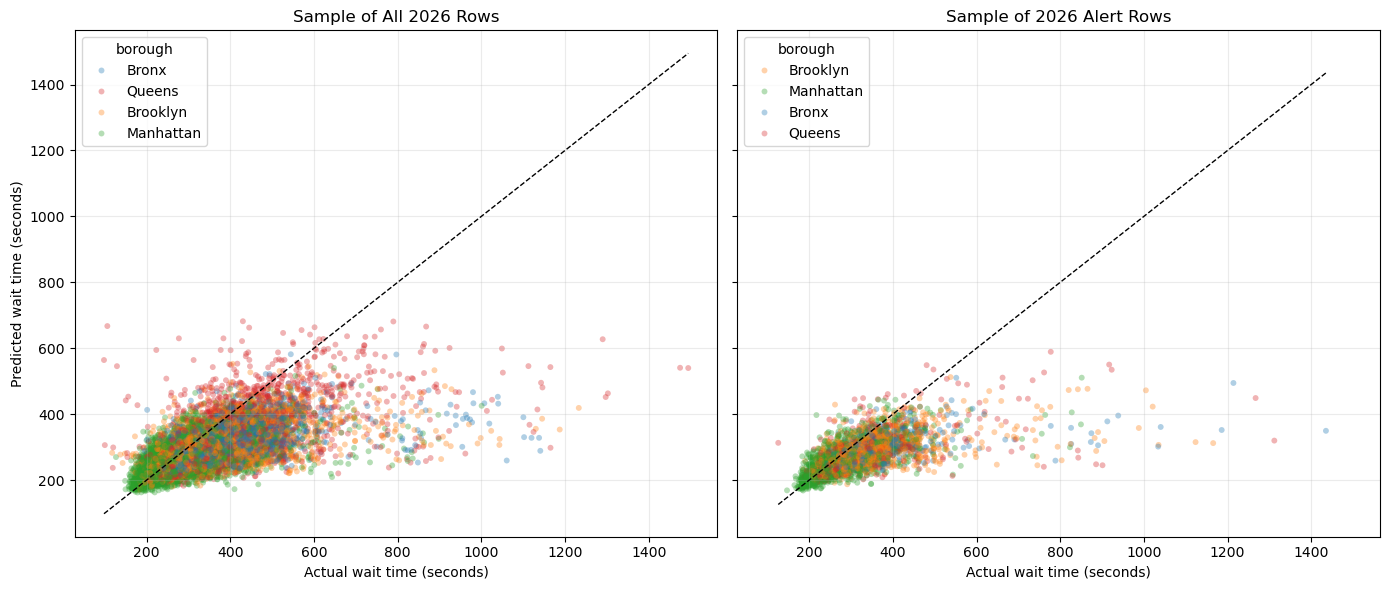

In [25]:
# Raw scale scatter
scatter_pd = (
    pred_test_residual
    .select("avg_wait_time_fhvhv", "pred_wait_seconds_resid", "has_alert", "borough", "disruption_severity")
    .sample(False, 0.04, seed=2401)
    .toPandas()
)
alert_scatter_pd = (
    pred_test_residual
    .filter(F.col("has_alert") == 1)
    .select("avg_wait_time_fhvhv", "pred_wait_seconds_resid", "has_alert", "borough", "disruption_severity")
    .sample(False, 0.25, seed=2402)
    .toPandas()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, df, title in [
    (axes[0], scatter_pd, "Sample of All 2026 Rows"),
    (axes[1], alert_scatter_pd, "Sample of 2026 Alert Rows"),
]:
    sns.scatterplot(
        data=df,
        x="avg_wait_time_fhvhv",
        y="pred_wait_seconds_resid",
        hue="borough",
        palette=borough_palette,
        alpha=0.35,
        s=18,
        linewidth=0,
        ax=ax,
    )
    lim_min = min(df["avg_wait_time_fhvhv"].min(), df["pred_wait_seconds_resid"].min())
    lim_max = max(df["avg_wait_time_fhvhv"].max(), df["pred_wait_seconds_resid"].max())
    ax.plot([lim_min, lim_max], [lim_min, lim_max], color="black", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Actual wait time (seconds)")
    ax.set_ylabel("Predicted wait time (seconds)")
    ax.grid(True, alpha=0.25)

fig.tight_layout()
plt.show()


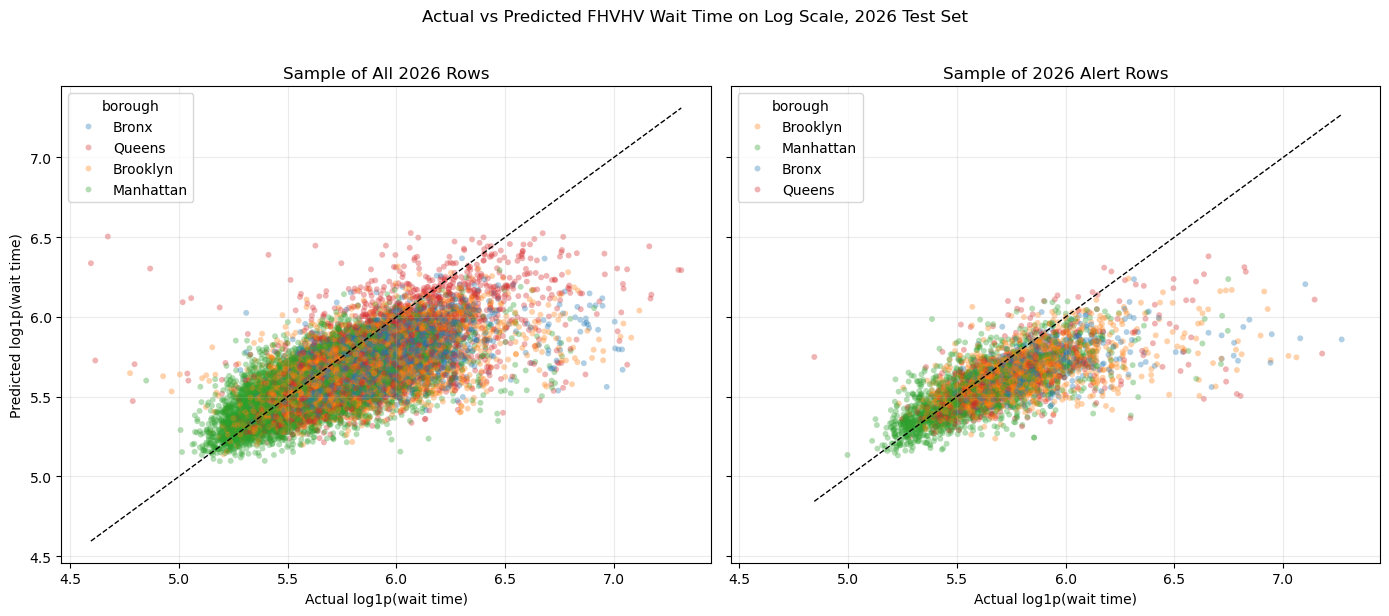

In [26]:
# Log scale scatter 
scatter_pd = (
    pred_test_residual
    .select(
        "avg_wait_time_fhvhv",
        "pred_wait_seconds_resid",
        "has_alert",
        "borough",
        "disruption_severity"
    )
    .sample(False, 0.04, seed=2401)
    .toPandas()
)

alert_scatter_pd = (
    pred_test_residual
    .filter(F.col("has_alert") == 1)
    .select(
        "avg_wait_time_fhvhv",
        "pred_wait_seconds_resid",
        "has_alert",
        "borough",
        "disruption_severity"
    )
    .sample(False, 0.25, seed=2402)
    .toPandas()
)

# Match the log-scale evaluation metric.
scatter_pd["log_actual_wait"] = np.log1p(scatter_pd["avg_wait_time_fhvhv"])
scatter_pd["log_pred_wait"] = np.log1p(scatter_pd["pred_wait_seconds_resid"])

alert_scatter_pd["log_actual_wait"] = np.log1p(alert_scatter_pd["avg_wait_time_fhvhv"])
alert_scatter_pd["log_pred_wait"] = np.log1p(alert_scatter_pd["pred_wait_seconds_resid"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

for ax, df, title in [
    (axes[0], scatter_pd, "Sample of All 2026 Rows"),
    (axes[1], alert_scatter_pd, "Sample of 2026 Alert Rows"),
]:
    sns.scatterplot(
        data=df,
        x="log_actual_wait",
        y="log_pred_wait",
        hue="borough",
        palette=borough_palette,
        alpha=0.35,
        s=18,
        linewidth=0,
        ax=ax,
    )

    lim_min = min(df["log_actual_wait"].min(), df["log_pred_wait"].min())
    lim_max = max(df["log_actual_wait"].max(), df["log_pred_wait"].max())

    ax.plot(
        [lim_min, lim_max],
        [lim_min, lim_max],
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(title)
    ax.set_xlabel("Actual log1p(wait time)")
    ax.set_ylabel("Predicted log1p(wait time)")
    ax.grid(True, alpha=0.25)

fig.suptitle("Actual vs Predicted FHVHV Wait Time on Log Scale, 2026 Test Set", y=1.02)
fig.tight_layout()
plt.show()

## Analysing Feature Importance

GBT does not have regression coefficients. Instead, Spark reports feature importance based on how much each feature contributes to tree splits. This is useful for diagnostics, but not causal interpretation.


In [27]:
def extract_feature_importance(model, train_df, numeric_cols_for_model):
    """ 
    Return feature importances at individual-feature and grouped-feature levels
    """
    fitted_tree_model = model.stages[-1]
    # Retrieve one-hot features names from spark metadata
    feature_attrs = (
        model
        .transform(train_df.limit(1))
        .schema["features"]
        .metadata["ml_attr"]["attrs"]
    )

    feature_names_by_idx = []
    for attr_type in feature_attrs:
        feature_names_by_idx.extend(
            (attr["idx"], attr["name"])
            for attr in feature_attrs[attr_type]
        )

    feature_names = [name for _, name in sorted(feature_names_by_idx)]
    importances = fitted_tree_model.featureImportances.toArray()

    feature_importance_pd = (
        pd.DataFrame({"feature": feature_names, "importance": importances})
        .sort_values("importance", ascending=False)
    )

    def feature_group(feature_name):
        """ 
        Map one-hot encoded feature names back to their original feature group
        """
        if feature_name in numeric_cols_for_model:
            return feature_name
        for col in categorical_cols:
            if feature_name.startswith(f"{col}_") or feature_name.startswith(f"{col}_oh"):
                return col
        return "other"

    grouped_importance_pd = (
        feature_importance_pd
        .assign(feature_group=lambda df: df["feature"].map(feature_group))
        .groupby("feature_group", as_index=False)["importance"]
        .sum()
        .sort_values("importance", ascending=False)
    )

    return feature_importance_pd, grouped_importance_pd

# Extract the most important features in gbt and print
feature_importance_pd, grouped_importance_pd = extract_feature_importance(
    model_gbt_residual,
    residual_train_base,
    numeric_cols_residual,
)

grouped_importance_pd.head(20)

,feature_group,importance
10,hour_of_week,0.332405
11,month_num,0.325071
17,weather_severity,0.098527
7,hist_log_fhvhv_demand_baseline,0.063825
9,hist_zone_hour_n_train,0.060263
8,hist_log_ridership_baseline,0.046271
4,borough,0.037044
0,PULocationID,0.024406
15,severity_brooklyn,0.002380
13,n_stations,0.002372


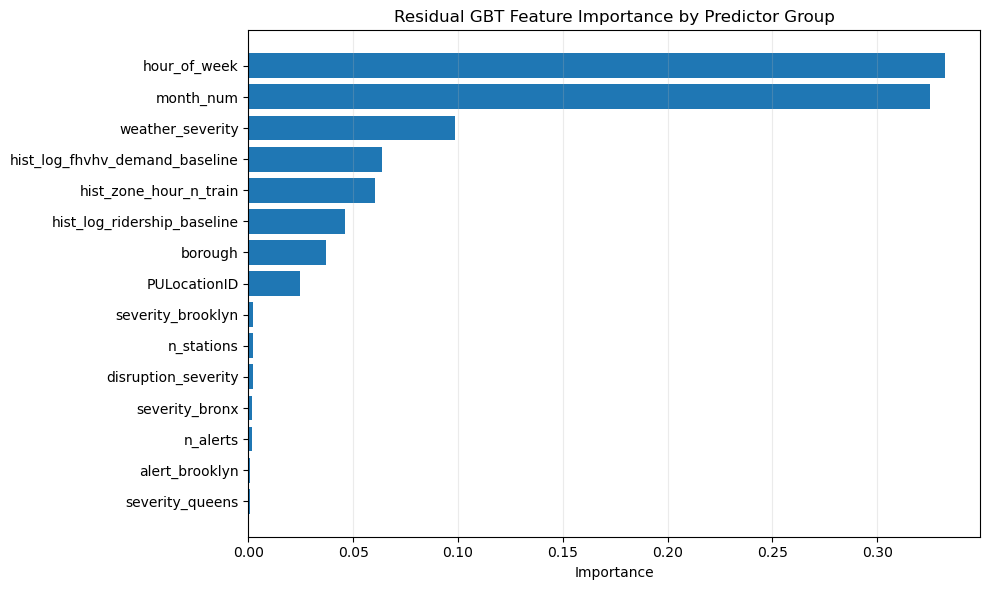

In [28]:
# Plot bar graph of feature importance in GBT
fig, ax = plt.subplots(figsize=(10, 6))
top_importance = grouped_importance_pd.head(15).sort_values("importance")
ax.barh(top_importance["feature_group"], top_importance["importance"])
ax.set_title("Residual GBT Feature Importance by Predictor Group")
ax.set_xlabel("Importance")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


We see that temporal indicators (`hour_of_week` and `month_num`) are among the most important and influential for GBT predictions. `Weather_severity` also important, presumably the high severity records have a consistent association with longer wait itmes on average. Historic data (`hist_log_fhvhv_demand_baseline`, `hist_zone_hour_n_train`, `hist_log_ridership_baseline`) provide useful context about typical zone-hour demand and data reliability. On the other hand, the disruption severity and alerts related features have lower importance, which explains why the model performs better for baselin predicitons, as it is able to capture cyclic wait time patterns more than alert spikes. 

## Zone-Hour Dispatch Priority for Recommendations

This section uses the fitted residual GBT as an operational prioritisation tool. For each 2026 test row, the model is asked to predict wait time under two alert scenarios while keeping the row's zone, time, weather, and historical baseline context fixed:

1. no alert
2. high-severity subway disruption

Predictions are first generated at the original row level, then averaged to `zone x hour_of_week`. The resulting table answers:

> If a high-severity disruption occurs at this zone-hour, where should FHVHV dispatchers consider sending extra supply?

For zone $z$ and hour-of-week $h$:

$$
\widehat{\Delta W}_{z,h}
=
\widehat{W}^{high\ severity}_{z,h}
-
\widehat{W}^{no\ alert}_{z,h}
$$

The priority score combines positive predicted excess wait with demand context:

$$
\text{Priority}_{z,h}
=
\max(\widehat{\Delta W}_{z,h}, 0)
\times
\left(0.5 + \text{DemandSupport}_{z,h}\right)
$$

Here, demand support is designed to highlight zone-hours with both high typical FHVHV activity and high typical subway ridership:

$$\text{DemandSupport}_{z,h}
=
0.5 \cdot \text{pctile}(\text{typical FHVHV trips}_{z,h})
+
0.5 \cdot \text{pctile}(\text{typical subway ridership}_{z,h})$$

This avoids prioritising zone-hours with both low subway ridership and low FHVHV activity, while still identifying areas where disrupted subway passengers may have fewer existing FHVHV options. Observed 2026 wait times are included only as validation columns and are not used to compute the priority score.


In [29]:
# Build two alert-scenario predictions for each 2026 zone-hour.
# The rows keep their existing zone, time, weather, and 2025 historical baselines.
# Only the alert features are changed.

HIGH_SCENARIO_SEVERITY = 3.0
HIGH_SCENARIO_N_ALERTS = 1.0


def set_alert_scenario(df, has_alert, n_alerts, disruption_severity):
    """Return a copy of the input data under a chosen alert scenario."""
    scenario_df = (
        df
        .withColumn("has_alert", F.lit(int(has_alert)))
        .withColumn("n_alerts", F.lit(float(n_alerts)))
        .withColumn("disruption_severity", F.lit(float(disruption_severity)))
    )
    return add_borough_disruption_interactions(scenario_df)


def predict_alert_scenario(df, scenario_name):
    """Score one alert scenario and convert predictions back to seconds."""
    pred_raw = model_gbt_residual.transform(df)
    pred_slim = slim_model_predictions(pred_raw).withColumn("scenario", F.lit(scenario_name))
    return add_residual_prediction_columns(pred_slim, smearing_factor_residual)


# Define sdf for records with no alert
no_alert_scenario_sdf = set_alert_scenario(
    residual_test_base,
    has_alert=0,
    n_alerts=0.0,
    disruption_severity=0.0,
)

# Define sdf for records with high alert severity
high_severity_scenario_sdf = set_alert_scenario(
    residual_test_base,
    has_alert=1,
    n_alerts=HIGH_SCENARIO_N_ALERTS,
    disruption_severity=HIGH_SCENARIO_SEVERITY,
)

pred_no_alert_sdf = predict_alert_scenario(no_alert_scenario_sdf, "no_alert")
pred_high_severity_sdf = predict_alert_scenario(high_severity_scenario_sdf, "high_severity")

# Join the no-alert and high-severity predictions for the same zone-hour rows.
scenario_pred_sdf = (
    pred_no_alert_sdf
    .select(
        "hour", "PULocationID", "taxi_zone", "borough", "month_num",
        "hour_of_day", "day_of_week", "hour_of_week",
        F.col("pred_wait_seconds_resid").alias("pred_no_alert_wait"),
        "hist_log_wait_baseline", "hist_log_fhvhv_demand_baseline", "hist_log_ridership_baseline",
    )
    .join(
        pred_high_severity_sdf.select(
            "hour", "PULocationID",
            F.col("pred_wait_seconds_resid").alias("pred_high_severity_wait"),
        ),
        on=["hour", "PULocationID"],
        how="inner",
    )
    .withColumn("pred_excess_wait", F.col("pred_high_severity_wait") - F.col("pred_no_alert_wait"))
    .withColumn("pred_excess_wait_pos", F.greatest(F.col("pred_excess_wait"), F.lit(0.0)))
    .withColumn("typical_fhvhv_trips", F.expm1("hist_log_fhvhv_demand_baseline"))
    .withColumn("typical_subway_ridership", F.expm1("hist_log_ridership_baseline"))
)

print(f"Alert-scenario prediction rows: {scenario_pred_sdf.count():,}")

Alert-scenario prediction rows: 549,397


### Zone-Hour Priority Table

The table below aggregates the alert-scenario predictions to `zone x hour_of_week`. Validation columns summarise actual 2026 high-severity rows where they exist. Missing validation values mean that the exact zone-hour did not experience a high-severity disruption in the 2026 test period.

The ranking therefore answers:

> Under a high-severity disruption scenario, which zone-hours should FHVHV dispatchers prioritise for extra supply?

The validation columns use actual 2026 high-severity rows where they exist. These columns are useful for checking whether the model's ranking lines up with observed disruption-period outcomes, but they are not used to compute the priority score.




In [30]:
# Validation-only observed excess wait for actual 2026 high-severity rows.
# These observed outcomes are joined after scoring and are not used in the priority formula.
validation_high_sdf = (
    pred_test_residual
    .filter(F.col("disruption_severity") >= HIGH_SCENARIO_SEVERITY)
    .withColumn("hist_wait_baseline_seconds", F.expm1("hist_log_wait_baseline"))
    .withColumn("actual_excess_wait", F.col("avg_wait_time_fhvhv") - F.col("hist_wait_baseline_seconds"))
    .groupBy("PULocationID", "hour_of_week")
    .agg(
        F.count("*").alias("n_high_severity_validation_rows"),
        F.round(F.avg("avg_wait_time_fhvhv"), 2).alias("mean_actual_high_severity_wait_validation"),
        F.round(F.avg("actual_excess_wait"), 2).alias("mean_actual_excess_wait_validation"),
        F.round(F.expr("percentile_approx(actual_excess_wait, 0.5)"), 2).alias("median_actual_excess_wait_validation"),
        F.round(F.avg("disruption_severity"), 2).alias("mean_observed_disruption_severity"),
    )
)

# Average scenario predictions to one row per pickup zone and hour-of-week
# Validation columns are joined afterwards, so actual 2026 outcomes do not affect the priority score
priority_zone_hour_sdf = (
    scenario_pred_sdf
    .groupBy("PULocationID", "taxi_zone", "borough", "hour_of_week")
    .agg(
        F.round(F.avg("pred_no_alert_wait"), 2).alias("pred_no_alert_wait"),
        F.round(F.avg("pred_high_severity_wait"), 2).alias("pred_high_severity_wait"),
        F.round(F.avg("pred_excess_wait"), 2).alias("pred_excess_wait"),
        F.round(F.avg("pred_excess_wait_pos"), 2).alias("pred_excess_wait_pos"),
        F.round(F.avg("typical_fhvhv_trips"), 2).alias("typical_fhvhv_trips"),
        F.round(F.avg("typical_subway_ridership"), 2).alias("typical_subway_ridership"),
        F.count("*").alias("n_test_rows_in_zone_hour"),
    )
    .join(validation_high_sdf, on=["PULocationID", "hour_of_week"], how="left")
)

# Convert to pandas for ranking, labelling, and plotting
priority_zone_hour_pd = priority_zone_hour_sdf.toPandas()
priority_zone_hour_pd["hour_of_week_int"] = priority_zone_hour_pd["hour_of_week"].astype(int)
priority_zone_hour_pd["hour_of_day"] = priority_zone_hour_pd["hour_of_week_int"] % 24
priority_zone_hour_pd["day_index"] = priority_zone_hour_pd["hour_of_week_int"] // 24
priority_zone_hour_pd["day_name"] = priority_zone_hour_pd["day_index"].map({0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"})
priority_zone_hour_pd["zone_hour_label"] = (
    priority_zone_hour_pd["taxi_zone"] + " | " +
    priority_zone_hour_pd["day_name"] + " " +
    priority_zone_hour_pd["hour_of_day"].astype(str).str.zfill(2) + ":00"
)

# Rank-based demand support avoids mixing raw ridership and trip counts on incompatible scales.
priority_zone_hour_pd["fhvhv_demand_pct"] = priority_zone_hour_pd["typical_fhvhv_trips"].rank(pct=True)
priority_zone_hour_pd["ridership_pct"] = priority_zone_hour_pd["typical_subway_ridership"].rank(pct=True)
priority_zone_hour_pd["demand_support"] = (
    0.5 * priority_zone_hour_pd["fhvhv_demand_pct"] +
    0.5 * priority_zone_hour_pd["ridership_pct"]
)
priority_zone_hour_pd["priority_score"] = priority_zone_hour_pd["pred_excess_wait_pos"] * (0.5 + priority_zone_hour_pd["demand_support"])
priority_zone_hour_pd["global_priority_rank"] = priority_zone_hour_pd["priority_score"].rank(method="first", ascending=False).astype(int)

priority_zone_hour_cols = [
    "global_priority_rank", "PULocationID", "taxi_zone", "borough", "day_name", "hour_of_day", "hour_of_week_int",
    "priority_score", "pred_excess_wait", "pred_no_alert_wait", "pred_high_severity_wait",
    "typical_fhvhv_trips", "typical_subway_ridership", "demand_support",
    "n_high_severity_validation_rows", "mean_actual_excess_wait_validation", "median_actual_excess_wait_validation",
]

priority_zone_hour_pd = priority_zone_hour_pd.sort_values("priority_score", ascending=False).reset_index(drop=True)
priority_zone_hour_pd[priority_zone_hour_cols].head(10)

,global_priority_rank,PULocationID,taxi_zone,borough,day_name,hour_of_day,hour_of_week_int,priority_score,pred_excess_wait,pred_no_alert_wait,pred_high_severity_wait,typical_fhvhv_trips,typical_subway_ridership,demand_support,n_high_severity_validation_rows,mean_actual_excess_wait_validation,median_actual_excess_wait_validation
0,1,247,West Concourse,Bronx,Fri,19,115,3.922731,1.45,335.61,337.06,222.59,986.73,0.769492,NaN,NaN,NaN
1,2,217,South Williamsburg,Brooklyn,Thu,4,76,3.630099,6.41,360.20,366.61,7.21,32.39,0.066318,NaN,NaN,NaN
2,3,254,Williamsbridge/Olinville,Bronx,Mon,7,7,3.589216,2.62,441.30,443.93,196.53,1305.16,0.772772,NaN,NaN,NaN
3,4,168,Mott Haven/Port Morris,Bronx,Fri,19,115,3.585225,1.32,303.39,304.71,269.88,805.61,0.780437,NaN,NaN,NaN
4,5,254,Williamsbridge/Olinville,Bronx,Fri,7,103,3.539507,2.52,454.17,456.69,218.44,1311.21,0.796523,NaN,NaN,NaN
5,6,254,Williamsbridge/Olinville,Bronx,Wed,7,55,3.434554,2.46,412.00,414.47,212.37,1435.76,0.800967,NaN,NaN,NaN
6,7,212,Soundview/Bruckner,Bronx,Mon,7,7,3.416452,2.72,455.82,458.54,98.03,2371.95,0.674039,NaN,NaN,NaN
7,8,212,Soundview/Bruckner,Bronx,Wed,7,55,3.294199,2.58,427.39,429.97,103.78,2610.97,0.693550,NaN,NaN,NaN
8,9,018,Bedford Park,Bronx,Fri,19,115,3.277740,1.29,298.42,299.71,205.13,608.98,0.691906,NaN,NaN,NaN
9,10,254,Williamsbridge/Olinville,Bronx,Thu,7,79,3.270394,2.29,439.19,441.47,207.99,1389.50,0.792646,NaN,NaN,NaN


### Priority Ranking Reliability

The wait-time predictions are conservative in magnitude, especially during rare high-severity disruptions. For the recommendation, the key question is therefore whether the model ranks higher-risk zone-hours above lower-risk ones. Spearman rank correlation checks whether the model-based priority ranking moves in the same direction as observed 2026 high-severity excess wait, using only zone-hours with validation data available.


In [31]:
# Keep only zone-hours where 2026 high-severity validation is available.
ranking_validation_pd = priority_zone_hour_pd.dropna(
    subset=["priority_score", "pred_excess_wait", "pred_high_severity_wait", "mean_actual_excess_wait_validation"]
).copy()

# Spearman correlation checks whether two rankings move in a similar order.
ranking_metrics_pd = pd.DataFrame([
    {
        "metric": "Spearman: priority score vs actual excess wait",
        "n_validated_zone_hours": len(ranking_validation_pd),
        "spearman_rank_corr": ranking_validation_pd["priority_score"].corr(
            ranking_validation_pd["mean_actual_excess_wait_validation"], method="spearman"
        ),
    },
    {
        "metric": "Spearman: predicted excess wait vs actual excess wait",
        "n_validated_zone_hours": len(ranking_validation_pd),
        "spearman_rank_corr": ranking_validation_pd["pred_excess_wait"].corr(
            ranking_validation_pd["mean_actual_excess_wait_validation"], method="spearman"
        ),
    },
    {
        "metric": "Spearman: predicted high-severity wait vs actual excess wait",
        "n_validated_zone_hours": len(ranking_validation_pd),
        "spearman_rank_corr": ranking_validation_pd["pred_high_severity_wait"].corr(
            ranking_validation_pd["mean_actual_excess_wait_validation"], method="spearman"
        ),
    },
])

ranking_metrics_pd["spearman_rank_corr"] = ranking_metrics_pd["spearman_rank_corr"].round(3)
ranking_metrics_pd


,metric,n_validated_zone_hours,spearman_rank_corr
0,Spearman: priority score vs actual excess wait,1456,0.090
1,Spearman: predicted excess wait vs actual exce...,1456,0.004
2,Spearman: predicted high-severity wait vs actu...,1456,0.194


### Highest Priority Zone for Each Hour of Week

This table gives one recommended zone for each hour of the week. It is useful as a compact dispatch schedule because it identifies the top model-ranked zone-hour for each weekly hour.

In [32]:
# Select the highest-priority zone for every hour of the week.
top_zone_each_hour_pd = (
    priority_zone_hour_pd
    .sort_values(["hour_of_week_int", "priority_score", "typical_subway_ridership"], ascending=[True, False, False])
    .groupby("hour_of_week_int", as_index=False)
    .head(1)
    .sort_values("hour_of_week_int")
    .reset_index(drop=True)
)

top_zone_each_hour_pd[priority_zone_hour_cols].head(10)

,global_priority_rank,PULocationID,taxi_zone,borough,day_name,hour_of_day,hour_of_week_int,priority_score,pred_excess_wait,pred_no_alert_wait,pred_high_severity_wait,typical_fhvhv_trips,typical_subway_ridership,demand_support,n_high_severity_validation_rows,mean_actual_excess_wait_validation,median_actual_excess_wait_validation
0,314,132,JFK Airport,Queens,Mon,0,0,2.365263,2.14,553.18,555.32,819.12,74.73,0.605263,NaN,NaN,NaN
1,798,132,JFK Airport,Queens,Mon,1,1,2.032235,1.89,461.28,463.17,429.69,55.94,0.575257,NaN,NaN,NaN
2,729,132,JFK Airport,Queens,Mon,2,2,2.061486,2.18,517.70,519.88,208.98,28.69,0.445636,NaN,NaN,NaN
3,1050,055,Coney Island,Brooklyn,Mon,3,3,1.940644,3.10,388.78,391.88,15.25,47.13,0.100818,NaN,NaN,NaN
4,299,168,Mott Haven/Port Morris,Bronx,Mon,4,4,2.382992,2.64,429.78,432.43,65.92,231.74,0.342047,NaN,NaN,NaN
5,198,254,Williamsbridge/Olinville,Bronx,Mon,5,5,2.514742,2.42,391.24,393.66,87.22,472.78,0.470943,NaN,NaN,NaN
6,11,254,Williamsbridge/Olinville,Bronx,Mon,6,6,3.259228,2.60,420.54,423.14,144.15,1007.22,0.672384,NaN,NaN,NaN
7,3,254,Williamsbridge/Olinville,Bronx,Mon,7,7,3.589216,2.62,441.30,443.93,196.53,1305.16,0.772772,NaN,NaN,NaN
8,21,254,Williamsbridge/Olinville,Bronx,Mon,8,8,3.140675,2.30,386.14,388.44,227.55,963.57,0.771528,NaN,NaN,NaN
9,540,254,Williamsbridge/Olinville,Bronx,Mon,9,9,2.180164,1.78,297.95,299.73,171.79,556.51,0.641447,NaN,NaN,NaN


### Global Top Priority Zone-Hours

These are the zone-hours where the model predicts the largest operational priority after accounting for historical FHVHV demand and subway ridership exposure, over all times and locations.

In [33]:
# Create one global priority list across all zones and hours of the week.
global_top_priority_zone_hours_pd = (
    priority_zone_hour_pd
    .sort_values(["priority_score", "pred_excess_wait", "typical_subway_ridership"], ascending=False)
    .reset_index(drop=True)
)
global_top_priority_zone_hours_pd["global_priority_rank"] = np.arange(1, len(global_top_priority_zone_hours_pd) + 1)

global_top_priority_zone_hours_pd[priority_zone_hour_cols].head(10)

,global_priority_rank,PULocationID,taxi_zone,borough,day_name,hour_of_day,hour_of_week_int,priority_score,pred_excess_wait,pred_no_alert_wait,pred_high_severity_wait,typical_fhvhv_trips,typical_subway_ridership,demand_support,n_high_severity_validation_rows,mean_actual_excess_wait_validation,median_actual_excess_wait_validation
0,1,247,West Concourse,Bronx,Fri,19,115,3.922731,1.45,335.61,337.06,222.59,986.73,0.769492,NaN,NaN,NaN
1,2,217,South Williamsburg,Brooklyn,Thu,4,76,3.630099,6.41,360.20,366.61,7.21,32.39,0.066318,NaN,NaN,NaN
2,3,254,Williamsbridge/Olinville,Bronx,Mon,7,7,3.589216,2.62,441.30,443.93,196.53,1305.16,0.772772,NaN,NaN,NaN
3,4,168,Mott Haven/Port Morris,Bronx,Fri,19,115,3.585225,1.32,303.39,304.71,269.88,805.61,0.780437,NaN,NaN,NaN
4,5,254,Williamsbridge/Olinville,Bronx,Fri,7,103,3.539507,2.52,454.17,456.69,218.44,1311.21,0.796523,NaN,NaN,NaN
5,6,254,Williamsbridge/Olinville,Bronx,Wed,7,55,3.434554,2.46,412.00,414.47,212.37,1435.76,0.800967,NaN,NaN,NaN
6,7,212,Soundview/Bruckner,Bronx,Mon,7,7,3.416452,2.72,455.82,458.54,98.03,2371.95,0.674039,NaN,NaN,NaN
7,8,212,Soundview/Bruckner,Bronx,Wed,7,55,3.294199,2.58,427.39,429.97,103.78,2610.97,0.693550,NaN,NaN,NaN
8,9,018,Bedford Park,Bronx,Fri,19,115,3.277740,1.29,298.42,299.71,205.13,608.98,0.691906,NaN,NaN,NaN
9,10,254,Williamsbridge/Olinville,Bronx,Thu,7,79,3.270394,2.29,439.19,441.47,207.99,1389.50,0.792646,NaN,NaN,NaN


### Persistent Priority Zones

A zone is more useful as a recommendation if it repeatedly appears among the high-priority candidates across the week. The table below counts how often each zone appears in the top candidates for each hour-of-week.

In [34]:
TOP_ZONE_HOURS_PER_HOUR = 10

# Keep the top candidate zones within each hour before counting persistence.
top_k_each_hour_pd = (
    priority_zone_hour_pd
    .sort_values(["hour_of_week_int", "priority_score"], ascending=[True, False])
    .groupby("hour_of_week_int", group_keys=False)
    .head(TOP_ZONE_HOURS_PER_HOUR)
    .copy()
)

# Count zones that repeatedly appear as high-priority across the week.
persistent_priority_zones_pd = (
    top_k_each_hour_pd
    .groupby(["PULocationID", "taxi_zone", "borough"], as_index=False)
    .agg(
        n_top_hour_appearances=("priority_score", "size"),
        mean_priority_score=("priority_score", "mean"),
        max_priority_score=("priority_score", "max"),
        mean_pred_excess_wait=("pred_excess_wait", "mean"),
        mean_pred_high_severity_wait=("pred_high_severity_wait", "mean"),
        mean_typical_fhvhv_trips=("typical_fhvhv_trips", "mean"),
        mean_typical_subway_ridership=("typical_subway_ridership", "mean"),
        mean_actual_excess_wait_validation=("mean_actual_excess_wait_validation", "mean"),
    )
    .sort_values(["n_top_hour_appearances", "mean_priority_score"], ascending=False)
)

# Round numeric columns so the displayed table is easier to read.
for col in [
    "mean_priority_score", "max_priority_score", "mean_pred_excess_wait", "mean_pred_high_severity_wait",
    "mean_typical_fhvhv_trips", "mean_typical_subway_ridership", "mean_actual_excess_wait_validation"
]:
    persistent_priority_zones_pd[col] = persistent_priority_zones_pd[col].round(2)

persistent_priority_zones_pd.head(10)


,PULocationID,taxi_zone,borough,n_top_hour_appearances,mean_priority_score,max_priority_score,mean_pred_excess_wait,mean_pred_high_severity_wait,mean_typical_fhvhv_trips,mean_typical_subway_ridership,mean_actual_excess_wait_validation
55,247,West Concourse,Bronx,158,2.15,3.92,1.73,307.90,146.49,1259.22,92.79
36,168,Mott Haven/Port Morris,Bronx,157,2.07,3.59,1.70,302.76,174.76,800.51,41.79
57,254,Williamsbridge/Olinville,Bronx,146,1.95,3.59,1.81,329.88,133.93,348.58,23.48
2,018,Bedford Park,Bronx,133,1.95,3.28,1.57,286.88,150.02,890.17,70.78
52,235,University Heights/Morris Heights,Bronx,132,1.91,3.19,1.74,319.68,123.07,403.36,105.15
35,159,Melrose South,Bronx,101,1.95,3.24,1.65,293.38,137.62,796.89,29.28
58,259,Woodlawn/Wakefield,Bronx,98,1.84,3.10,2.04,372.12,87.05,166.80,NaN
37,169,Mount Hope,Bronx,91,1.96,3.16,1.67,299.02,153.11,542.34,NaN
16,078,East Tremont,Bronx,81,1.90,3.14,1.68,310.94,129.74,531.42,218.84
27,126,Hunts Point,Bronx,78,1.92,2.88,1.79,320.21,93.38,573.44,131.57


### Temporal Priority Pattern

This summary identifies which hours of the week have the highest predicted dispatch pressure. It supports a temporal recommendation, such as increasing monitoring or reserve driver supply at recurring high-risk hours.

In [35]:
# Summarise when the top priority zone-hours tend to occur.
temporal_priority_pd = (
    top_k_each_hour_pd
    .groupby(["hour_of_week_int", "day_name", "hour_of_day"], as_index=False)
    .agg(
        mean_top_priority_score=("priority_score", "mean"),
        max_priority_score=("priority_score", "max"),
        mean_pred_excess_wait=("pred_excess_wait", "mean"),
        mean_pred_high_severity_wait=("pred_high_severity_wait", "mean"),
        mean_typical_fhvhv_trips=("typical_fhvhv_trips", "mean"),
        mean_typical_subway_ridership=("typical_subway_ridership", "mean"),
        n_candidate_zones=("PULocationID", "nunique"),
    )
    .sort_values("mean_top_priority_score", ascending=False)
)

# Round display columns for a compact diagnostic table.
for col in [
    "mean_top_priority_score", "max_priority_score", "mean_pred_excess_wait", "mean_pred_high_severity_wait",
    "mean_typical_fhvhv_trips", "mean_typical_subway_ridership"
]:
    temporal_priority_pd[col] = temporal_priority_pd[col].round(2)

temporal_priority_pd.head(10)


,hour_of_week_int,day_name,hour_of_day,mean_top_priority_score,max_priority_score,mean_pred_excess_wait,mean_pred_high_severity_wait,mean_typical_fhvhv_trips,mean_typical_subway_ridership,n_candidate_zones
115,115,Fri,19,3.18,3.92,1.31,305.19,193.57,496.18,10
7,7,Mon,7,3.14,3.59,2.44,412.11,157.67,1527.67,10
55,55,Wed,7,3.05,3.43,2.32,388.18,173.83,1679.12,10
103,103,Fri,7,3.04,3.54,2.31,416.78,174.61,1545.79,10
79,79,Thu,7,2.84,3.27,2.10,405.21,171.81,1624.35,10
31,31,Tue,7,2.77,3.19,2.09,373.31,173.70,1725.29,10
76,76,Thu,4,2.74,3.63,3.93,350.54,43.16,159.88,10
8,8,Mon,8,2.67,3.14,2.01,338.73,194.51,1470.12,10
6,6,Mon,6,2.61,3.26,2.24,364.12,112.58,1033.92,10
113,113,Fri,17,2.61,3.14,1.97,362.85,202.61,1006.31,10


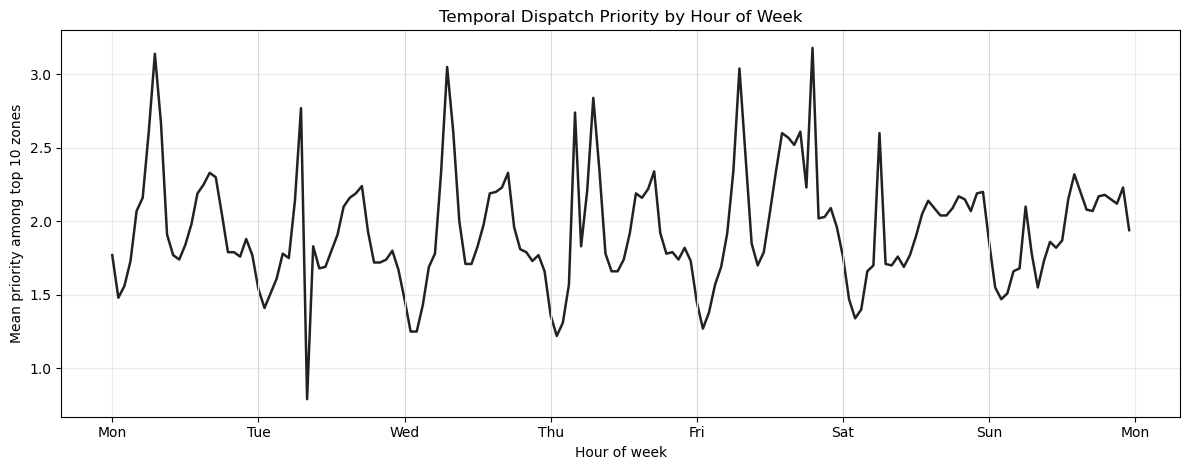

In [36]:
# Plot the weekly pattern of model-ranked dispatch pressure.
fig, ax = plt.subplots(figsize=(12, 4.8))
plot_temporal_pd = temporal_priority_pd.sort_values("hour_of_week_int")

sns.lineplot(
    data=plot_temporal_pd,
    x="hour_of_week_int",
    y="mean_top_priority_score",
    color="#222222",
    linewidth=1.8,
    ax=ax,
)
ax.set_title("Temporal Dispatch Priority by Hour of Week")
ax.set_xlabel("Hour of week")
ax.set_ylabel(f"Mean priority among top {TOP_ZONE_HOURS_PER_HOUR} zones")
ax.set_xticks([0, 24, 48, 72, 96, 120, 144, 168])
ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun", "Mon"])
# Vertical guide lines mark day boundaries.
for x in [24, 48, 72, 96, 120, 144]:
    ax.axvline(x, color="0.85", linewidth=0.8)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Top Zone-Hours Within Each Borough

The bars are sorted by the priority score, but the x-axis shows predicted high-severity wait time in seconds. This keeps the figure interpretable while still using the alert-aware priority ranking to select the displayed zone-hours.

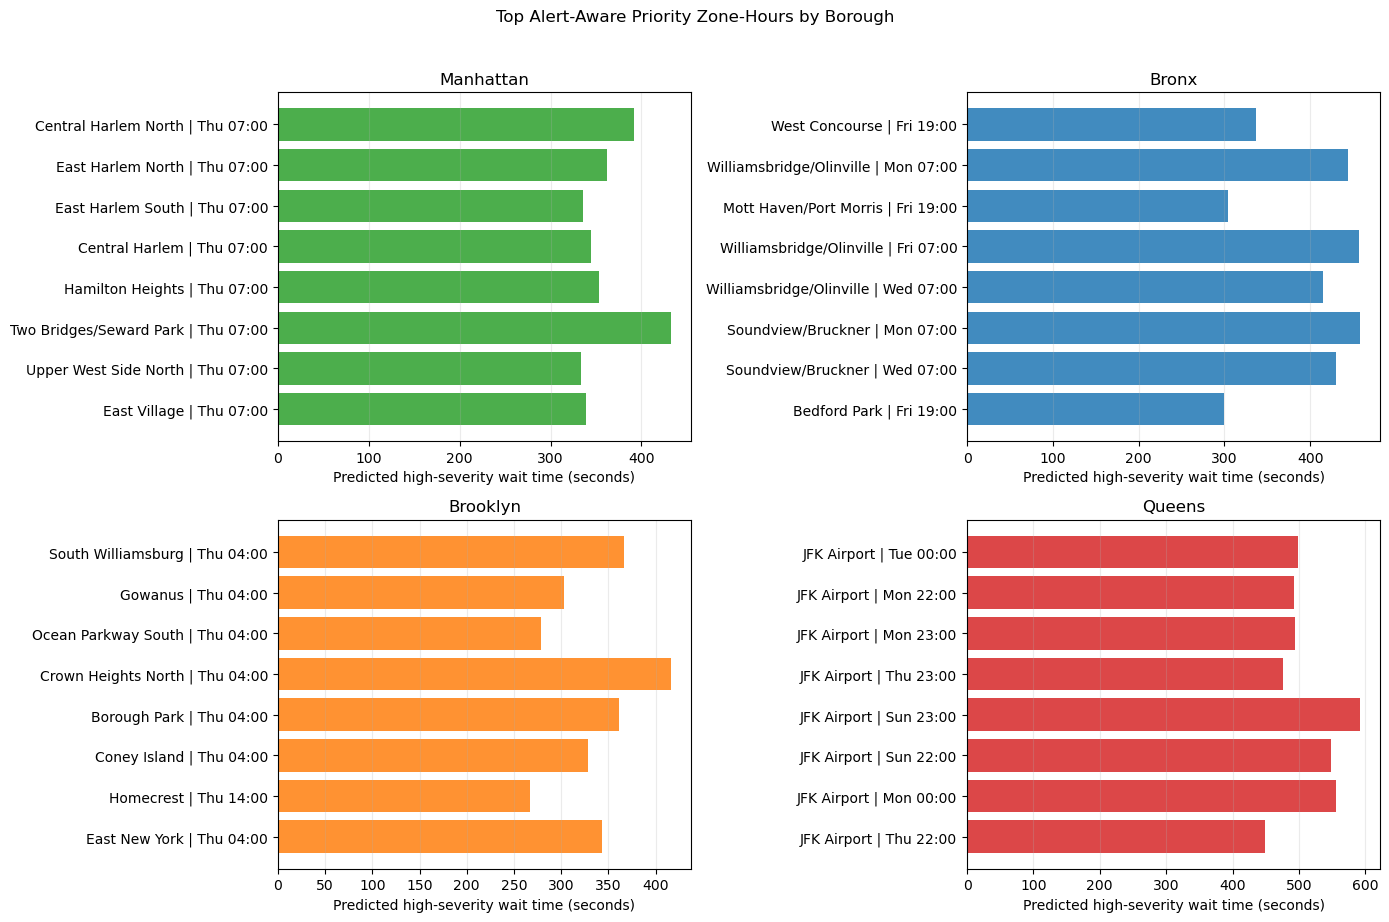

,global_priority_rank,PULocationID,taxi_zone,borough,day_name,hour_of_day,hour_of_week_int,priority_score,pred_excess_wait,pred_no_alert_wait,pred_high_severity_wait,typical_fhvhv_trips,typical_subway_ridership,demand_support,n_high_severity_validation_rows,mean_actual_excess_wait_validation,median_actual_excess_wait_validation
0,1,247,West Concourse,Bronx,Fri,19,115,3.922731,1.45,335.61,337.06,222.59,986.73,0.769492,NaN,NaN,NaN
2,3,254,Williamsbridge/Olinville,Bronx,Mon,7,7,3.589216,2.62,441.30,443.93,196.53,1305.16,0.772772,NaN,NaN,NaN
3,4,168,Mott Haven/Port Morris,Bronx,Fri,19,115,3.585225,1.32,303.39,304.71,269.88,805.61,0.780437,NaN,NaN,NaN
4,5,254,Williamsbridge/Olinville,Bronx,Fri,7,103,3.539507,2.52,454.17,456.69,218.44,1311.21,0.796523,NaN,NaN,NaN
5,6,254,Williamsbridge/Olinville,Bronx,Wed,7,55,3.434554,2.46,412.00,414.47,212.37,1435.76,0.800967,NaN,NaN,NaN
6,7,212,Soundview/Bruckner,Bronx,Mon,7,7,3.416452,2.72,455.82,458.54,98.03,2371.95,0.674039,NaN,NaN,NaN
7,8,212,Soundview/Bruckner,Bronx,Wed,7,55,3.294199,2.58,427.39,429.97,103.78,2610.97,0.693550,NaN,NaN,NaN
8,9,018,Bedford Park,Bronx,Fri,19,115,3.277740,1.29,298.42,299.71,205.13,608.98,0.691906,NaN,NaN,NaN
1,2,217,South Williamsburg,Brooklyn,Thu,4,76,3.630099,6.41,360.20,366.61,7.21,32.39,0.066318,NaN,NaN,NaN
21,22,106,Gowanus,Brooklyn,Thu,4,76,3.119011,5.30,298.01,303.32,11.48,43.76,0.088493,1.0,62.64,62.64


In [37]:
TOP_ZONE_HOURS_PER_BOROUGH = 8

# Select the top zone-hours separately within each borough.
priority_top_by_borough_pd = (
    priority_zone_hour_pd
    .sort_values(["borough", "priority_score", "pred_excess_wait"], ascending=[True, False, False])
    .groupby("borough", group_keys=False)
    .head(TOP_ZONE_HOURS_PER_BOROUGH)
    .copy()
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=False)
axes = axes.flatten()
borough_order = [b for b in ["Manhattan", "Bronx", "Brooklyn", "Queens"] if b in priority_top_by_borough_pd["borough"].unique()]

# Facet by borough to avoid Manhattan/Bronx dominating the display.
for ax, borough in zip(axes, borough_order):
    plot_df = (
        priority_top_by_borough_pd
        .query("borough == @borough")
        .sort_values("priority_score", ascending=True)
    )
    ax.barh(
        plot_df["zone_hour_label"],
        plot_df["pred_high_severity_wait"],
        color=borough_palette.get(borough, "#666666"),
        alpha=0.85,
    )
    ax.set_title(borough)
    ax.set_xlabel("Predicted high-severity wait time (seconds)")
    ax.grid(axis="x", alpha=0.25)

for ax in axes[len(borough_order):]:
    ax.axis("off")

fig.suptitle("Top Alert-Aware Priority Zone-Hours by Borough", y=1.02)
plt.tight_layout()
plt.show()

priority_top_by_borough_pd[priority_zone_hour_cols].head(10)


### Spatial Priority Maps

The first map shows zones that persistently appear among the top priority candidates across the week. The second pair of maps focuses on one selected hour-of-week and shows both the final priority score and the underlying predicted excess wait.

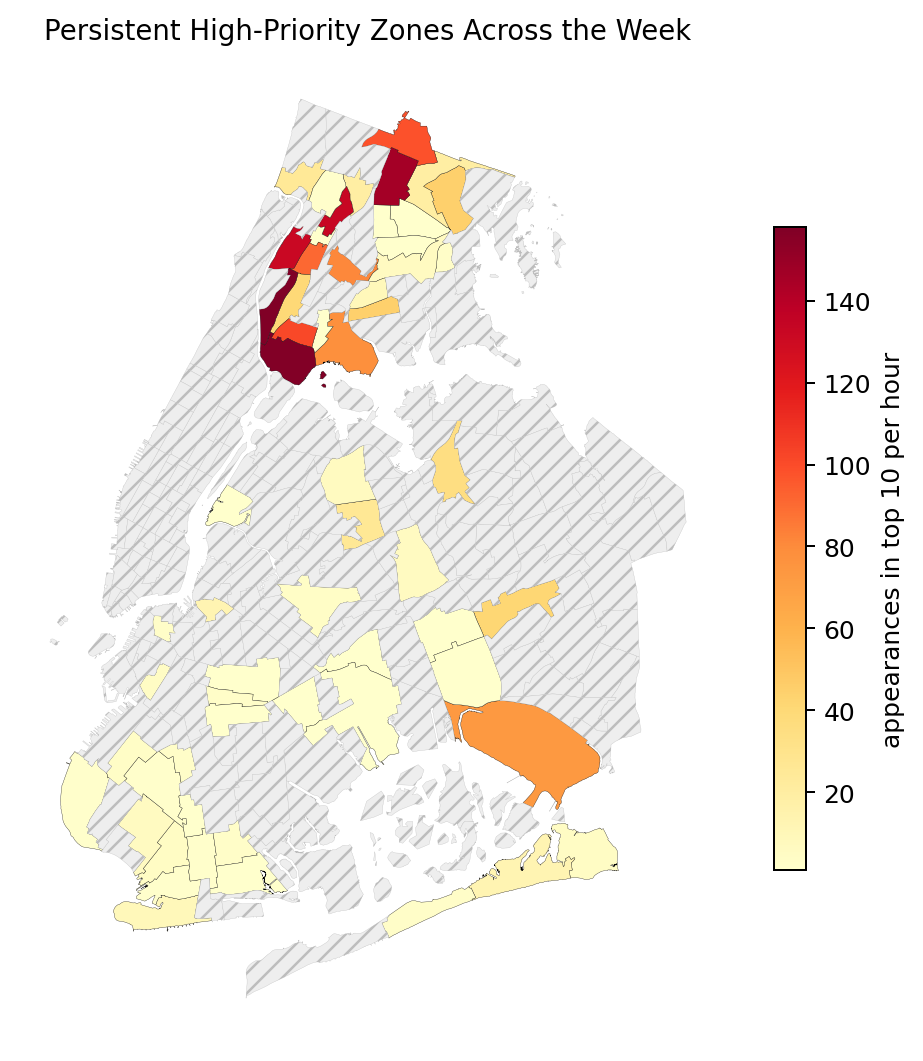

In [38]:
taxi_zones_path = "../data/raw/taxi_zones/taxi_zones.shp"
# Style for zones with no priority score or no validation data.
missing_kwds = {
    "color": "#eeeeee",
    "edgecolor": "#bdbdbd",
    "hatch": "///",
    "label": "No priority score",
}

# Load TLC zone geometries and align zone IDs with the modelling table.
zones_geo = gpd.read_file(taxi_zones_path)[["LocationID", "borough", "zone", "geometry"]].copy()
zones_geo = zones_geo[~zones_geo["borough"].isin(["Staten Island", "EWR"])]
zones_geo["PULocationID"] = zones_geo["LocationID"].astype(int).astype(str).str.zfill(3)

# Attach persistent priority scores to map each zone's repeated appearance.
persistent_map_geo = zones_geo.merge(
    persistent_priority_zones_pd,
    on="PULocationID",
    how="left",
    suffixes=("_shape", ""),
)

# Map zones that repeatedly appear in the top-priority set across the week.
fig, ax = plt.subplots(figsize=(6.5, 6), dpi=180)
persistent_map_geo.plot(
    ax=ax,
    column="n_top_hour_appearances",
    cmap="YlOrRd",
    edgecolor="black",
    linewidth=0.12,
    legend=True,
    missing_kwds=missing_kwds,
    legend_kwds={"shrink": 0.65, "label": f"appearances in top {TOP_ZONE_HOURS_PER_HOUR} per hour"},
)
ax.set_title("Persistent High-Priority Zones Across the Week", fontsize=11)
ax.axis("off")
plt.tight_layout()
plt.show()


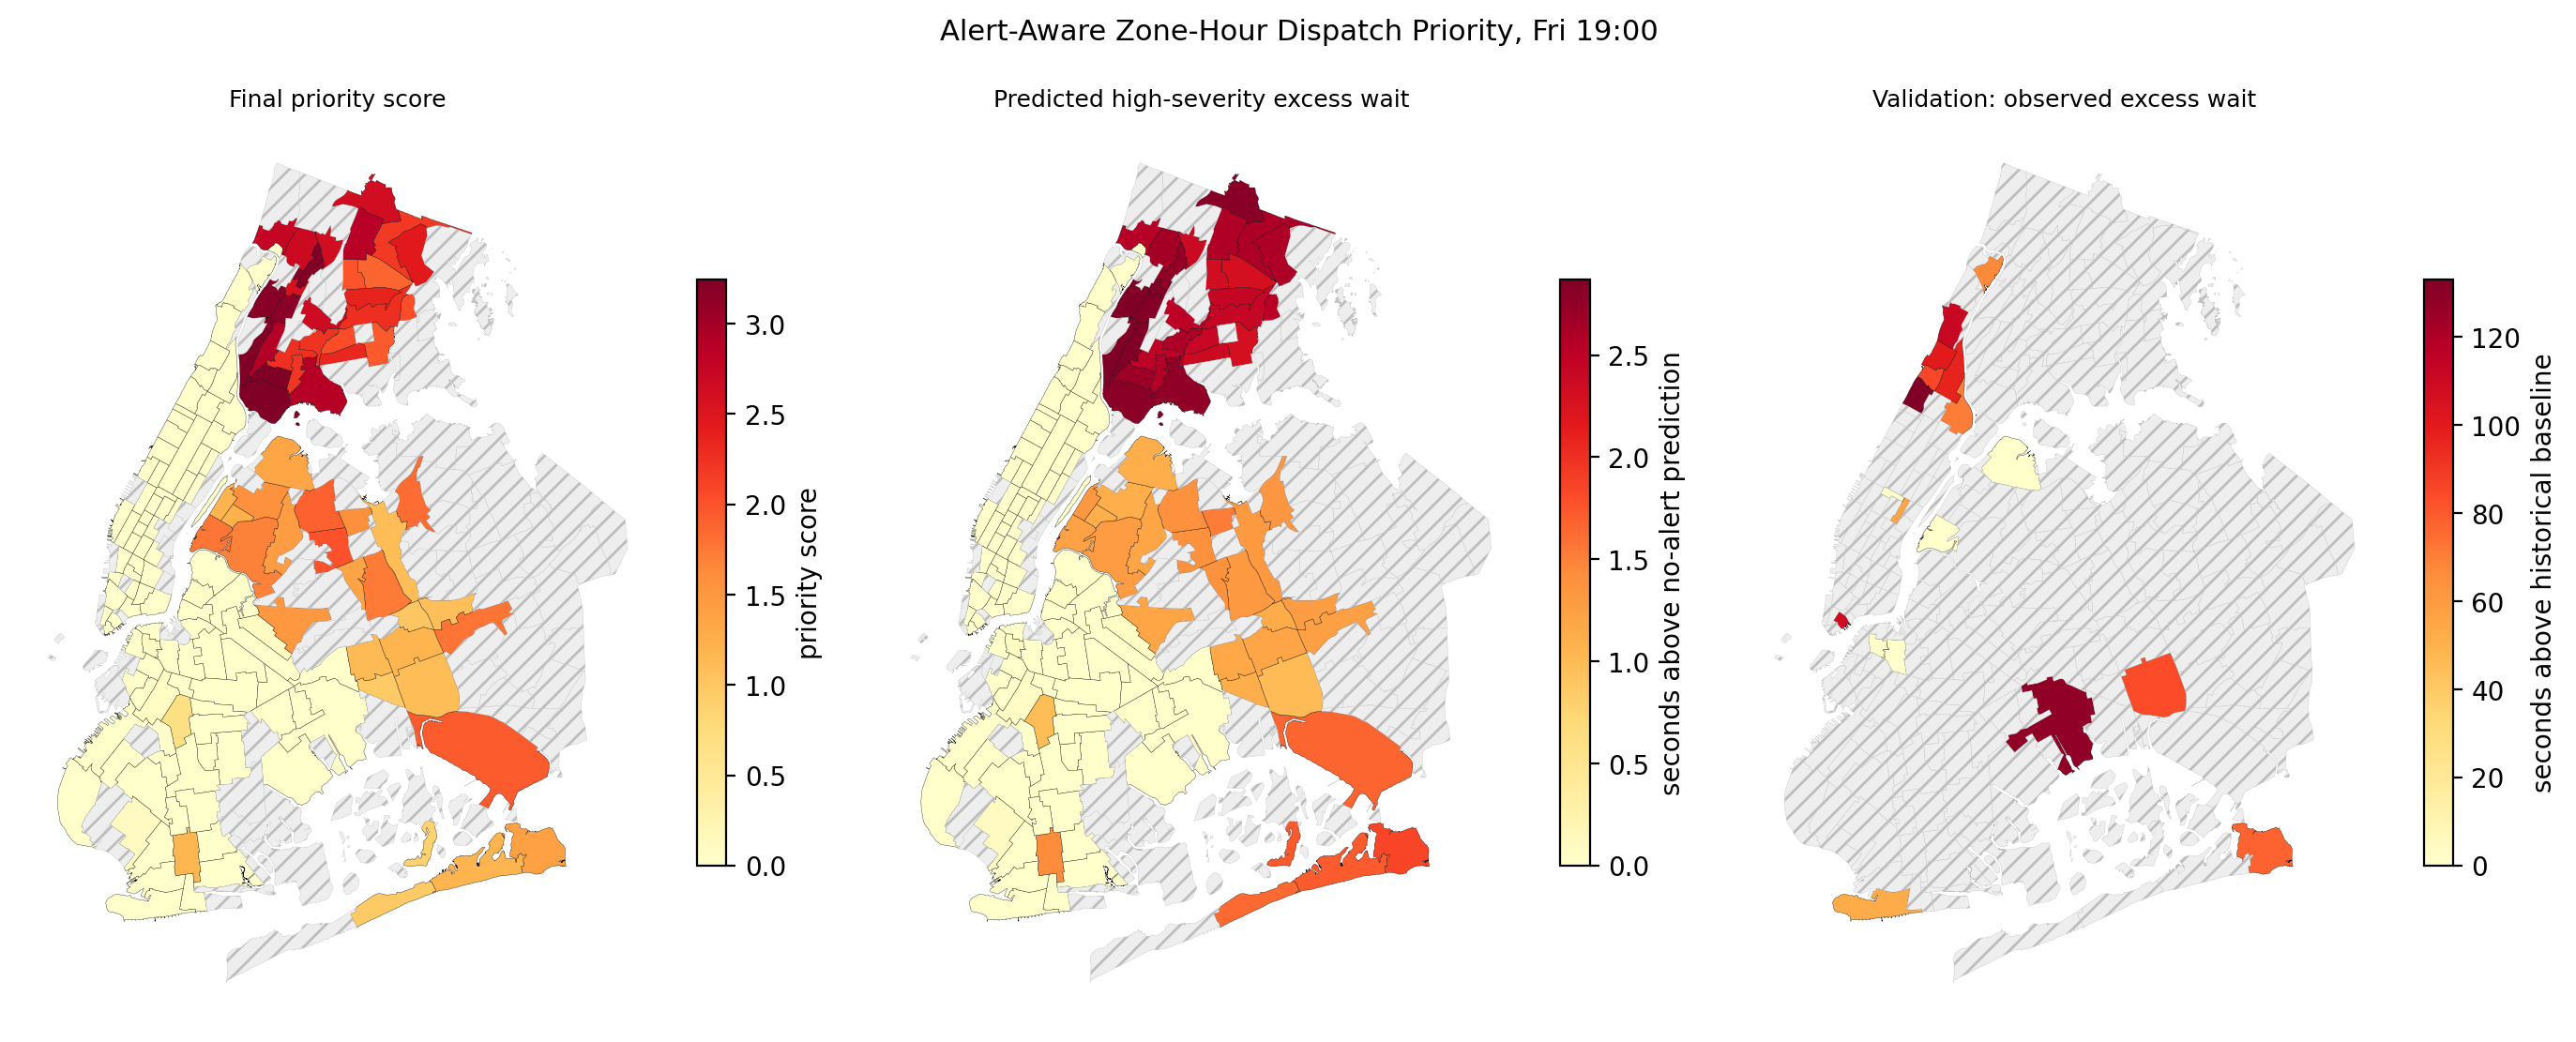

,global_priority_rank,PULocationID,taxi_zone,borough,day_name,hour_of_day,hour_of_week_int,priority_score,pred_excess_wait,pred_no_alert_wait,pred_high_severity_wait,typical_fhvhv_trips,typical_subway_ridership,demand_support,n_high_severity_validation_rows,mean_actual_excess_wait_validation,median_actual_excess_wait_validation
0,1,247,West Concourse,Bronx,Fri,19,115,3.922731,1.45,335.61,337.06,222.59,986.73,0.769492,NaN,NaN,NaN
3,4,168,Mott Haven/Port Morris,Bronx,Fri,19,115,3.585225,1.32,303.39,304.71,269.88,805.61,0.780437,NaN,NaN,NaN
8,9,018,Bedford Park,Bronx,Fri,19,115,3.277740,1.29,298.42,299.71,205.13,608.98,0.691906,NaN,NaN,NaN
11,12,159,Melrose South,Bronx,Fri,19,115,3.244737,1.27,293.59,294.86,195.74,723.17,0.701754,NaN,NaN,NaN
13,14,235,University Heights/Morris Heights,Bronx,Fri,19,115,3.190565,1.42,330.82,332.24,157.68,289.12,0.549528,NaN,NaN,NaN
16,17,169,Mount Hope,Bronx,Fri,19,115,3.157882,1.33,308.67,310.00,199.79,312.71,0.611930,NaN,NaN,NaN
47,48,069,East Concourse/Concourse Village,Bronx,Fri,19,115,2.890315,1.34,311.71,313.05,203.90,89.33,0.507078,NaN,NaN,NaN
51,52,126,Hunts Point,Bronx,Fri,19,115,2.880053,1.29,299.30,300.59,128.37,437.06,0.543497,NaN,NaN,NaN
56,57,254,Williamsbridge/Olinville,Bronx,Fri,19,115,2.851427,1.21,280.22,281.43,196.98,302.13,0.605204,NaN,NaN,NaN
89,90,220,Spuyten Duyvil/Kingsbridge,Bronx,Fri,19,115,2.754761,1.19,277.04,278.23,155.61,406.91,0.580298,NaN,NaN,NaN


In [39]:
# Choose the hour-of-week with the highest temporal priority unless manually set.
SELECT_HOUR_OF_WEEK = None
if SELECT_HOUR_OF_WEEK is None:
    SELECT_HOUR_OF_WEEK = int(temporal_priority_pd.iloc[0]["hour_of_week_int"])

selected_hour_priority_pd = priority_zone_hour_pd.query("hour_of_week_int == @SELECT_HOUR_OF_WEEK").copy()
selected_day = selected_hour_priority_pd["day_name"].iloc[0] if len(selected_hour_priority_pd) else ""
selected_hour = int(selected_hour_priority_pd["hour_of_day"].iloc[0]) if len(selected_hour_priority_pd) else 0

# Attach priority and validation values for the selected hour to zone shapes.
selected_hour_map_geo = zones_geo.merge(
    selected_hour_priority_pd,
    on="PULocationID",
    how="left",
    suffixes=("_shape", ""),
)

# Use separate scales because priority, predicted excess, and validation are different quantities.
map_specs = [
    {
        "col": "priority_score",
        "title": "Final priority score",
        "legend_label": "priority score",
        "vmin": 0,
        "vmax": max(selected_hour_priority_pd["priority_score"].quantile(0.98), 1e-6) if len(selected_hour_priority_pd) else 1,
    },
    {
        "col": "pred_excess_wait_pos",
        "title": "Predicted high-severity excess wait",
        "legend_label": "seconds above no-alert prediction",
        "vmin": 0,
        "vmax": max(selected_hour_priority_pd["pred_excess_wait_pos"].quantile(0.98), 1e-6) if len(selected_hour_priority_pd) else 1,
    },
    {
        "col": "mean_actual_excess_wait_validation",
        "title": "Validation: observed excess wait",
        "legend_label": "seconds above historical baseline",
        "vmin": 0,
        "vmax": max(selected_hour_priority_pd["mean_actual_excess_wait_validation"].quantile(0.98), 1e-6) if selected_hour_priority_pd["mean_actual_excess_wait_validation"].notna().any() else 1,
    },
]

fig, axes = plt.subplots(1, 3, figsize=(14, 5.4), dpi=200)

# Draw side-by-side maps to compare ranking, predicted excess, and observed validation.
for ax, spec in zip(axes, map_specs):
    selected_hour_map_geo.plot(
        ax=ax,
        column=spec["col"],
        cmap="YlOrRd",
        edgecolor="black",
        linewidth=0.12,
        legend=True,
        vmin=spec["vmin"],
        vmax=spec["vmax"],
        missing_kwds=missing_kwds,
        legend_kwds={"shrink": 0.65, "label": spec["legend_label"]},
    )
    ax.set_title(spec["title"], fontsize=9)
    ax.axis("off")

fig.suptitle(
    f"Alert-Aware Zone-Hour Dispatch Priority, {selected_day} {selected_hour:02d}:00",
    fontsize=11,
    y=1.02,
)
plt.tight_layout()
plt.show()

selected_hour_priority_pd[priority_zone_hour_cols].sort_values("priority_score", ascending=False).head(10)

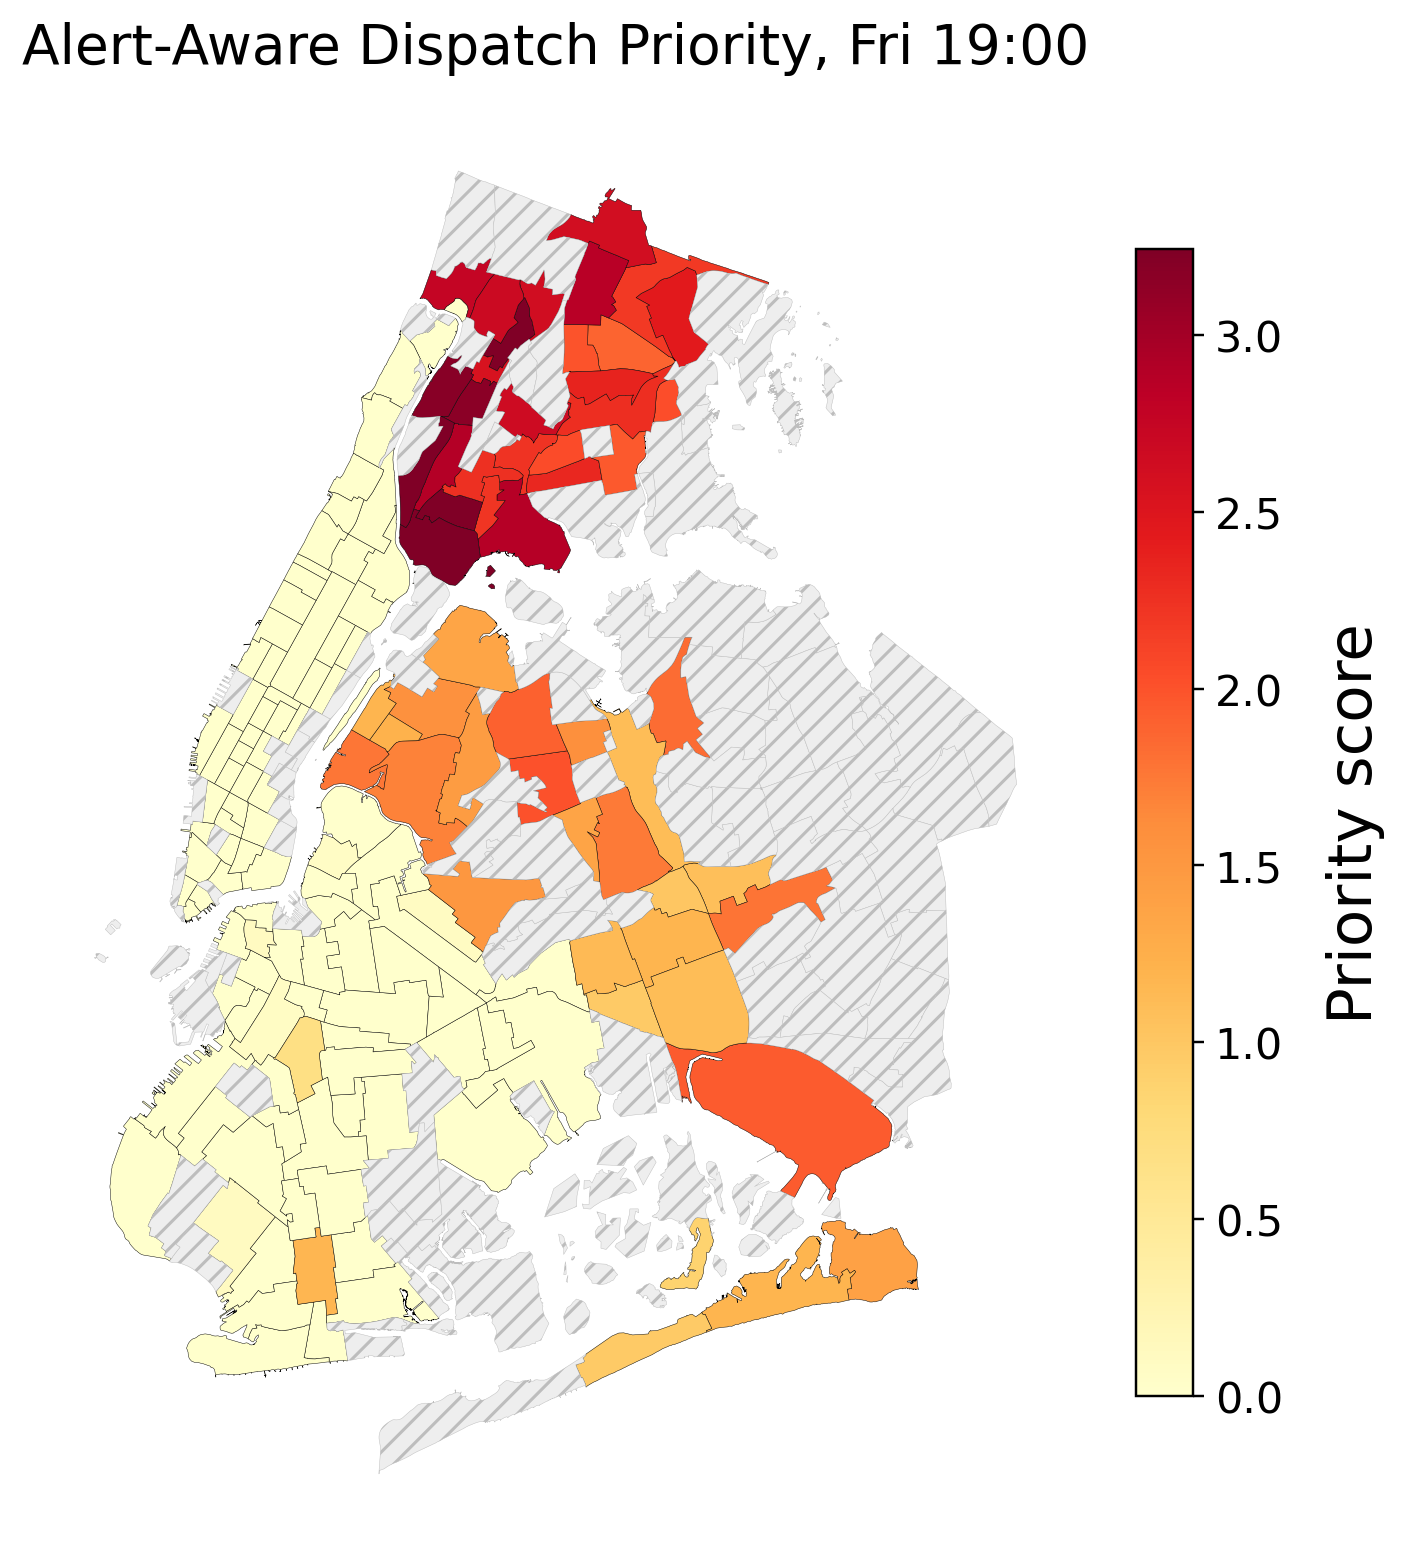

,global_priority_rank,PULocationID,taxi_zone,borough,day_name,hour_of_day,hour_of_week_int,priority_score,pred_excess_wait,pred_no_alert_wait,pred_high_severity_wait,typical_fhvhv_trips,typical_subway_ridership,demand_support,n_high_severity_validation_rows,mean_actual_excess_wait_validation,median_actual_excess_wait_validation
0,1,247,West Concourse,Bronx,Fri,19,115,3.922731,1.45,335.61,337.06,222.59,986.73,0.769492,NaN,NaN,NaN
3,4,168,Mott Haven/Port Morris,Bronx,Fri,19,115,3.585225,1.32,303.39,304.71,269.88,805.61,0.780437,NaN,NaN,NaN
8,9,018,Bedford Park,Bronx,Fri,19,115,3.277740,1.29,298.42,299.71,205.13,608.98,0.691906,NaN,NaN,NaN
11,12,159,Melrose South,Bronx,Fri,19,115,3.244737,1.27,293.59,294.86,195.74,723.17,0.701754,NaN,NaN,NaN
13,14,235,University Heights/Morris Heights,Bronx,Fri,19,115,3.190565,1.42,330.82,332.24,157.68,289.12,0.549528,NaN,NaN,NaN
16,17,169,Mount Hope,Bronx,Fri,19,115,3.157882,1.33,308.67,310.00,199.79,312.71,0.611930,NaN,NaN,NaN
47,48,069,East Concourse/Concourse Village,Bronx,Fri,19,115,2.890315,1.34,311.71,313.05,203.90,89.33,0.507078,NaN,NaN,NaN
51,52,126,Hunts Point,Bronx,Fri,19,115,2.880053,1.29,299.30,300.59,128.37,437.06,0.543497,NaN,NaN,NaN
56,57,254,Williamsbridge/Olinville,Bronx,Fri,19,115,2.851427,1.21,280.22,281.43,196.98,302.13,0.605204,NaN,NaN,NaN
89,90,220,Spuyten Duyvil/Kingsbridge,Bronx,Fri,19,115,2.754761,1.19,277.04,278.23,155.61,406.91,0.580298,NaN,NaN,NaN


In [48]:
# Trimmed plot version for report 

# Choose the hour-of-week to plot.
SELECT_HOUR_OF_WEEK = 115 # Mon 00:00 = 0, Tue 00:00 = 24, ..., Sun 23:00 = 167.

if SELECT_HOUR_OF_WEEK is None:
    SELECT_HOUR_OF_WEEK = int(temporal_priority_pd.iloc[0]["hour_of_week_int"])

selected_hour_priority_pd = priority_zone_hour_pd.query(
    "hour_of_week_int == @SELECT_HOUR_OF_WEEK"
).copy()

selected_day = selected_hour_priority_pd["day_name"].iloc[0] if len(selected_hour_priority_pd) else ""
selected_hour = int(selected_hour_priority_pd["hour_of_day"].iloc[0]) if len(selected_hour_priority_pd) else 0

# Join the selected priority scores to zone geometries for the report map.
selected_hour_map_geo = zones_geo.merge(
    selected_hour_priority_pd,
    on="PULocationID",
    how="left",
    suffixes=("_shape", ""),
)

# Set a robust upper bound so one extreme zone does not flatten the colour scale.
priority_vmax = (
    max(selected_hour_priority_pd["priority_score"].quantile(0.98), 1e-6)
    if len(selected_hour_priority_pd)
    else 1
)

# Plot only the final priority score for a cleaner report figure.
fig, ax = plt.subplots(1, 1, figsize=(7.2, 7.2), dpi=220)

selected_hour_map_geo.plot(
    ax=ax,
    column="priority_score",
    cmap="YlOrRd",
    edgecolor="black",
    linewidth=0.15,
    legend=True,
    vmin=0,
    vmax=priority_vmax,
    missing_kwds=missing_kwds,
    legend_kwds={
        "shrink": 0.8,
        "label": "Priority score",
    },
)

ax.set_title(
    f"Alert-Aware Dispatch Priority, {selected_day} {selected_hour:02d}:00",
    fontsize=18,
    pad=14,
)
ax.axis("off")

# Increase colourbar text size.
cbar = fig.axes[-1]
cbar.tick_params(labelsize=14)
cbar.set_ylabel("Priority score", fontsize=20, labelpad=14)

plt.tight_layout()
plt.show()

selected_hour_priority_pd[
    priority_zone_hour_cols
].sort_values("priority_score", ascending=False).head(10)

In [41]:
# Interactive plot by hour of week 
from ipywidgets import interact, Dropdown, IntSlider

day_to_idx = {"Mon": 0, "Tue": 1, "Wed": 2, "Thu": 3, "Fri": 4, "Sat": 5, "Sun": 6}

# Use stable colour scales across all hours so changes are comparable.
priority_vmax = max(priority_zone_hour_pd["priority_score"].quantile(0.98), 1e-6)
pred_excess_vmax = max(priority_zone_hour_pd["pred_excess_wait_pos"].quantile(0.98), 1e-6)

def plot_priority_hour(day_name="Fri", hour_of_day=19):
    """Plot priority, predicted excess wait, and validation for one hour."""
    selected_hour_of_week = day_to_idx[day_name] * 24 + hour_of_day

    # Filter to the selected weekly hour chosen by the widget controls.
    selected_hour_priority_pd = priority_zone_hour_pd.query(
        "hour_of_week_int == @selected_hour_of_week"
    ).copy()

    # Validation scale is based only on available observed high-severity rows.
    valid_selected_actual = selected_hour_priority_pd["mean_actual_excess_wait_validation"].dropna()
    selected_validation_vmax = (
        max(valid_selected_actual.quantile(0.98), 1e-6)
        if len(valid_selected_actual)
        else 1
        )

    # Attach selected-hour values to zone shapes for mapping.
    selected_hour_map_geo = zones_geo.merge(
        selected_hour_priority_pd,
        on="PULocationID",
        how="left",
        suffixes=("_shape", ""),
    )

    map_specs = [
        {
            "col": "priority_score",
            "title": "Final priority score",
            "legend_label": "priority score",
            "vmin": 0,
            "vmax": priority_vmax,
        },
        {
            "col": "pred_excess_wait_pos",
            "title": "Predicted high-severity excess wait",
            "legend_label": "seconds above no-alert prediction",
            "vmin": 0,
            "vmax": pred_excess_vmax,
        },
        {
            "col": "mean_actual_excess_wait_validation",
            "title": "Validation: observed excess wait",
            "legend_label": "seconds above historical baseline",
            "vmin": 0,
            "vmax": selected_validation_vmax,
        },
    ]

    fig, axes = plt.subplots(1, 3, figsize=(14, 5.4), dpi=180)

    # Draw the maps each time the selected day or hour changes.
    for ax, spec in zip(axes, map_specs):
        selected_hour_map_geo.plot(
            ax=ax,
            column=spec["col"],
            cmap="YlOrRd",
            edgecolor="black",
            linewidth=0.12,
            legend=True,
            vmin=spec["vmin"],
            vmax=spec["vmax"],
            missing_kwds=missing_kwds,
            legend_kwds={"shrink": 0.65, "label": spec["legend_label"]},
        )
        ax.set_title(spec["title"], fontsize=9)
        ax.axis("off")

    fig.suptitle(
        f"Alert-Aware Zone-Hour Dispatch Priority, {day_name} {hour_of_day:02d}:00",
        fontsize=12,
        y=1.02,
    )
    plt.tight_layout()
    plt.show()
    # Show the top ranked zones for the same selected hour.
    pd.set_option("display.max_columns", None)
    pd.set_option("display.width", None)
    pd.set_option("display.max_colwidth", 80)

    display(
        selected_hour_priority_pd[priority_zone_hour_cols]
        .sort_values("priority_score", ascending=False)
        .head(10)
    )

interact(
    plot_priority_hour,
    day_name=Dropdown(
        options=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
        value="Fri",
        description="Day",
    ),
    hour_of_day=IntSlider(
        value=19,
        min=0,
        max=23,
        step=1,
        description="Hour",
        continuous_update=False,
    ),
);

interactive(children=(Dropdown(description='Day', index=4, options=('Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', …

## Individual-Day Diagnostics for report

The selected days below include best, worst, high-severity, typical-error, and high-alert-volume days.


In [42]:
# Summarise alert-day prediction performance for selecting diagnostic examples.
daily_alert_perf_pd = (
    pred_test_residual
    .filter(F.col("has_alert") == 1)
    .withColumn("date", F.to_date("hour"))
    # Compute row-level errors before aggregating to the day level.
    .withColumn("abs_err", F.abs(F.col("pred_wait_seconds_resid") - F.col("avg_wait_time_fhvhv")))
    .withColumn("sq_err", F.pow(F.col("pred_wait_seconds_resid") - F.col("avg_wait_time_fhvhv"), 2))
    .groupBy("date")
    .agg(
        F.count("*").alias("n_zone_hours"),
        F.countDistinct("PULocationID").alias("n_zones"),
        F.round(F.avg("avg_wait_time_fhvhv"), 2).alias("actual_mean_wait"),
        F.round(F.avg("pred_wait_seconds_resid"), 2).alias("pred_mean_wait"),
        F.round(F.avg(F.col("pred_wait_seconds_resid") - F.col("avg_wait_time_fhvhv")), 2).alias("mean_error_pred_minus_actual"),
        F.round(F.avg("abs_err"), 2).alias("mae_seconds"),
        F.round(F.sqrt(F.avg("sq_err")), 2).alias("rmse_seconds"),
        F.round(F.avg("disruption_severity"), 2).alias("mean_disruption_severity"),
        F.max("disruption_severity").alias("max_disruption_severity"),
        F.round(F.avg("n_alerts"), 2).alias("mean_n_alerts"),
        F.max("n_alerts").alias("max_n_alerts"),
    )
    .orderBy("date")
    .toPandas()
)

print(f"2026 alert days: {len(daily_alert_perf_pd)}")
daily_alert_perf_pd.head(10)


2026 alert days: 146


,date,n_zone_hours,n_zones,actual_mean_wait,pred_mean_wait,mean_error_pred_minus_actual,mae_seconds,rmse_seconds,mean_disruption_severity,max_disruption_severity,mean_n_alerts,max_n_alerts
0,2026-01-01,101,60,356.29,268.92,-87.37,95.43,122.96,1.43,3,1.01,2
1,2026-01-02,89,50,278.82,270.69,-8.13,31.70,39.76,1.40,3,1.01,2
2,2026-01-03,86,51,275.22,264.04,-11.18,32.05,49.08,1.44,4,1.02,2
3,2026-01-04,76,44,266.23,276.40,10.17,31.83,42.25,1.59,3,1.01,2
4,2026-01-05,104,56,277.93,259.77,-18.16,36.25,68.32,1.57,5,1.03,2
5,2026-01-06,129,65,269.10,260.43,-8.67,33.35,43.28,1.36,4,1.04,2
6,2026-01-07,131,64,274.64,276.97,2.34,26.50,39.11,1.60,3,1.02,3
7,2026-01-08,113,58,256.13,265.59,9.47,30.49,39.02,1.48,6,1.06,3
8,2026-01-09,119,59,288.01,292.10,4.10,38.79,62.56,1.45,4,1.07,2
9,2026-01-10,120,61,282.85,283.00,0.14,30.16,41.02,1.58,4,1.03,2


In [43]:
# Pick a compact but diverse set of alert days to inspect.
# Each criterion takes the best unused day, so duplicate criteria do not collapse the plot set.
candidate_days = daily_alert_perf_pd[daily_alert_perf_pd["n_zone_hours"] >= 50].copy()
selected_alert_dates = []
selection_reason = {}

selection_specs = [
    ("highest alert volume", "n_zone_hours", False),
    ("highest mean severity", "mean_disruption_severity", False),
    ("largest MAE", "mae_seconds", False),
    ("smallest MAE", "mae_seconds", True),
]

for reason, col, ascending in selection_specs:
    if candidate_days.empty:
        continue
    for _, row in candidate_days.sort_values(col, ascending=ascending).iterrows():
        day = str(row["date"])
        if day not in selected_alert_dates:
            selected_alert_dates.append(day)
            selection_reason[day] = reason
            break

if not candidate_days.empty:
    median_mae = candidate_days["mae_seconds"].median()
    candidate_days["distance_to_median_mae"] = (candidate_days["mae_seconds"] - median_mae).abs()
    for _, row in candidate_days.sort_values("distance_to_median_mae").iterrows():
        day = str(row["date"])
        if day not in selected_alert_dates:
            selected_alert_dates.append(day)
            selection_reason[day] = "typical MAE"
            break

selected_alert_days_pd = daily_alert_perf_pd[
    daily_alert_perf_pd["date"].astype(str).isin(selected_alert_dates)
].copy()
selected_alert_days_pd["selection_reason"] = selected_alert_days_pd["date"].astype(str).map(selection_reason)
selected_alert_days_pd = selected_alert_days_pd.sort_values("date")

selected_alert_days_pd


,date,n_zone_hours,n_zones,actual_mean_wait,pred_mean_wait,mean_error_pred_minus_actual,mae_seconds,rmse_seconds,mean_disruption_severity,max_disruption_severity,mean_n_alerts,max_n_alerts,selection_reason
12,2026-01-13,109,49,242.04,241.15,-0.89,18.85,25.40,1.49,6,1.03,3,smallest MAE
18,2026-01-19,60,41,281.70,251.69,-30.01,40.29,51.54,1.22,2,1.03,2,typical MAE
24,2026-01-25,129,61,599.12,348.14,-250.98,264.42,323.01,1.90,4,1.04,2,largest MAE
25,2026-01-26,156,67,460.25,278.31,-181.94,181.94,224.20,1.92,6,1.04,2,highest mean severity
52,2026-02-23,193,72,732.94,312.78,-420.16,420.84,482.69,1.95,7,1.07,3,highest alert volume


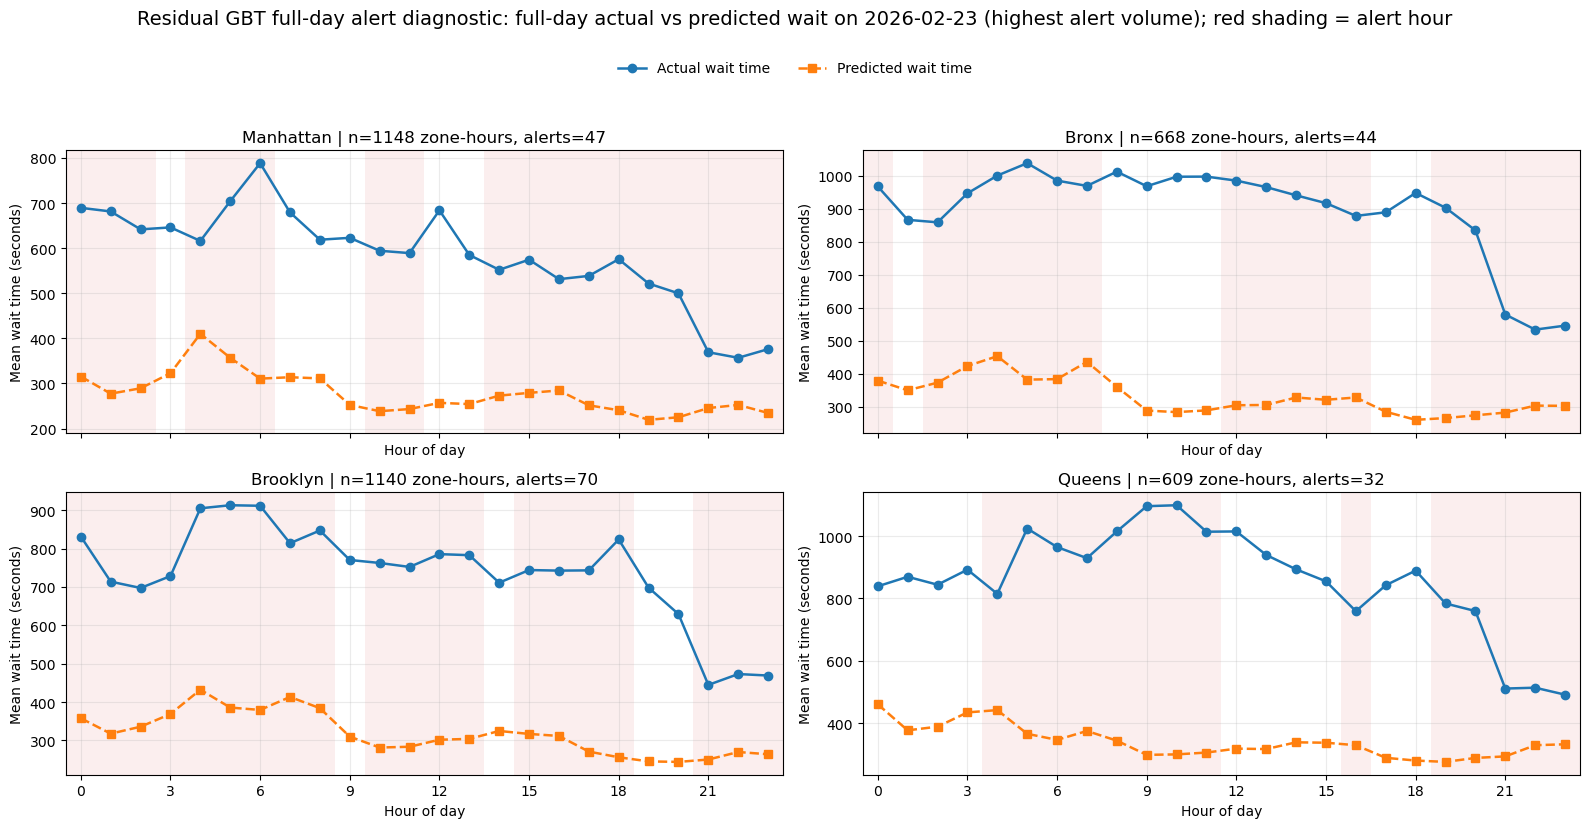

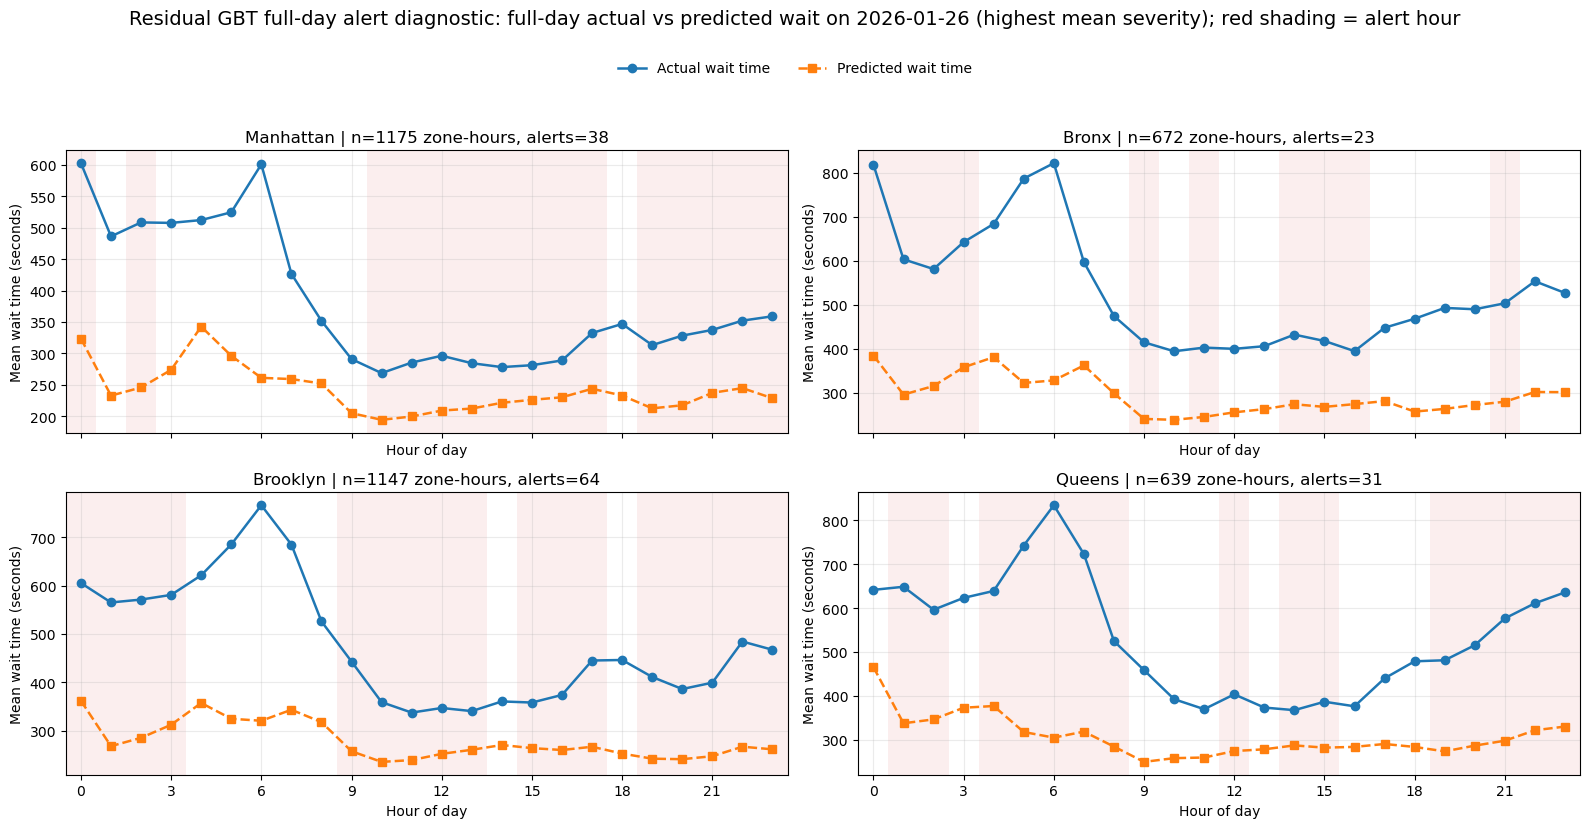

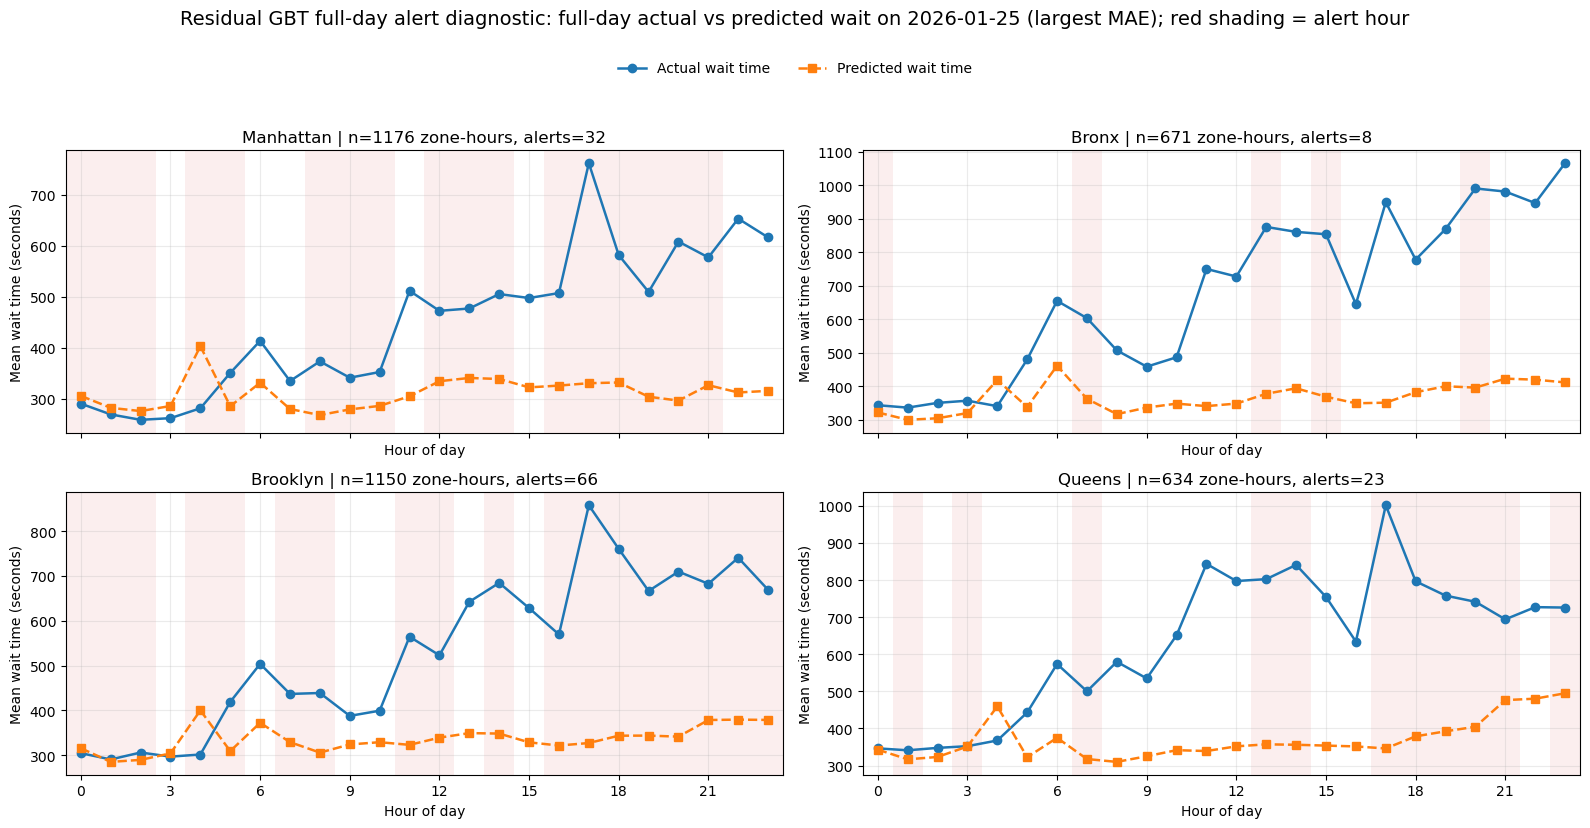

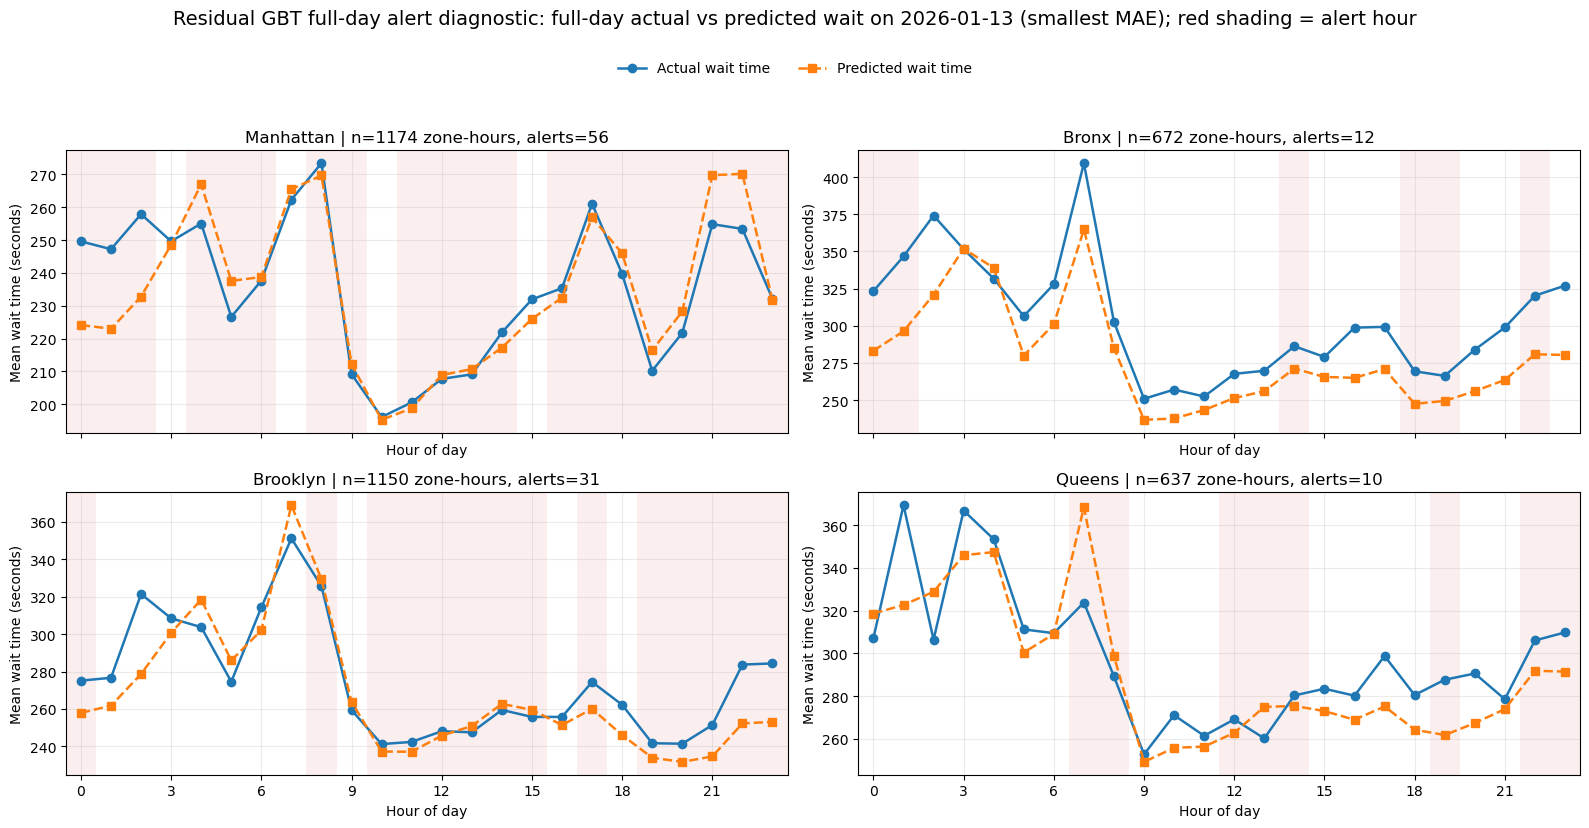

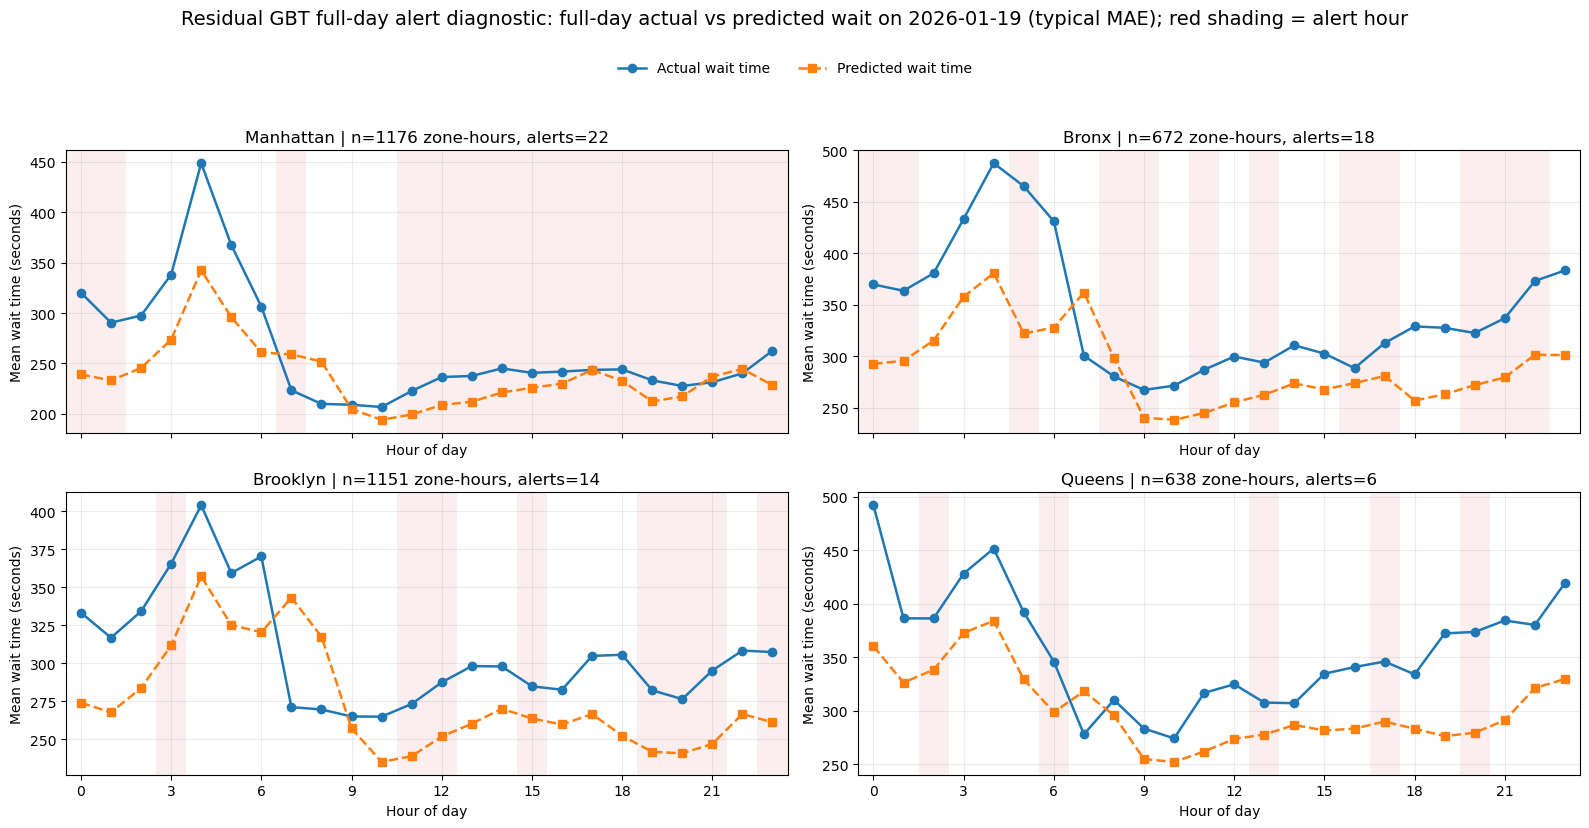

In [44]:
def plot_full_alert_days(pred_df, selected_dates, title_prefix="Residual GBT", prediction_col="pred_wait_seconds_resid"):
    """
    Plot full-day actual and predicted wait time for selected alert dates
    """
    borough_order = ["Manhattan", "Bronx", "Brooklyn", "Queens"]

    for selected_date in selected_dates:
        # Average all zone rows within each borough-hour for a readable daily plot.
        day_pd = (
            pred_df
            .filter(F.to_date("hour") == F.lit(selected_date))
            .groupBy("borough", "hour_of_day")
            .agg(
                F.avg("avg_wait_time_fhvhv").alias("actual_wait"),
                F.avg(prediction_col).alias("pred_wait"),
                F.count("*").alias("n_zone_rows"),
                F.sum(F.col("has_alert").cast("int")).alias("n_alert_zone_rows"),
                F.avg("disruption_severity").alias("mean_disruption_severity"),
                F.max("disruption_severity").alias("max_disruption_severity"),
            )
            .toPandas()
        )

        if day_pd.empty:
            print(f"No rows found for {selected_date}")
            continue

        fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True, sharey=False)
        axes = axes.flatten()

        for ax, borough in zip(axes, borough_order):
            # Plot each borough separately because wait patterns differ spatially.
            bdf = day_pd[day_pd["borough"] == borough].copy()
            if bdf.empty:
                ax.set_title(f"{borough} (no rows)")
                ax.set_xlim(0, 23)
                ax.grid(True, alpha=0.25)
                continue

            # Reindex to all 24 hours so missing hours appear as gaps, not connected lines.
            bdf = (
                bdf.set_index("hour_of_day")
                .reindex(range(24))
                .rename_axis("hour_of_day")
                .reset_index()
            )

            alert_hours = bdf.loc[bdf["n_alert_zone_rows"].fillna(0) > 0, "hour_of_day"].tolist()
            # Red shading marks hours where alert rows are present.
            for hour_value in alert_hours:
                ax.axvspan(hour_value - 0.5, hour_value + 0.5, color="tab:red", alpha=0.08, linewidth=0)

            ax.plot(bdf["hour_of_day"], bdf["actual_wait"], marker="o", linewidth=1.8, label="Actual wait time")
            ax.plot(bdf["hour_of_day"], bdf["pred_wait"], marker="s", linewidth=1.8, linestyle="--", label="Predicted wait time")

            total_rows = int(bdf["n_zone_rows"].fillna(0).sum())
            total_alert_rows = int(bdf["n_alert_zone_rows"].fillna(0).sum())
            ax.set_title(f"{borough} | n={total_rows} zone-hours, alerts={total_alert_rows}")
            ax.set_xlim(-0.5, 23.5)
            ax.set_xticks(range(0, 24, 3))
            ax.set_xlabel("Hour of day")
            ax.set_ylabel("Mean wait time (seconds)")
            ax.grid(True, alpha=0.25)

        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.98))
        reason = selection_reason.get(str(selected_date), "selected alert day")
        fig.suptitle(f"{title_prefix}: full-day actual vs predicted wait on {selected_date} ({reason}); red shading = alert hour", fontsize=14, y=1.03)
        fig.tight_layout(rect=[0, 0, 1, 0.94])
        plt.show()


plot_full_alert_days(
    pred_test_residual,
    selected_alert_dates,
    title_prefix="Residual GBT full-day alert diagnostic",
    prediction_col="pred_wait_seconds_resid",
)


## Interpretation Notes

### Model Setup and Prediction Logic

The residual GBT predicts FHVHV average wait time using a two-part structure. First, the usual historical zone-hour wait pattern is represented using the 2025 historical baseline. The model then predicts the remaining deviation from this baseline using zone, borough, calendar, weather, station, and disruption-related features.

For row $i$, the model target is:

$$
y_i^{resid}
=
\log(1 + W_i) - B_i
$$

where $W_i$ is observed FHVHV average wait time and $B_i$ is the 2025 historical log wait baseline for the same pickup zone and hour-of-week. The fitted GBT predicts:

$$
\widehat{y}_i^{resid}
=
f(X_i)
$$

The final prediction is reconstructed as:

$$
\widehat{\log(1 + W_i)}
=
B_i + \widehat{y}_i^{resid}
$$

and converted back to seconds using a smearing factor estimated from 2025 training residuals only.

The model is more flexible than linear regression because it can learn non-linear relationships and interactions without explicitly specifying every coefficient. However, it is less directly interpretable and should not be treated as a causal model.

### Model Evaluation

- The model is evaluated on individual zone-hour rows, not on aggregated plots. The main 2026 test metrics show moderate predictive performance overall, but weaker performance during alert and high-severity rows.

- The hour-of-week plots show that the model captures regular temporal wait-time patterns, especially the broad weekly cycle. However, the model is conservative: it tends to underpredict large wait-time spikes, particularly during rare high-severity disruption periods.

- This means the GBT is useful for identifying broad high-risk zone-hour patterns, but it should not be described as accurately predicting the exact magnitude of disruption-driven wait increases.

### Diagnostics and Priority Score

The priority analysis uses the fitted GBT as a dispatch screening tool. For each 2026 zone-hour, the model predicts wait time under two alert scenarios:

$$
\widehat{W}^{no\ alert}_{z,h} \quad \text{and}\quad \widehat{W}^{high\ severity}_{z,h}
$$

The predicted excess wait is:

$$
\widehat{\Delta W}_{z,h}
=
\widehat{W}^{high\ severity}_{z,h}
-
\widehat{W}^{no\ alert}_{z,h}
$$

The priority score is:

$$
\text{Priority}_{z,h}
=
\max(\widehat{\Delta W}_{z,h}, 0)
\times
\left(0.5 + \text{DemandSupport}_{z,h}\right)
$$

where:

$$
\text{DemandSupport}_{z,h}
=
0.5 \cdot \text{pctile}(\text{typical FHVHV trips}_{z,h})
+
0.5 \cdot \text{pctile}(\text{typical subway ridership}_{z,h})
$$

This score prioritises zone-hours where the model predicts additional wait under high-severity disruption and where historical demand/ridership suggests operational importance.

Validation columns compare the model-ranked zone-hours against observed 2026 high-severity excess wait where available. These validation values are not used to construct the priority score.

### Recommendations

- The model should be used as a risk-screening tool rather than as an exact wait-time forecasting tool. Its main practical value is identifying zone-hours that repeatedly appear as high-priority under severe disruption scenarios.

- A plausible recommendation is that FHVHV dispatchers should monitor and pre-position additional supply in repeatedly high-priority outer-borough zones, especially during high-risk hours of the week. This is consistent with the linear regression finding that wait times increase more sharply with disruption severity in the Bronx, Brooklyn, and Queens than in Manhattan.

- The priority maps and persistent-zone tables can support more spatially specific recommendations. For example, if Bronx zones such as West Concourse, Mott Haven/Port Morris, Williamsbridge/Olinville, Bedford Park, or University Heights/Morris Heights repeatedly appear in the top priority list, they can be framed as candidate zones for targeted alert-period dispatch monitoring.

- The temporal priority table can support a second operational recommendation: dispatchers should not treat all alert periods equally, but should focus additional monitoring around recurring high-risk hours such as weekday morning peaks or Friday evening periods if these appear consistently in the model output.

### Limitations

- The model underpredicts rare high-severity spikes, which suggests that the available alert variables do not fully capture the operational mechanisms behind severe disruption impacts. Disruption severity is also an engineered feature, so any noise in its construction may weaken predictive performance.

- Because high-severity validation rows are sparse at exact zone-hour granularity, the validation maps are incomplete and should be interpreted cautiously. Missing validation does not mean zero excess wait; it means that no observed high-severity case was available for that exact zone-hour in the 2026 test period.

- Overall, the GBT is best presented as a predictive screening and prioritisation model, while the linear regression model provides the stronger statistical evidence for the relationship between subway disruption severity and borough-level wait-time increases.